In [1]:
import pandas as pd
import numpy as np
import glob
import os
import ast
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
# import glasbey
import colorsys
from collections import defaultdict
# from matplotlib.patches import Patch, Wedge
from matplotlib.path import Path
import matplotlib.patches as patches
import textwrap
import matplotlib.cm as cm
import colorcet as cc
from matplotlib.patches import Patch
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from skbio.stats.composition import clr, multi_replace, clr_inv
import networkx as nx
from itertools import combinations
from scipy.spatial.distance import pdist
import itertools
import re
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests
from scipy.spatial.distance import pdist, squareform
from sklearn.manifold import MDS
from scipy.spatial.distance import cdist
from skbio.stats.distance import permanova
from skbio.stats.distance import permdisp



In [2]:
mpl.rcParams.update({
    'font.family': 'Arial',
    'font.size': 11,
    'axes.titlesize': 11,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
})

In [3]:
def parse_list_column(val):
    if isinstance(val, (list, tuple, np.ndarray)):
        return list(val)
    if val is None or pd.isna(val) or val == '[]' or val == '':
        return []
    try:
        return ast.literal_eval(str(val))
    except (ValueError, SyntaxError):
        return [str(val)]

In [4]:
def get_mge_labels(row):
    labels = set()

    # IS
    ts_fam = parse_list_column(row.get('true_standalone_is_family'))
    for fam in ts_fam:
        if fam not in (None, '', 'nan'):
            labels.add((str(fam), str(fam)))

    # Composite transposon
    if str(row.get('composite_transposon', '')).strip() == 'composite_transposon':
        b_fams = parse_list_column(row.get('bounding_IS_families'))
        for entry in b_fams:
            if isinstance(entry, list):
                key = '+'.join(str(f) for f in entry if f not in (None, ''))
            else:
                key = str(entry)
            if key:
                labels.add(('composite_transposon', key))

    # tn3 / tn554 / tn7 / integron
    for mge_type, genes_col in [
        ('tn3',      'tn3_genes'),
        ('tn554',    'tn554_genes'),
        ('tn7',      'tn7_genes'),
        ('integron', 'integron_genes'),
    ]:
        genes = parse_list_column(row.get(genes_col))
        if any(v not in (None, '', 'nan', float('nan')) for v in genes):
            labels.add((mge_type, mge_type))

    return labels


# Pairing ARGs with MGE labels. A composite transposon only carries the ARGs between its two bounding IS
# (bounding_IS_arg_indices); every other MGE on the read (standalone IS, unit Tn, integron) is paired with every ARG on the read.
PAIR_COLS = ["mge_labels", "composite_transposon", "bounding_IS_families", "bounding_IS_arg_indices"]


def composite_arg_scope(row):
    # bounding-family label (as in get_mge_labels) -> indices of the ARG hits that composite bounds
    scope = {}
    if str(row.get('composite_transposon', '')).strip() != 'composite_transposon':
        return scope
    fams = parse_list_column(row.get('bounding_IS_families'))
    arg_idx = parse_list_column(row.get('bounding_IS_arg_indices'))
    for entry, idx in zip(fams, arg_idx):
        if isinstance(entry, list):
            key = '+'.join(str(f) for f in entry if f not in (None, ''))
        else:
            key = str(entry)
        if key and idx:
            scope.setdefault(key, set()).update(int(i) for i in idx)
    return scope


def pair_args_with_mge_labels(row, per_arg_values, labels=None):
    # [(arg_value, mge_label)] for one read; per_arg_values[i] lists the values of ARG hit i
    if labels is None:
        labels = get_mge_labels(row)
    scope = composite_arg_scope(row)
    every_arg = range(len(per_arg_values))
    pairs = []
    for label in labels:
        idx = sorted(scope.get(label[1], ())) if label[0] == 'composite_transposon' else every_arg
        for i in idx:
            if i < len(per_arg_values):
                pairs.extend((v, label) for v in per_arg_values[i])
    return pairs


def per_arg_genes(value):
    # arg_genes cell -> one [gene] per ARG hit
    return [[g] for g in parse_list_column(value)]


def explode_arg_mge_pairs(df, value_col, per_arg_fn, keep_cols):
    # one row per (read, ARG value, MGE label), carrying keep_cols
    keep_cols = list(keep_cols)
    sub = df[list(dict.fromkeys([*keep_cols, value_col, *PAIR_COLS]))]
    pairs = [pair_args_with_mge_labels(r, per_arg_fn(r[value_col]), r["mge_labels"])
             for r in sub.to_dict("records")]
    out = sub[keep_cols].copy()
    out["pairs"] = pairs
    out = out.explode("pairs").dropna(subset=["pairs"])
    out["arg_values"] = out["pairs"].str[0]
    out["mge_labels"] = out["pairs"].str[1]
    return out.drop(columns="pairs")


In [5]:
def calc_length(coord):
    if isinstance(coord, (list, tuple)) and len(coord) == 2:
        return abs(float(coord[1]) - float(coord[0])) + 1
    return 0

In [6]:
def get_compositional_mean(df):
    X = df.T.values.astype(float)
    
    X = multi_replace(X)
    clr_transformed = clr(X)
    
    comp_mean = clr_inv(clr_transformed.mean(axis=0))
    
    return pd.DataFrame(comp_mean, index=df.index, columns=['compositional_mean'])

In [7]:
df_all = pd.read_csv("../final_supplementary/raw_new.csv")

C:\Users\Daphne Go\AppData\Local\Temp\ipykernel_4460\1527878152.py:1: DtypeWarning: Columns (0: bounding_IS_families, 1: bounding_IS_coords, 2: bounding_IS_evalues, 3: bounding_IS_reference_coverages, 4: bounding_IS_arg_indices, 5: bounding_IS_names, 6: IS_coords_modified, 7: IS_family_modified, 8: IS_names_modified, 9: IS_reference_coverages_modified, 10: IS_evalues_modified, 11: tn3_coords, 12: tn3_functions, 13: tn3_genes, 14: tn3_evalues, 15: tn3_reference_coverages, 16: tn7_coords, 17: tn7_functions, 18: tn7_genes, 19: tn7_evalues, 20: tn7_reference_coverages, 21: tn554_coords, 22: tn554_functions, 23: tn554_genes, 24: tn554_evalues, 25: tn554_reference_coverages) have mixed types. Specify dtype option on import or set low_memory=False.
  df_all = pd.read_csv("../final_supplementary/raw_new.csv")


In [8]:
# Sanity Check
df_all["Sample"].nunique()

40

### ARG Filtering

#### Reference Coverage Filtering

In [9]:
def filter_args_by_coverage(df_orig, min_coverage=0.5):
    # Filters rows based on arg_reference_coverage. 
    # Updates other ARG columns, drops rows with 0 ARGs, and clears composite transposon data if a bounded ARG is removed.
    df = df_orig.copy()
    arg_cols = [
        'arg_coords', 'arg_accessions', 'arg_evalues', 'arg_genes',
        'arg_class', 'arg_mechanism', 'arg_strand', 'arg_reference_coverage'
    ]

    for col in arg_cols:
        if col in df.columns:
            df[col] = df[col].apply(parse_list_column)
    filtered_rows = []
    for _, row in df.iterrows():
        coverages = row.get('arg_reference_coverage', [])
        
        valid_indices = [
            i for i, cov in enumerate(coverages) 
            if pd.notna(cov) and cov >= min_coverage
        ]
        
        dropped_indices = [i for i in range(len(coverages)) if i not in valid_indices]
        
        if not valid_indices:
            continue
            
        if dropped_indices:
            
            for col in arg_cols:
                if col in df.columns and isinstance(row[col], list):
                    row[col] = [row[col][i] for i in valid_indices if i < len(row[col])]
            
            row['num_args'] = len(valid_indices)
        
        for col in arg_cols:
            if col in df.columns and isinstance(row[col], list):
                row[col] = str(row[col])

        filtered_rows.append(row)

    return pd.DataFrame(filtered_rows)

In [10]:
filtered_df = filter_args_by_coverage(df_all, min_coverage=0.5)
total_args_after_coverage = filtered_df['num_args'].sum()
print(f"Total ARGs after coverage filtering: {total_args_after_coverage}")

Total ARGs after coverage filtering: 4068072


#### E-Value Filtering

In [11]:
def filter_args_by_eval(df_orig, min_evalue=1e-5):
    # Filters rows based on arg_evalues. 
    # Updates other ARG columns, drops rows with 0 ARGs, and clears composite transposon data if a bounded ARG is removed.
    df = df_orig.copy()
    arg_cols = [
        'arg_coords', 'arg_accessions', 'arg_evalues', 'arg_genes',
        'arg_class', 'arg_mechanism', 'arg_strand', 'arg_reference_coverage'
    ]

    for col in arg_cols:
        if col in df.columns:
            df[col] = df[col].apply(parse_list_column)

    filtered_rows = []

    for _, row in df.iterrows():
        evalues = row.get('arg_evalues', [])
        
        valid_indices = [
            i for i, ev in enumerate(evalues)
            if pd.notna(ev) and ev <= min_evalue
        ]
        
        dropped_indices = [i for i in range(len(evalues)) if i not in valid_indices]
        
        # If no ARGs meet the threshold, drop the entire row
        if not valid_indices:
            continue
            
        # If some ARGs were filtered out, process the updates
        if dropped_indices:            
            # Filter the other ARG columns keeping only valid indices
            for col in arg_cols:
                if col in df.columns and isinstance(row[col], list):
                    row[col] = [row[col][i] for i in valid_indices if i < len(row[col])]
            
            row['num_args'] = len(valid_indices)
        for col in arg_cols:
            if col in df.columns and isinstance(row[col], list):
                row[col] = str(row[col])

        filtered_rows.append(row)

    return pd.DataFrame(filtered_rows)

In [12]:
filtered_df = filter_args_by_eval(filtered_df, 1e-5)
total_args_after_eval = filtered_df['num_args'].sum()
print(f"Total ARGs after E-value filtering: {total_args_after_eval}")

Total ARGs after E-value filtering: 3938325


### MGE Filtering

#### Reference Coverage Filtering

In [13]:

def filter_mges_by_coverage(df_orig, min_coverage=0.5):
    #Filters MGEs based on their reference coverage. Retains rows even if empty.
    df = df_orig.copy()
    mge_groups = {
        'IS': ['IS_coords', 'IS_family', 'IS_names', 'IS_evalues', 'IS_reference_coverages'],
        'tn3': ['tn3_coords', 'tn3_functions', 'tn3_genes', 'tn3_evalues', 'tn3_reference_coverages'],
        'tn7': ['tn7_coords', 'tn7_functions', 'tn7_genes', 'tn7_evalues', 'tn7_reference_coverages'],
        'tn554': ['tn554_coords', 'tn554_functions', 'tn554_genes', 'tn554_evalues', 'tn554_reference_coverages'],
        'integron': ['integron_coords', 'integron_functions', 'integron_genes','integron_evalues', 'integron_reference_coverages']
    }

    all_cols_to_parse = [col for cols in mge_groups.values() for col in cols]

    for col in all_cols_to_parse:
        if col in df.columns:
            df[col] = df[col].apply(parse_list_column)

    for idx, row in df.iterrows():
        for mge, cols in mge_groups.items():
            cov_col = f'{mge}_reference_coverages'
            
            if cov_col not in df.columns:
                continue
                
            coverages = row.get(cov_col, [])
            valid_indices = [
                i for i, cov in enumerate(coverages) 
                if pd.notna(cov) and cov >= min_coverage
            ]
            
            dropped_indices = [i for i in range(len(coverages)) if i not in valid_indices]
            
            if not dropped_indices:
                continue
            
            
            # Filter all columns for this MGE type
            for col in cols:
                if col in df.columns and isinstance(row.get(col), list):
                    df.at[idx, col] = [row.get(col)[i] for i in valid_indices if i < len(row.get(col))]
        

        for col in all_cols_to_parse:
            if col in df.columns and isinstance(df.at[idx, col], list):
                df.at[idx, col] = str(df.at[idx, col])

    return df


In [14]:
filtered_df_mge = filter_mges_by_coverage(filtered_df, 0.5)

#### E-Value Filtering

In [15]:
def filter_mges_by_eval(df_orig, min_evalue=1e-5):
    df = df_orig.copy()
    mge_groups = {
        'IS': ['IS_coords', 'IS_family', 'IS_names', 'IS_evalues', 'IS_reference_coverages'],
        'tn3': ['tn3_coords', 'tn3_functions', 'tn3_genes', 'tn3_evalues', 'tn3_reference_coverages'],
        'tn7': ['tn7_coords', 'tn7_functions', 'tn7_genes', 'tn7_evalues', 'tn7_reference_coverages'],
        'tn554': ['tn554_coords', 'tn554_functions', 'tn554_genes', 'tn554_evalues', 'tn554_reference_coverages'],
        'integron': ['integron_coords', 'integron_functions', 'integron_genes', 'integron_evalues', 'integron_reference_coverages']
    }
    all_cols_to_parse = [col for cols in mge_groups.values() for col in cols]
    for col in all_cols_to_parse:
        if col in df.columns:
            df[col] = df[col].apply(parse_list_column)

    for idx, row in df.iterrows():
        for mge, cols in mge_groups.items():
            eval_col = f'{mge}_evalues'
            
            if eval_col not in df.columns:
                continue
            evalues = row.get(eval_col, [])
            valid_indices = [
                i for i, eval in enumerate(evalues) 
                if pd.notna(eval) and eval <= min_evalue  
            ]
            
            dropped_indices = [i for i in range(len(evalues)) if i not in valid_indices]
            
            if not dropped_indices:
                continue
            
            for col in cols:
                if col in df.columns and isinstance(row.get(col), list):
                    df.at[idx, col] = [row.get(col)[i] for i in valid_indices if i < len(row.get(col))]
            
         
        for col in all_cols_to_parse:
            if col in df.columns and isinstance(df.at[idx, col], list):
                df.at[idx, col] = str(df.at[idx, col])

    return df


In [16]:
filtered_df_mge_eval_threshold = filter_mges_by_eval(filtered_df_mge, min_evalue=1e-5)

In [17]:
# get the number of MGEs before and after filter
mge_types = ['IS', 'tn3', 'tn7', 'tn554', 'integron']
for mge in mge_types:
    coords_col = f'{mge}_coords'
    if coords_col in df_all.columns:
        total_mges_original = df_all[coords_col].apply(lambda x: len(parse_list_column(x)) if pd.notna(x) else 0).sum()
        total_mges_arg = filtered_df[coords_col].apply(lambda x: len(parse_list_column(x)) if pd.notna(x) else 0).sum()
        total_mges_before = filtered_df_mge[coords_col].apply(lambda x: len(parse_list_column(x)) if pd.notna(x) else 0).sum()
        total_mges_after = filtered_df_mge_eval_threshold[coords_col].apply(lambda x: len(parse_list_column(x)) if pd.notna(x) else 0).sum()
        print (f"Total {mge} MGEs in original data: {total_mges_original}")
        print(f"Total {mge} MGEs after ARG filtering: {total_mges_arg}")
        print(f"Total {mge} MGEs after MGE coverage filtering: {total_mges_before}")
        print(f"Total {mge} MGEs after MGE E-value filtering: {total_mges_after}")



Total IS MGEs in original data: 635206
Total IS MGEs after ARG filtering: 267509
Total IS MGEs after MGE coverage filtering: 149007
Total IS MGEs after MGE E-value filtering: 148149
Total tn3 MGEs in original data: 78613
Total tn3 MGEs after ARG filtering: 42910
Total tn3 MGEs after MGE coverage filtering: 16487
Total tn3 MGEs after MGE E-value filtering: 16130
Total tn7 MGEs in original data: 13927
Total tn7 MGEs after ARG filtering: 4662
Total tn7 MGEs after MGE coverage filtering: 257
Total tn7 MGEs after MGE E-value filtering: 247
Total tn554 MGEs in original data: 40773
Total tn554 MGEs after ARG filtering: 20086
Total tn554 MGEs after MGE coverage filtering: 1747
Total tn554 MGEs after MGE E-value filtering: 1734
Total integron MGEs in original data: 1323800
Total integron MGEs after ARG filtering: 351827
Total integron MGEs after MGE coverage filtering: 17891
Total integron MGEs after MGE E-value filtering: 7909


### Composite Transposon

In [18]:
def determine_IS_position(IS_coords, arg_coords_list):
    if not arg_coords_list:
        return 'no_arg'
    
    if not IS_coords or not isinstance(IS_coords, (list, tuple)) or len(IS_coords) < 2:
        return 'no_IS'
    
    IS_start, IS_end = IS_coords[0], IS_coords[1]
    
    # Sort ARGs by start position
    # each element looks like x =  (index, (start, end)), dats why we do [1]
    sorted_args = sorted(enumerate(arg_coords_list), key=lambda x: x[1][0])
    
    # Before first ARG
    # sorted_args[0] is (index, (start, end))
    # sorted_args[0][1] gets (start, end)
    # sorted_args[0][1][0] gets start
    if IS_end < sorted_args[0][1][0]:
        return 'before'
    
    # After last ARG
    if IS_start > sorted_args[-1][1][1]:
        return 'after'
    
    # Between ARGs
    for i in range(len(sorted_args) - 1):
        curr_idx, (_, curr_end) = sorted_args[i]
        next_idx, (next_start, _) = sorted_args[i + 1]
        
        if curr_end < IS_start < next_start and IS_end < next_start:
            return 'between'
    
    return 'unknown'


def categorize_all_IS(row):
    result = {
        'Before_ARG': [],
        'Between_ARG': [],
        'After_ARG': [],
        'before_IS_fam': [],
        'in_between_IS_fam': [],
        'after_IS_fam': [],
        'before_IS_name': [],
        'in_between_IS_name': [],
        'after_IS_name': [],
        'IS_coords': []
    }
    
    IS_coords_list = parse_list_column(row['IS_coords'])
    IS_families    = parse_list_column(row['IS_family'])
    IS_names       = parse_list_column(row['IS_names'])
    arg_coords     = parse_list_column(row['arg_coords'])
    
    if not isinstance(IS_coords_list, (list, tuple)) or not isinstance(arg_coords, (list, tuple)):
        return pd.Series(result)
    
    for i, IS_coord in enumerate(IS_coords_list):
        position = determine_IS_position(IS_coord, arg_coords)
        
        result['IS_coords'].append(IS_coord)
        
        IS_fam = IS_families[i] if i < len(IS_families) else None
        IS_name = IS_names[i] if i < len(IS_names) else None
        
        if position == 'before':
            result['Before_ARG'].append(IS_coord)
            result['before_IS_fam'].append(IS_fam)
            result['before_IS_name'].append(IS_name)
        elif position == 'between':
            result['Between_ARG'].append(IS_coord)
            result['in_between_IS_fam'].append(IS_fam)
            result['in_between_IS_name'].append(IS_name)
        elif position == 'after':
            result['After_ARG'].append(IS_coord)
            result['after_IS_fam'].append(IS_fam)
            result['after_IS_name'].append(IS_name)
    
    return pd.Series(result)


def merge_IS_ARG_with_position(df):

    categorized = df.apply(categorize_all_IS, axis=1)
    final_df = pd.concat([df, categorized], axis=1)
    # categorize_all_IS returns its own IS_coords; keep the original column only
    final_df = final_df.loc[:, ~final_df.columns.duplicated()]
    return final_df

def to_int_tuple(c):
    return (int(c[0]), int(c[1]))

def _find_bounding_IS(row):

    arg_coords     = parse_list_column(row["arg_coords"])
    before_coords  = parse_list_column(row["Before_ARG"])
    between_coords = parse_list_column(row["Between_ARG"])
    after_coords   = parse_list_column(row["After_ARG"])

    is_coords  = parse_list_column(row["IS_coords"])
    is_family  = parse_list_column(row["IS_family"])
    is_names   = parse_list_column(row["IS_names"])
    is_ref_cov = parse_list_column(row["IS_reference_coverages"])
    is_evalues = parse_list_column(row["IS_evalues"])

    #all IS lists must be the same length
    is_lengths = [len(is_coords), len(is_family), len(is_names),
                  len(is_ref_cov), len(is_evalues)]
    if len(set(is_lengths)) != 1:
        print(
            f"Row {row.get('query_name', '?')}: IS column length mismatch "
            f"{dict(zip(['coords','family','names','ref_cov','evalues'], is_lengths))} — skipping."
        )
        return [], {
            "remaining_coords": is_coords, "remaining_families": is_family,
            "remaining_names": is_names, "remaining_ref_coverages": is_ref_cov,
            "remaining_evalues": is_evalues,
        }

    n_args = len(arg_coords)
    if n_args == 0:
        return [], {
            "remaining_coords": is_coords, "remaining_families": is_family,
            "remaining_names": is_names, "remaining_ref_coverages": is_ref_cov,
            "remaining_evalues": is_evalues,
        }

    arg_coords   = [to_int_tuple(c) for c in arg_coords]
    coord_to_idx = {to_int_tuple(c): i for i, c in enumerate(is_coords)}

    # gap_slots[i] = IS indices in the gap between ARG_i and ARG_(i+1)
    gap_slots = []
    for i in range(n_args - 1):
        gap_is_coords = [
            c for c in between_coords
            if int(c[0]) > arg_coords[i][1] and int(c[1]) < arg_coords[i + 1][0]
        ]
        gap_indices = [coord_to_idx[to_int_tuple(c)] for c in gap_is_coords
                       if to_int_tuple(c) in coord_to_idx]
        gap_slots.append(gap_indices)

    # Build per-ARG left/right IS slot indices
    before_indices = [coord_to_idx[to_int_tuple(c)] for c in before_coords
                      if to_int_tuple(c) in coord_to_idx]
    after_indices  = [coord_to_idx[to_int_tuple(c)] for c in after_coords
                      if to_int_tuple(c) in coord_to_idx]

    left_slot  = []
    right_slot = []
    for i in range(n_args):
        left_slot.append(before_indices if i == 0 else gap_slots[i - 1])
        right_slot.append(after_indices if i == n_args - 1 else gap_slots[i])

    # Resolve bounding family per ARG
    # Walk rightward across empty gaps to handle:
    #   IS_A ARG1 ARG2 IS_A          (empty gap, 2 ARGs)
    #   IS_A ARG1 ARG2 ARG3 IS_A     (empty gaps, 3 ARGs)
    arg_fam   = [None] * n_args
    arg_reach = list(range(n_args))

    i = 0
    while i < n_args:
        current_fam   = None
        current_reach = i

        # First check direct outer span: left_slot[i] vs right_slot[j] for all j >= i
        # without requiring family continuity through gaps
        for j in range(i, n_args):
            right = right_slot[j]
            if right:
                fams_left  = {is_family[k] for k in left_slot[i]}
                fams_right = {is_family[k] for k in right}
                shared     = fams_left & fams_right
                # several families can bound the same ARGs; take the pair spanning the
                # widest stretch (outer-left IS start to outer-right IS end), the same
                # outermost rule used for copies within a family. 
                def _span(f):
                    start = min(int(is_coords[k][0]) for k in left_slot[i] if is_family[k] == f)
                    end   = max(int(is_coords[k][1]) for k in right if is_family[k] == f)
                    return end - start
                fam = max(shared, key=_span) if shared else None
                if fam is not None:
                    current_fam   = fam
                    current_reach = j   # keep extending as far right as possible

        if current_fam is not None:
            for k in range(i, current_reach + 1):
                arg_fam[k]   = current_fam
                arg_reach[k] = current_reach
        i += 1

    # Group ARGs into CT groups using arg_reach
    # visited prevents ARGs already claimed by an earlier group from starting their own group
    groups  = []
    visited = set()
    i = 0
    while i < n_args:
        if arg_fam[i] is None or i in visited:
            i += 1
            continue
        reach = arg_reach[i]
        group = list(range(i, reach + 1))
        for k in group:
            visited.add(k)
        groups.append(group)
        i = reach + 1

    # Resolve outermost bounding IS indices per CT group
    ct_results       = []
    consumed_indices = set()

    for group in groups:
        fam = arg_fam[group[0]]
        first_arg, last_arg = group[0], group[-1]

        candidate_idx = list(left_slot[first_arg]) + list(right_slot[last_arg])
        for g in range(first_arg, last_arg):
            candidate_idx += gap_slots[g]

        fam_idx = [j for j in candidate_idx if is_family[j] == fam]

        if len(fam_idx) < 2:
            continue

        start_idx = min(fam_idx, key=lambda j: is_coords[j][0])
        end_idx   = max(fam_idx, key=lambda j: is_coords[j][1])
        consumed_indices.update({start_idx, end_idx})

        b_sorted = sorted({start_idx, end_idx}, key=lambda j: is_coords[j][0])
        ct_results.append({
            "arg_indices":       group,
            "bounding_families": [fam],
            "bounding_names":    [is_names[j]          for j in b_sorted],
            "bounding_coords":   [to_int_tuple(is_coords[j]) for j in b_sorted],
            "bounding_evalues":  [is_evalues[j]         for j in b_sorted],
            "bounding_ref_cov":  [is_ref_cov[j]         for j in b_sorted],
        })

    # Remaining IS: everything not consumed as a boundary
    remaining_idx = [j for j in range(len(is_names)) if j not in consumed_indices]
    remaining = {
        "remaining_coords":        [to_int_tuple(is_coords[j]) for j in remaining_idx],
        "remaining_families":      [is_family[j]  for j in remaining_idx],
        "remaining_names":         [is_names[j]   for j in remaining_idx],
        "remaining_ref_coverages": [is_ref_cov[j] for j in remaining_idx],
        "remaining_evalues":       [is_evalues[j] for j in remaining_idx],
    }

    return ct_results, remaining


def add_bounding_IS_columns(df):

    df = df.copy()

    for col in ("bounding_IS_families", "bounding_IS_coords",
                "bounding_IS_evalues", "bounding_IS_reference_coverages",
                "bounding_IS_arg_indices", "bounding_IS_names",
                "IS_coords_modified", "IS_family_modified", "IS_names_modified",
                "IS_reference_coverages_modified", "IS_evalues_modified"):
        df[col] = ""

    mask = df["composite_transposon"] == "composite_transposon"

    for idx, row in df[mask].iterrows():
        ct_results, remaining = _find_bounding_IS(row)

        n_args    = len(parse_list_column(row["arg_coords"]))
        arg_to_ct = {arg_i: ct for ct in ct_results for arg_i in ct["arg_indices"]}

        bounding_families    = []
        bounding_names       = []
        bounding_coords      = []
        bounding_evalues     = []
        bounding_ref_cov     = []
        bounding_arg_indices = []

        seen_cts = set()
        for arg_i in range(n_args):
            if arg_i in arg_to_ct:
                ct = arg_to_ct[arg_i]
                if id(ct) not in seen_cts:
                    seen_cts.add(id(ct))
                    bounding_families.append(ct["bounding_families"])
                    bounding_names.append(ct["bounding_names"])
                    bounding_coords.append(ct["bounding_coords"])
                    bounding_evalues.append(ct["bounding_evalues"])
                    bounding_ref_cov.append(ct["bounding_ref_cov"])
                    bounding_arg_indices.append(ct["arg_indices"])
                # merged ARGs after the first are skipped — already emitted
            else:
                bounding_families.append([])
                bounding_names.append([])
                bounding_coords.append([])
                bounding_evalues.append([])
                bounding_ref_cov.append([])
                bounding_arg_indices.append([])

        df.at[idx, "bounding_IS_families"]            = str(bounding_families)
        df.at[idx, "bounding_IS_names"]               = str(bounding_names)
        df.at[idx, "bounding_IS_coords"]              = str(bounding_coords)
        df.at[idx, "bounding_IS_evalues"]             = str(bounding_evalues)
        df.at[idx, "bounding_IS_reference_coverages"] = str(bounding_ref_cov)
        df.at[idx, "bounding_IS_arg_indices"]         = str(bounding_arg_indices)

        df.at[idx, "IS_coords_modified"]              = str(remaining["remaining_coords"])
        df.at[idx, "IS_family_modified"]              = str(remaining["remaining_families"])
        df.at[idx, "IS_names_modified"]               = str(remaining["remaining_names"])
        df.at[idx, "IS_reference_coverages_modified"] = str(remaining["remaining_ref_coverages"])
        df.at[idx, "IS_evalues_modified"]             = str(remaining["remaining_evalues"])

    return df
def label_composite_transposon(row):
    # A read is a composite transposon exactly when _find_bounding_IS finds at least one
    # group of ARGs bounded by two same-family IS. 
    n_positioned = sum(len(parse_list_column(row[c]))
                       for c in ("Before_ARG", "Between_ARG", "After_ARG"))
    if n_positioned < 2:
        return 'no_composite'
    ct_results, _ = _find_bounding_IS(row)
    return 'composite_transposon' if ct_results else 'no_composite'


In [19]:
filtered_df_mge_eval_threshold_with_IS_position = merge_IS_ARG_with_position(filtered_df_mge_eval_threshold)

In [20]:
filtered_df_mge_eval_threshold_with_IS_position['composite_transposon'] = filtered_df_mge_eval_threshold_with_IS_position.apply(label_composite_transposon, axis=1)
print(filtered_df_mge_eval_threshold_with_IS_position['composite_transposon'].value_counts())
filtered_df_mge_eval_threshold_with_IS_position = add_bounding_IS_columns(filtered_df_mge_eval_threshold_with_IS_position)

composite_transposon
no_composite            3441620
composite_transposon       2256
Name: count, dtype: int64


In [21]:
def get_true_standalone(row):
    if row['composite_transposon'] == 'composite_transposon':
        return parse_list_column(row['IS_names_modified'])
    else:
        # If it's not a composite transposon, ALL original IS elements are standalone
        return parse_list_column(row['IS_names'])
    
def get_true_standalone_family(row):
    # If it IS a composite transposon, the standalone elements were moved to 'modified'
    if row['composite_transposon'] == 'composite_transposon':
        return parse_list_column(row['IS_family_modified'])
    # If it is NOT a composite transposon, the original IS_family column holds the standalone families
    else:
        return parse_list_column(row['IS_family'])

def get_true_standalone_coords(row):
    if row['composite_transposon'] == 'composite_transposon':
        return parse_list_column(row['IS_coords_modified'])
    else:
        return parse_list_column(row['IS_coords'])

filtered_df_mge_eval_threshold_with_IS_position['true_standalone_is'] = filtered_df_mge_eval_threshold_with_IS_position.apply(get_true_standalone, axis=1)
filtered_df_mge_eval_threshold_with_IS_position['true_standalone_is_family'] = filtered_df_mge_eval_threshold_with_IS_position.apply(get_true_standalone_family, axis=1)
filtered_df_mge_eval_threshold_with_IS_position['true_standalone_is_coords'] = filtered_df_mge_eval_threshold_with_IS_position.apply(get_true_standalone_coords, axis=1)

In [22]:
def composite_tn_sanity_check(df):
    temp_df = df.copy()
    
    temp_df['parsed_original'] = temp_df['IS_names'].apply(parse_list_column)
    temp_df['parsed_bounding'] = temp_df['bounding_IS_names'].apply(parse_list_column)
    temp_df['parsed_modified'] = temp_df['true_standalone_is'] 
    temp_df['parsed_bounding'] = temp_df['parsed_bounding'].apply(
        lambda x: [item for sublist in x for item in sublist] if len(x) > 0 and isinstance(x[0], list) else x
    )
    
    temp_df['count_original'] = temp_df['parsed_original'].apply(len)
    temp_df['count_bounding'] = temp_df['parsed_bounding'].apply(len)
    temp_df['count_modified'] = temp_df['parsed_modified'].apply(len)
    
    temp_df['is_valid'] = temp_df['count_original'] == (temp_df['count_bounding'] + temp_df['count_modified'])
    
    total_original = temp_df['count_original'].sum()
    total_bounding = temp_df['count_bounding'].sum()
    total_modified = temp_df['count_modified'].sum()
    
    print("--- IS Split Sanity Check ---")
    print(f"Total Original IS Elements:  {total_original}")
    print(f"Total Bounding IS Elements:  {total_bounding}")
    print(f"Total Modified IS Elements:  {total_modified}")
    print(f"Bounding + Modified:         {total_bounding + total_modified}")
    
    if total_original == (total_bounding + total_modified):
        print("\nSUCCESS: No IS elements were lost or duplicated!")
    else:
        print("\nWARNING: Mismatch detected in splitting logic.")
        failed_rows = temp_df[~temp_df['is_valid']]
        print(f"Number of rows with mismatch: {len(failed_rows)}")
        return failed_rows

In [23]:
failed_rows = composite_tn_sanity_check(filtered_df_mge_eval_threshold_with_IS_position)

--- IS Split Sanity Check ---
Total Original IS Elements:  148149
Total Bounding IS Elements:  4512
Total Modified IS Elements:  143637
Bounding + Modified:         148149

SUCCESS: No IS elements were lost or duplicated!


In [136]:
filtered_df_mge_eval_threshold_with_IS_position.to_csv("../final_supplementary/processed_with_filtering_data.csv", index=False)

### External Databases: ProMGE and PLSDB (Preload)

#### ProMGE

In [24]:
pro_mge = pd.read_csv("../../existing_databases/pro_mge/arg_mge.txt", sep="\t")

In [25]:
pro_mge

,kingdom,phylum,class,order,family,genus,species,mge_genome_position,mge_length,mge_category,mge_count,resistance_to_antibotic,Antibiotic_Resistance_Ontology_ARO,recombinase,mge_genome_position_mod,genome
0,Bacteria,Proteobacteria,Gammaproteobacteria,Enterobacterales,Enterobacteriaceae,Escherichia,Escherichia coli,562.SAMN04376786.LVNY01000045:952-4426,3474,IS_Tn,1,NaN,NaN,rve,562.SAMN04376786.LVNY01000045:952-4426,562.SAMN04376786
1,Bacteria,Proteobacteria,Gammaproteobacteria,Enterobacterales,Enterobacteriaceae,Enterobacter,Enterobacter roggenkampii,1870951.SAMN04252929.LPPF01000080:108-84399,84291,IS_Tn,1,NaN,"ARO:3000159,ARO:3000159,ARO:3000159","ser_ce,Phage_integrase,Xer",1870951.SAMN04252929.LPPF01000080:108-84399,1870951.SAMN04252929
2,Bacteria,Firmicutes,Bacilli,Lactobacillales,Streptococcaceae,Streptococcus,Streptococcus pneumoniae,1313.SAMEA1032643.CNPJ02000077:205410-234256,28846,IS_Tn,2,beta-lactam_antibiotic,ARO:3000129,"DDE_3,DDE_Tnp_IS66",1313.SAMEA1032643.CNPJ02000077:205410-234256,1313.SAMEA1032643
3,Bacteria,Firmicutes,Bacilli,Lactobacillales,Streptococcaceae,Streptococcus,Streptococcus pneumoniae,1313.SAMEA1032643.CNPJ02000077:179268-184242,4974,IS_Tn,1,NaN,NaN,huh_y1,1313.SAMEA1032643.CNPJ02000077:179268-184242,1313.SAMEA1032643
4,Bacteria,Firmicutes,Bacilli,Lactobacillales,Streptococcaceae,Streptococcus,Streptococcus pneumoniae,1313.SAMEA1032643.CNPJ02000077:155048-175733,20685,IS_Tn,1,NaN,NaN,"Int_Tn916,Phage_integrase,Transposase_mut",1313.SAMEA1032643.CNPJ02000077:155048-175733,1313.SAMEA1032643
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096345,Bacteria,Bacteroidetes,Flavobacteriia,Flavobacteriales,Flavobacteriaceae,Elizabethkingia,Elizabethkingia anophelis,1117645.SAMN04254539.CP016370:1319289-1320179,890,Cellular,1,NaN,NaN,Xer,1117645.SAMN04254539.CP016370:1319289-1320179,1117645.SAMN04254539
2096346,Bacteria,Proteobacteria,Gammaproteobacteria,Enterobacterales,Yersiniaceae,Yersinia,Yersinia enterocolitica,630.SAMEA980221.CQBI01000053:98-22707,22609,Cellular,1,NaN,NaN,Xer,630.SAMEA980221.CQBI01000053:98-22707,630.SAMEA980221
2096347,Bacteria,Firmicutes,Bacilli,Bacillales,Bacillaceae,Bacillus,Bacillus subtilis,135461.SAMN04419588.LRFK01000012:738616-741508,2892,Cellular,1,NaN,NaN,Xer,135461.SAMN04419588.LRFK01000012:738616-741508,135461.SAMN04419588
2096348,Bacteria,Proteobacteria,Gammaproteobacteria,Enterobacterales,Enterobacteriaceae,Enterobacter,Enterobacter hormaechei,299766.SAMN03732702.LEEA01000020:151102-203073,51971,Cellular,1,NaN,ARO:3000159,"Xer,Phage_integrase,Phage_integrase",299766.SAMN03732702.LEEA01000020:151102-203073,299766.SAMN03732702


In [26]:
pro_mge_unique = pro_mge['Antibiotic_Resistance_Ontology_ARO'].str.split(',').explode().dropna().unique()
pro_mge_unique_df = pd.DataFrame(pro_mge_unique, columns=['ARO_list'])
pro_mge_unique_df.to_csv("pro_mge.csv", index=False)

In [27]:
mapped_drug_aro = pd.read_csv("cross_checked_aro_data.csv", encoding="cp1252", header=0)

#### PLSDB

In [28]:
plsdb_arg = pd.read_csv("./plsdb_amr.tsv", sep="\t", dtype=str, header=0)

In [29]:
plsdb_arg_card = plsdb_arg[plsdb_arg['analysis_software_name'] == "rgi"].copy()

### CARD Metadata and Drug Class Helper Functions

- **CARD metadata**: `df_card_merged` (reference lengths joined to the ARO index).
- **Term Normalization and exclusion**: `EXCLUDED_DRUG_CLASSES` / `is_excluded_drug_class`, `normalize_drug_class` (one value) and `normalize_drug_class_series` (a column), `split_drug_class_list`, `clean_and_split_class_string`, `promge_card_classes`, `build_gene_class_pairs`.
- **Exact class matching**: `normalize_class_token`, `class_set`, `class_sets`, `has_class`. A row matches a class only if that class is one of its classes after normalization
- **CARD lookups**: `norm_key`, `candidate_keys`, `build_card_lookup` / `resolve_classes` (gene → drug classes, as `lookup`), `build_gene_family_lookup` / `resolve_gene_families` (gene → AMR gene family, as `gene_family_lookup`).
- **Class Lists**: `unique_drug_classes`, every CARD drug class once, used by the per-class tables, circos plots and network statistics.
- **Splitting matrices by class**: `split_drug_classes` (gene × sample), `split_drug_classes_cooccurrence` (sample × ARG–MGE), `split_drug_classes_by_mge` ((MGE, gene) rows). All take `lookup`.
- **ProMGE**: ARO -> drug class (`pro_mge_indiv`) and gene family (`pro_mge_indiv_gf`)
- **PLSDB**: CARD 3.2.9 (`card_plsdb`) and its gene-family lookup `family_lookup_plsdb`.

In [30]:
#  CARD metadata 
df_card_lengths = pd.read_csv('../metadata/card_lengths.txt', sep='\t')
df_card_lengths["ARO Accession"] = df_card_lengths["target_name"].str.split("|").str[2]
df_card_lengths["AMR gene"] = df_card_lengths["target_name"].str.split("|").str[-1].str.split("[").str[0]
df_card_metadata = pd.read_csv('../metadata/aro_index.tsv', sep='\t')
df_card_metadata["Drug Class"] = df_card_metadata["Drug Class"].str.replace(" antibiotic", "", regex=False)

df_card_merged = df_card_lengths.merge(
    df_card_metadata,
    on="ARO Accession",
    how="left"
)

In [31]:
EXCLUDED_DRUG_CLASSES = {"antibacterial free fatty acids", "without defined classification"}

def is_excluded_drug_class(value):
    text = re.sub(r"^antibiotic\s+|\s+antibiotic$", "", str(value).strip().lower())
    return text in EXCLUDED_DRUG_CLASSES

def normalize_drug_class(value):
    text = str(value).strip().lower()
    text = text.replace("-like", "")
    text = text.replace("penicillin beta-lactam", "penicillin")
    text = re.sub(r"\bstreptogramin [ab]\b", "streptogramin", text)
    text = text.replace("disinfecting agents and antiseptics", "disinfecting agents & antiseptics")
    return text.strip()


def normalize_drug_class_series(series):
    # normalize_drug_class applied to every value of a column; missing values stay missing
    return series.map(normalize_drug_class, na_action="ignore")


def split_drug_class_list(class_list):
    # entries hold several, ';'-separated)
    if not isinstance(class_list, list):
        return []
    individual_classes = []
    for item in class_list:
        if pd.isna(item):
            continue
        individual_classes.extend([c.strip() for c in str(item).split(";") if c.strip()])
    return individual_classes


def clean_and_split_class_string(raw_str):
    if pd.isna(raw_str) or str(raw_str).strip() == "":
        return []
    raw_classes = [c.strip() for c in str(raw_str).split(';') if c.strip()]
    return list(dict.fromkeys(normalize_drug_class(c).title() for c in raw_classes))

In [32]:
def build_gene_class_pairs(df, genes_col="arg_genes", class_col="arg_class"):
    # Distinct (ARG gene, drug class) 
    gene_lists = df[genes_col].apply(parse_list_column)
    class_lists = df[class_col].apply(parse_list_column)

    pairs = set()
    for gene_list, class_list in zip(gene_lists, class_lists):
        for i, gene in enumerate(gene_list):
            if gene is None or (isinstance(gene, float) and pd.isna(gene)):
                continue
            gene_name = str(gene).strip()
            if gene_name == "" or gene_name == "nan":
                continue
            if i >= len(class_list):
                continue
            for cls in split_drug_class_list([class_list[i]]):
                if is_excluded_drug_class(cls):
                    continue
                pairs.add((gene_name, cls))

    out = pd.DataFrame(sorted(pairs), columns=["Gene", "Class"])
    out["Class"] = normalize_drug_class_series(out["Class"])
    return out.drop_duplicates().reset_index(drop=True)

def per_arg_classes(value):
    # arg_class cell -> the drug classes of each ARG hit, excluded classes removed
    return [[c for c in split_drug_class_list([item]) if not is_excluded_drug_class(c)]
            for item in parse_list_column(value)]

In [33]:
MULTI_CLASS = {
    "macrolide-lincosamide-streptogramin": ["macrolide", "lincosamide", "streptogramin"],
}
MATCH_ONLY_SYNONYMS = {
    "fusidic-acid": "fusidane",
    "second-generation cephalosporin": "cephalosporin",
}

PROMGE_CLASS_SYNONYMS = {
    "penam": "penicillin",
    "polymyxin": "peptide",
    "triclosan": "disinfecting agents & antiseptics",
    "peptide antibiotic": "peptide",
    "streptogramin_b": "streptogramin",
    "streptogramin_a": "streptogramin",
    "fusidic_acid": "fusidane",
    "fosfomycin": "phosphonic acid",
    "lipopeptide": "peptide",
    "cephamycin": "cephalosporin",
    "quinolone": "fluoroquinolone",
    "glycycline": "glycylcycline",
    "clindamycin": "lincosamide",
    "lincomycin": "lincosamide",
    "fusidic acid": "fusidane",
    "chloramphenicol": "phenicol",
}

PROMGE_CLASS_DRUGS = {
    "aminoglycoside":   ["amikacin", "kanamycin a", "neomycin", "tobramycin", "gentamicin"],
    "diaminopyrimidine": ["trimethoprim"],
    "penicillin":       ["ampicillin", "oxacillin"],
    "fluoroquinolone":  ["ciprofloxacin", "norfloxacin", "ofloxacin", "levofloxacin",
                         "moxifloxacin", "gatifloxacin", "sparfloxacin", "nalidixic acid"],
    "macrolide":        ["erythromycin", "telithromycin", "spiramycin", "carbomycin",
                         "tylosin", "mycinamicin"],
    "glycopeptide":     ["bleomycin a2", "bleomycin b2", "bleomycinic acid"],
    "rifamycin":        ["rifampin", "rifapentine", "rifaximin", "rifabutin"],
    "streptogramin":    ["virginiamycin m1", "griseoviridin", "madumycin ii", "dalfopristin",
                         "quinupristin"],
    "peptide":          ["colistin a", "colistin b", "daptomycin"],
    "tetracycline":     ["minocycline", "chlortetracycline", "demeclocycline", "doxycycline",
                         "oxytetracycline"],
    "glycylcycline":    ["tigecycline"],
    "disinfecting agents & antiseptics": ["acriflavine"],
    "lincosamide":      ["celesticetin"],
    "pleuromutilin":    ["retapamulin", "tiamulin"],
    "nucleoside":       ["tunicamycin", "puromycin"],
}
PROMGE_DRUG_TO_CLASS = {drug: cls for cls, drugs in PROMGE_CLASS_DRUGS.items() for drug in drugs}


def normalize_class_token(token):
        t = re.sub(r"[_\s]+antibiotic$", "", str(token).strip().lower())   # "tetracycline antibiotic"
        t = normalize_drug_class(t.replace("_", " "))
        t = PROMGE_CLASS_SYNONYMS.get(t, t)
        t = MATCH_ONLY_SYNONYMS.get(t, t)
        return PROMGE_DRUG_TO_CLASS.get(t, t)


def class_set(value, sep=r"[;,|]"):
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return set()
    text = str(value)
    items = parse_list_column(text) if text.startswith("[") else [text]
    out = set()
    for item in items:
        if item is None or (isinstance(item, float) and pd.isna(item)):
            continue
        for tok in re.split(sep, str(item)):
            if tok.strip():
                t = normalize_class_token(tok)
                out.update(MULTI_CLASS.get(t, [t]))
    return out

def class_sets(series):
    # Distinct drug classes per row, as a set. Missing values are returned as empty sets.
    cache = {v: class_set(v) for v in series.dropna().unique()}
    return series.map(lambda v: cache.get(v, set()) if not (isinstance(v, float) and pd.isna(v)) else set())


def has_class(drug_sets, drug):
    target = normalize_class_token(drug)
    return drug_sets.map(lambda s: target in s)

CARD_DRUG_CLASSES = {
    c
    for value in df_card_merged["Drug Class"].dropna()
    for tok in str(value).split(";") if tok.strip()
    for c in MULTI_CLASS.get(normalize_class_token(tok), [normalize_class_token(tok)])
}


def promge_card_classes(label):
    #  make naming consistent with CARD drug classes, and filter out any excluded classes
    return sorted(c for c in class_set(label, sep=r"[|]")
                  if c in CARD_DRUG_CLASSES and not is_excluded_drug_class(c))

In [34]:
def norm_key(value):
    if pd.isna(value):
        return ""
    text = str(value).strip().lower()
    return " ".join(text.split())


def candidate_keys(raw_idx):
    text = str(raw_idx).strip()
    keys = {norm_key(text)}

    if "|" in text:
        parts = [p.strip() for p in text.split("|") if p.strip()]
        keys.update(norm_key(p) for p in parts)
        last_part = parts[-1]
        keys.add(norm_key(last_part.split("[")[0].strip()))

    keys.add(norm_key(text.split("[")[0].strip()))
    return {k for k in keys if k}

#### Drug Class Lookup

In [35]:
def build_card_lookup(df_card_merged):
    lookup = {}
    key_columns = [
        "AMR gene", "target_name", "ARO Accession", "ARO Name",
        "CARD Short Name", "Protein Accession", "DNA Accession", "Model Name"
    ]

    for _, row in df_card_merged.iterrows():
        drug_class_raw = row.get("Drug Class", "")
        if pd.isna(drug_class_raw) or str(drug_class_raw).strip() == "":
            continue

        for col in key_columns:
            if col not in df_card_merged.columns:
                continue
            value = row.get(col, "")
            key = norm_key(value)
            if key and key not in lookup:
                lookup[key] = str(drug_class_raw)

            if col == "target_name" and not pd.isna(value):
                parsed_gene = str(value).split("|")[-1].split("[")[0].strip()
                parsed_key = norm_key(parsed_gene)
                if parsed_key and parsed_key not in lookup:
                    lookup[parsed_key] = str(drug_class_raw)
    return lookup


def resolve_classes(arg_gene, lookup):
    for key in candidate_keys(arg_gene):
        if key in lookup:
            raw_classes = [c.strip() for c in lookup[key].split(';') if c.strip()]
            return list(dict.fromkeys(normalize_drug_class(c).title() for c in raw_classes))
    return None


In [36]:
lookup = build_card_lookup(df_card_merged)
print(f"CARD gene-name -> drug class lookup keys: {len(lookup)}")

CARD gene-name -> drug class lookup keys: 30196


#### Gene Family Lookup

In [37]:
def build_gene_family_lookup(card_df):
    # CARD gene name-> AMR Gene Family.
    lookup = {}
    key_columns = ['AMR gene', 'ARO Name', 'CARD Short Name', 'Model Name', 'target_name']
    for _, row in card_df.iterrows():
        family = row.get('AMR Gene Family', '')
        if pd.isna(family) or str(family).strip() == '':
            continue
        family = str(family).strip()
        for col in key_columns:
            if col not in card_df.columns:
                continue
            value = row.get(col, '')
            key = norm_key(value)
            if key and key not in lookup:
                lookup[key] = family
            if col == 'target_name' and not pd.isna(value):
                parsed = norm_key(str(value).split('|')[-1].split('[')[0])
                if parsed and parsed not in lookup:
                    lookup[parsed] = family
    return lookup


def resolve_gene_families(gene, lookup):
    # AMR gene families for one arg_genes entry, or None when CARD has no row
    family = lookup.get(norm_key(gene)) or lookup.get(norm_key(str(gene).split('[')[0]))
    if family is None:
        return None
    return [p.strip() for p in family.split(';') if p.strip()]

In [38]:
gene_family_lookup = build_gene_family_lookup(df_card_merged)
print(f"CARD gene-name -> family lookup keys: {len(gene_family_lookup)}")

CARD gene-name -> family lookup keys: 12251


#### Split Drug Classes

In [39]:
# Splitting matrices by drug class 
# A gene with k classes contributes 1/k of its value to each. All three take the output from build_card_lookup above.
def split_drug_classes(count_matrix, lookup):
    # gene x sample -> drug class x sample
    records = []

    for idx, row in count_matrix.iterrows():
        classes = resolve_classes(idx, lookup)
        if classes is None:
            print(f"No drug class found for gene: {idx}, skipping")
            continue

        num_classes = len(classes)
        for c in classes:
            new_row = row / num_classes
            new_row.name = c
            records.append(new_row)

    if not records:
        return pd.DataFrame(columns=count_matrix.columns)

    result = pd.DataFrame(records)
    result = result.groupby(result.index).sum()
    return result


def split_drug_classes_cooccurrence(combined_df, lookup):
    # sample x (mge_type, mge_label, gene) -> sample x (mge_type, mge_label, drug class).
    records = {}

    for col in combined_df.columns:
        mge_type, mge_label, arg_gene = col

        classes = resolve_classes(arg_gene, lookup)
        if classes is None:
            print(f"No drug class found for gene: {arg_gene}, skipping")
            continue

        num_classes = len(classes)
        for drug_class in classes:
            new_col = (mge_type, mge_label, drug_class)
            divided = combined_df[col] / num_classes
            if new_col in records:
                records[new_col] += divided
            else:
                records[new_col] = divided.copy()

    if not records:
        return pd.DataFrame(index=combined_df.index)

    result = pd.DataFrame(records, index=combined_df.index)
    result.index.name = 'sample_id'
    return result


def split_drug_classes_by_mge(count_matrix, lookup):
    # (mge_type, mge_label, gene) x sample -> (mge_type, mge_label, drug class) x sample.
    def extract_arg_gene(raw_idx):
        if isinstance(raw_idx, tuple):
            return str(raw_idx[-1]).strip()
        text = str(raw_idx).strip()
        if '|' in text:
            return text.split('|')[-1].strip()
        return text

    def extract_mge_prefix(raw_idx):
        if isinstance(raw_idx, tuple):
            return raw_idx[:-1]          # e.g. ('IS1', 'IS1')
        text = str(raw_idx).strip()
        if '|' in text:
            return tuple(text.split('|')[:-1])
        return ()

    records, unmatched = [], []
    for idx, row in count_matrix.iterrows():
        gene = extract_arg_gene(idx)
        key = norm_key(gene) if gene else ""
        if key not in lookup:
            unmatched.append(gene)
            continue

        raw_classes = [c.strip() for c in str(lookup[key]).split(';') if c.strip()]
        classes = list(dict.fromkeys(normalize_drug_class(c).title() for c in raw_classes))
        if not classes:
            continue
        for c in classes:
            new_row = row / len(classes)
            new_row.name = extract_mge_prefix(idx) + (c,)
            records.append(new_row)

    if unmatched:
        print(f"Unmatched: {len(unmatched)} / {len(count_matrix)}")
        print(f"Unique:    {len(set(unmatched))}")
        print(f"Examples:  {sorted(set(unmatched))[:10]}")

    if not records:
        return pd.DataFrame(columns=count_matrix.columns)

    result = pd.DataFrame(records)
    result = result.groupby(result.index).sum()
    return result

#### ProMGE

##### ARO -> Drug Class

In [40]:
def map_aro_to_drug_class(aro_value, mapping_dict):
    if pd.isna(aro_value):
        return None
    # Split multiple ARO accessions
    aro_list = [a.strip() for a in str(aro_value).split(',')]
    
    # Get unique drug classes for each ARO accession
    drug_classes = []
    for aro in aro_list:
        drug_class = mapping_dict.get(aro)
        if drug_class and not pd.isna(drug_class):
            # Handle multiple drug classes within a single ARO entry
            classes = [c.strip() for c in str(drug_class).split(',')]
            drug_classes.extend(classes)
    
    # Return unique drug classes joined, or None if none found
    unique_classes = list(dict.fromkeys(drug_classes))  # preserves order, removes dupes
    return ','.join(unique_classes) if unique_classes else None

# Build lookup dictionary: ARO -> Drug_Class
aro_to_drug = dict(zip(mapped_drug_aro['ARO_list'], mapped_drug_aro['Drug_Class']))

pro_mge['mapped_drug_classes'] = pro_mge['Antibiotic_Resistance_Ontology_ARO'].apply(
    lambda x: map_aro_to_drug_class(x, aro_to_drug)
)

pro_mge[['resistance_to_antibotic', 'Antibiotic_Resistance_Ontology_ARO', 'mapped_drug_classes']].head(15)
   

,resistance_to_antibotic,Antibiotic_Resistance_Ontology_ARO,mapped_drug_classes
0,NaN,NaN,NaN
1,NaN,"ARO:3000159,ARO:3000159,ARO:3000159",multidrug
2,beta-lactam_antibiotic,ARO:3000129,beta-lactam
3,NaN,NaN,NaN
4,NaN,NaN,NaN
5,NaN,NaN,NaN
6,NaN,NaN,NaN
7,NaN,ARO:3000159,multidrug
8,NaN,ARO:3000159,multidrug
9,NaN,NaN,NaN


In [41]:
pro_mge_mapped = pro_mge[pro_mge['mapped_drug_classes'].notna()].copy()

In [42]:
# Filter the DataFrame
pro_mge_mapped_filtered = pro_mge_mapped[
    (pro_mge_mapped['Antibiotic_Resistance_Ontology_ARO'].notna()) & 
    ((pro_mge_mapped["mge_category"] == "IS_Tn") | (pro_mge_mapped["mge_category"] == "Integron"))
].copy()
pro_mge_mapped_filtered

,kingdom,phylum,class,order,family,genus,species,mge_genome_position,mge_length,mge_category,mge_count,resistance_to_antibotic,Antibiotic_Resistance_Ontology_ARO,recombinase,mge_genome_position_mod,genome,mapped_drug_classes
1,Bacteria,Proteobacteria,Gammaproteobacteria,Enterobacterales,Enterobacteriaceae,Enterobacter,Enterobacter roggenkampii,1870951.SAMN04252929.LPPF01000080:108-84399,84291,IS_Tn,1,NaN,"ARO:3000159,ARO:3000159,ARO:3000159","ser_ce,Phage_integrase,Xer",1870951.SAMN04252929.LPPF01000080:108-84399,1870951.SAMN04252929,multidrug
2,Bacteria,Firmicutes,Bacilli,Lactobacillales,Streptococcaceae,Streptococcus,Streptococcus pneumoniae,1313.SAMEA1032643.CNPJ02000077:205410-234256,28846,IS_Tn,2,beta-lactam_antibiotic,ARO:3000129,"DDE_3,DDE_Tnp_IS66",1313.SAMEA1032643.CNPJ02000077:205410-234256,1313.SAMEA1032643,beta-lactam
7,Bacteria,Proteobacteria,Gammaproteobacteria,Enterobacterales,Enterobacteriaceae,Shigella,Shigella flexneri,766148.SAMN00792444.AFGX01000029:22-9946,9924,IS_Tn,1,NaN,ARO:3000159,rve,766148.SAMN00792444.AFGX01000029:22-9946,766148.SAMN00792444,multidrug
8,Bacteria,Proteobacteria,Betaproteobacteria,Burkholderiales,Burkholderiaceae,Burkholderia,Burkholderia cenocepacia,95486.SAMN05002005.MUWP01000187:1439-20561,19122,IS_Tn,1,NaN,ARO:3000159,DDE_3,95486.SAMN05002005.MUWP01000187:1439-20561,95486.SAMN05002005,multidrug
13,Bacteria,Proteobacteria,Gammaproteobacteria,Enterobacterales,Enterobacteriaceae,Salmonella,Salmonella enterica,1124910.SAMN02415157.AYCU01000063:336173-368099,31926,IS_Tn,1,"fosfomycin,fosfomycin","ARO:3000133,ARO:3000271","rve_3,IntKX",1124910.SAMN02415157.AYCU01000063:336173-368099,1124910.SAMN02415157,"phosphonic acid antibiotic,fosfomycin"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1816958,Bacteria,Proteobacteria,Gammaproteobacteria,Enterobacterales,Enterobacteriaceae,Klebsiella,Klebsiella pneumoniae,573.SAMN04868729.LXMU01000025:197-50886,50689,Integron,1,"macrolide_antibiotic,macrolide_antibiotic,macr...","ARO:3000315,ARO:3000333,ARO:3000315,ARO:300033...","DDE_Tnp_IS240,Integron,ser_ce,DDE_Tnp_Tn3,DDE_...",573.SAMN04868729.LXMU01000025:197-50886,573.SAMN04868729,"macrolide-lincosamide-streptogramin,macrolide ..."
1816959,Bacteria,Proteobacteria,Gammaproteobacteria,Pseudomonadales,Moraxellaceae,Acinetobacter,Acinetobacter pittii,48296.SAMD00020350.BBTY01000050:133-6535,6402,Integron,1,"carbapenem,beta-lactam_antibiotic,aminoglycosi...","ARO:3000004,ARO:3000020,ARO:3000129,ARO:300010...",Integron,48296.SAMD00020350.BBTY01000050:133-6535,48296.SAMD00020350,"beta-lactam,penicillin beta-lactam | cephalosp..."
1816961,Bacteria,Proteobacteria,Gammaproteobacteria,Pseudomonadales,Pseudomonadaceae,Pseudomonas,Pseudomonas aeruginosa,287.SAMN03105487.JTWW01000056:122-29454,29332,Integron,1,"sulfonamide_antibiotic,sulfonamide_antibiotic","ARO:3000381,ARO:3000408,ARO:3004238","Integron,rve,Phage_integrase,Phage_integrase",287.SAMN03105487.JTWW01000056:122-29454,287.SAMN03105487,"Regulatory/Housekeeping,sulfonamide,sulfonamid..."
1816962,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Tannerellaceae,Parabacteroides,Parabacteroides sp. 20_3,469591.SAMN02463760.GG775000:101-29139,29038,Integron,1,"tetracycline_antibiotic,tetracycline_antibioti...","ARO:3000036,ARO:3000205,ARO:3000472,ARO:300016...","Relaxase,Int_CTnDOT,Int_CTnDOT,Int_CTnDOT,Rela...",469591.SAMN02463760.GG775000:101-29139,469591.SAMN02463760,"tetracycline antibiotic,minocycline | chlortet..."


In [43]:
pro_mge_indiv = pro_mge_mapped_filtered.assign(
    Drug_Class = pro_mge_mapped_filtered['mapped_drug_classes'].str.split(',')
).explode('Drug_Class')

In [44]:
# ProMGE labels -> CARD drug classes (promge_card_classes, in Exact class matching).
# A label can name several classes, separated by " | " ("penicillin beta-lactam | cephalosporin"),
# or none ("multidrug", "beta-lactam", "Regulatory/Housekeeping"); drug names are mapped to their
# class (fosfomycin -> phosphonic acid). A record naming one class twice keeps it once.
_raw_labels = pro_mge_indiv["Drug_Class"].str.strip()
_n_records = pro_mge_indiv.index.nunique()
pro_mge_indiv["Drug_Class"] = _raw_labels.map(promge_card_classes, na_action="ignore")
_dropped = _raw_labels[pro_mge_indiv["Drug_Class"].str.len().fillna(0) == 0].value_counts()

pro_mge_indiv = pro_mge_indiv.explode("Drug_Class").dropna(subset=["Drug_Class"])
_key = pd.DataFrame({"record": pro_mge_indiv.index, "cls": pro_mge_indiv["Drug_Class"].values})
pro_mge_indiv = pro_mge_indiv[~_key.duplicated().values]

print(f"{len(pro_mge_indiv)} rows, {pro_mge_indiv['Drug_Class'].nunique()} CARD drug classes; "
      f"{_n_records - pro_mge_indiv.index.nunique()} of {_n_records} records name no CARD class")
print("labels with no CARD class (rows):")
print(_dropped.to_string())

156652 rows, 28 CARD drug classes; 220472 of 307395 records name no CARD class
labels with no CARD class (rows):
Drug_Class
multidrug                    280018
beta-lactam                   33913
Regulatory/Housekeeping       22429
aminosalicylate                   9
salicylic acid antibiotic         9


##### ARO to Gene Family

In [45]:
MISSING_GENE_FAMILY_TOKENS = {"", "none", "not found", "nan", "n/a", "na", "unknown"}

UNINFORMATIVE_GENE_FAMILIES = {"antibiotic resistance gene variant or mutant"}


def map_aro_to_gene_family(aro_value, mapping_dict):
    if pd.isna(aro_value):
        return None
    aro_list = [a.strip() for a in str(aro_value).split(',')]
    gene_families = []
    for aro in aro_list:
        gene_family = mapping_dict.get(aro)
        if gene_family and not pd.isna(gene_family):
            # Handle multiple gene families within a single ARO entry.
            families = [f.strip() for f in re.split(r'[;,]', str(gene_family))]
            gene_families.extend(
                f for f in families if f.lower() not in MISSING_GENE_FAMILY_TOKENS
            )

    unique_families = list(dict.fromkeys(gene_families))  # preserves order, removes dupes
    return ';'.join(unique_families) if unique_families else None


# Build lookup dictionary: ARO -> Gene_Family
aro_to_gene_family = dict(zip(mapped_drug_aro['ARO_list'], mapped_drug_aro['Gene_Family']))

pro_mge['mapped_gene_families'] = pro_mge['Antibiotic_Resistance_Ontology_ARO'].apply(
    lambda x: map_aro_to_gene_family(x, aro_to_gene_family)
)

n_with_aro = pro_mge['Antibiotic_Resistance_Ontology_ARO'].notna().sum()
n_mapped = pro_mge['mapped_gene_families'].notna().sum()
print(f"rows with an ARO: {n_with_aro}")
print(f"rows mapped to a gene family: {n_mapped} ({n_mapped / n_with_aro:.1%} of them)")

pro_mge[['resistance_to_antibotic', 'Antibiotic_Resistance_Ontology_ARO', 'mapped_gene_families']].head(15)

rows with an ARO: 515111
rows mapped to a gene family: 203129 (39.4% of them)


,resistance_to_antibotic,Antibiotic_Resistance_Ontology_ARO,mapped_gene_families
0,NaN,NaN,NaN
1,NaN,"ARO:3000159,ARO:3000159,ARO:3000159",NaN
2,beta-lactam_antibiotic,ARO:3000129,NaN
3,NaN,NaN,NaN
4,NaN,NaN,NaN
5,NaN,NaN,NaN
6,NaN,NaN,NaN
7,NaN,ARO:3000159,NaN
8,NaN,ARO:3000159,NaN
9,NaN,NaN,NaN


In [46]:
pro_mge_gf_mapped = pro_mge[pro_mge['mapped_gene_families'].notna()].copy()

In [47]:
pro_mge_gf_mapped_filtered = pro_mge_gf_mapped[
    (pro_mge_gf_mapped['Antibiotic_Resistance_Ontology_ARO'].notna()) &
    ((pro_mge_gf_mapped["mge_category"] == "IS_Tn") | (pro_mge_gf_mapped["mge_category"] == "Integron"))
].copy()
pro_mge_gf_mapped_filtered

,kingdom,phylum,class,order,family,genus,species,mge_genome_position,mge_length,mge_category,mge_count,resistance_to_antibotic,Antibiotic_Resistance_Ontology_ARO,recombinase,mge_genome_position_mod,genome,mapped_drug_classes,mapped_gene_families
13,Bacteria,Proteobacteria,Gammaproteobacteria,Enterobacterales,Enterobacteriaceae,Salmonella,Salmonella enterica,1124910.SAMN02415157.AYCU01000063:336173-368099,31926,IS_Tn,1,"fosfomycin,fosfomycin","ARO:3000133,ARO:3000271","rve_3,IntKX",1124910.SAMN02415157.AYCU01000063:336173-368099,1124910.SAMN02415157,"phosphonic acid antibiotic,fosfomycin",fosfomycin thiol transferase
19,Bacteria,Actinobacteria,Actinobacteria,Streptomycetales,Streptomycetaceae,Streptomyces,Streptomyces rimosus,132474.SAMN02645419.JOCM01000004:411-150294,149883,IS_Tn,3,NaN,"ARO:3000159,ARO:3000159,ARO:3000159,ARO:000003...","DDE_Tnp_4,DDE_Tnp_ISAZ013,DDE_Tnp_1_6",132474.SAMN02645419.JOCM01000004:411-150294,132474.SAMN02645419,multidrug,antibiotic resistance gene variant or mutant
25,Bacteria,Actinobacteria,Actinobacteria,Corynebacteriales,Mycobacteriaceae,Mycobacterium,Mycobacterium tuberculosis,1773.SAMEA2683094.FPVW01000007:136433-142965,6532,IS_Tn,2,NaN,"ARO:0000031,ARO:3000451","ser_tn,OrfB_IS605",1773.SAMEA2683094.FPVW01000007:136433-142965,1773.SAMEA2683094,multidrug,antibiotic resistance gene variant or mutant
49,Bacteria,Firmicutes,Bacilli,Bacillales,Staphylococcaceae,Staphylococcus,Staphylococcus aureus,1280.SAMEA2236454.FKYI01000001:1137313-1145009,7696,IS_Tn,1,"streptogramin_antibiotic,lincosamide_antibioti...","ARO:3000164,ARO:3000240,ARO:3000241,ARO:300031...","Phage_integrase,TnpA",1280.SAMEA2236454.FKYI01000001:1137313-1145009,1280.SAMEA2236454,"multidrug,macrolide-lincosamide-streptogramin,...",Erm-like 23S rRNA methyltransferase;ANT(9)
62,Bacteria,Proteobacteria,Acidithiobacillia,Acidithiobacillales,Acidithiobacillaceae,Acidithiobacillus,Acidithiobacillus thiooxidans,637390.SAMN02469801.AFOH01000131:72-32836,32764,IS_Tn,1,aminoglycoside_antibiotic,"ARO:3000159,ARO:3000159,ARO:3000491",Transposase_mut,637390.SAMN02469801.AFOH01000131:72-32836,637390.SAMN02469801,"multidrug,amikacin | kanamycin A | neomycin | ...",resistance-nodulation-cell division (RND) anti...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1816958,Bacteria,Proteobacteria,Gammaproteobacteria,Enterobacterales,Enterobacteriaceae,Klebsiella,Klebsiella pneumoniae,573.SAMN04868729.LXMU01000025:197-50886,50689,Integron,1,"macrolide_antibiotic,macrolide_antibiotic,macr...","ARO:3000315,ARO:3000333,ARO:3000315,ARO:300033...","DDE_Tnp_IS240,Integron,ser_ce,DDE_Tnp_Tn3,DDE_...",573.SAMN04868729.LXMU01000025:197-50886,573.SAMN04868729,"macrolide-lincosamide-streptogramin,macrolide ...",macrolide phosphotransferase (MPH);sulfonamide...
1816959,Bacteria,Proteobacteria,Gammaproteobacteria,Pseudomonadales,Moraxellaceae,Acinetobacter,Acinetobacter pittii,48296.SAMD00020350.BBTY01000050:133-6535,6402,Integron,1,"carbapenem,beta-lactam_antibiotic,aminoglycosi...","ARO:3000004,ARO:3000020,ARO:3000129,ARO:300010...",Integron,48296.SAMD00020350.BBTY01000050:133-6535,48296.SAMD00020350,"beta-lactam,penicillin beta-lactam | cephalosp...",IMP beta-lactamase;AAC(6');ANT(3'');sulfonamid...
1816961,Bacteria,Proteobacteria,Gammaproteobacteria,Pseudomonadales,Pseudomonadaceae,Pseudomonas,Pseudomonas aeruginosa,287.SAMN03105487.JTWW01000056:122-29454,29332,Integron,1,"sulfonamide_antibiotic,sulfonamide_antibiotic","ARO:3000381,ARO:3000408,ARO:3004238","Integron,rve,Phage_integrase,Phage_integrase",287.SAMN03105487.JTWW01000056:122-29454,287.SAMN03105487,"Regulatory/Housekeeping,sulfonamide,sulfonamid...",sulfonamide resistant sul
1816962,Bacteria,Bacteroidetes,Bacteroidia,Bacteroidales,Tannerellaceae,Parabacteroides,Parabacteroides sp. 20_3,469591.SAMN02463760.GG775000:101-29139,29038,Integron,1,"tetracycline_antibiotic,tetracycline_antibioti...","ARO:3000036,ARO:3000205,ARO:3000472,ARO:300016...","Relaxase,Int_CTnDOT,Int_CTnDOT,I

In [48]:
pro_mge_indiv_gf = pro_mge_gf_mapped_filtered.assign(
    Gene_Family = pro_mge_gf_mapped_filtered['mapped_gene_families'].str.split(';')
).explode('Gene_Family')

pro_mge_indiv_gf["Gene_Family"] = pro_mge_indiv_gf["Gene_Family"].str.strip()

n_before = len(pro_mge_indiv_gf)
pro_mge_indiv_gf = pro_mge_indiv_gf[
    ~pro_mge_indiv_gf["Gene_Family"].str.lower().isin(UNINFORMATIVE_GENE_FAMILIES)
]
print(f"dropped {n_before - len(pro_mge_indiv_gf)} rows labelled only with a placeholder gene family")
print(f"{len(pro_mge_indiv_gf)} rows, {pro_mge_indiv_gf['Gene_Family'].nunique()} distinct gene families")

pro_mge_indiv_gf["Gene_Family"].value_counts().head(20)

dropped 73235 rows labelled only with a placeholder gene family
106346 rows, 143 distinct gene families


Gene_Family
resistance-nodulation-cell division (RND) antibiotic efflux pump    19947
sulfonamide resistant sul                                            9506
trimethoprim resistant dihydrofolate reductase dfr                   7493
Erm-like 23S rRNA methyltransferase                                  5904
BlaZ beta-lactamase                                                  5498
ANT(3'')                                                             5105
antibiotic-resistant GlpT                                            4339
ANT(9)                                                               4303
chloramphenicol acetyltransferase (CAT)                              4302
TEM beta-lactamase                                                   4202
macrolide phosphotransferase (MPH)                                   3561
tetracycline-resistant ribosomal protection protein                  3369
protein(s) conferring antibiotic resistance via molecular bypass     2623
msr-type ABC-F protein    

#### PLSDB (Gene Family)

In [49]:
# PLSDB: CARD 3.2.9 
# PLSDB's rgi run used CARD 3.2.9, so its genes are mapped to gene families with that version's ARO index rather than the current CARD above.
PLSDB_ARO_INDEX_PATH = "./plasmid_card_metadata/aro_index.tsv"
card_plsdb = pd.read_csv(PLSDB_ARO_INDEX_PATH, sep="\t", dtype=str)
family_lookup_plsdb = build_gene_family_lookup(card_plsdb)
print(f"CARD 3.2.9 gene-name -> family lookup keys: {len(family_lookup_plsdb)}")

CARD 3.2.9 gene-name -> family lookup keys: 5668


### Overall Stats

In [50]:
def _mge_is_present(val):
    parsed = parse_list_column(val)
    if not parsed:
        return False
    return any(
        not pd.isna(item) and str(item).strip() not in {'', '[]', 'no_composite', 'nan', 'None'}
        for item in parsed
    )

MGE_FLAG_COLS = {
    'has_IS':        'true_standalone_is',
    'has_Composite': 'composite_transposon',
    'has_Tn3':       'tn3_coords',
    'has_Tn7':       'tn7_coords',
    'has_Tn554':     'tn554_coords',
    'has_Integron':  'integron_coords',
}


def add_mge_presence_flags(df):
    out = df.copy()
    for flag, col in MGE_FLAG_COLS.items():
        out[flag] = out[col].apply(_mge_is_present)
    out['has_Any_MGE'] = out[list(MGE_FLAG_COLS)].any(axis=1)
    return out


In [51]:
def compute_overall_stats(df_filtered, raw_reads=None, card_df=None,
                          genes_col='arg_genes', class_col='arg_class'):

    flagged = add_mge_presence_flags(df_filtered)
    arg_reads = len(flagged)
    mge_sub = flagged[flagged['has_Any_MGE']]
    mge_reads = len(mge_sub)

    genes = set()
    for val in mge_sub[genes_col]:
        for gene in parse_list_column(val):
            if gene is None or (isinstance(gene, float) and pd.isna(gene)):
                continue
            gene = str(gene).strip()
            if gene:
                genes.add(gene)

    fam_lookup = build_gene_family_lookup(card_df)
    gene_families, unmapped_genes = set(), set()
    for gene in genes:
        fams = resolve_gene_families(gene, fam_lookup)
        if fams is None:
            unmapped_genes.add(gene)
        else:
            gene_families.update(fams)

    drug_classes = set()
    for val in mge_sub[class_col]:
        for item in parse_list_column(val):
            if item is None or (isinstance(item, float) and pd.isna(item)):
                continue
            for raw in str(item).split(';'):
                raw = raw.strip()
                if not raw or is_excluded_drug_class(raw):
                    continue
                cleaned = normalize_drug_class(raw)
                if cleaned:
                    drug_classes.add(cleaned)

    # MGE families: IS families (standalone + composite-bounding), unit transposon families, integron.
    is_families = set()
    for val in mge_sub['true_standalone_is_family']:
        for fam in parse_list_column(val):
            if fam not in (None, '', 'nan') and not (isinstance(fam, float) and pd.isna(fam)):
                is_families.add(str(fam).strip())
    for val in mge_sub['bounding_IS_families']:
        for entry in parse_list_column(val):
            entries = entry if isinstance(entry, list) else [entry]
            for fam in entries:
                if fam in (None, '', 'nan') or (isinstance(fam, float) and pd.isna(fam)):
                    continue
                is_families.add(str(fam).strip())

    unit_tn = {tn for tn, flag in [('tn3', 'has_Tn3'), ('tn7', 'has_Tn7'), ('tn554', 'has_Tn554')]
               if mge_sub[flag].any()}
    mge_families = set(is_families) | unit_tn
    if mge_sub['has_Integron'].any():
        mge_families.add('integron')

    mge_types = {label for label, flag in [
        ('IS', 'has_IS'), ('composite_transposon', 'has_Composite'),
        ('tn3', 'has_Tn3'), ('tn7', 'has_Tn7'), ('tn554', 'has_Tn554'),
        ('integron', 'has_Integron')] if mge_sub[flag].any()}

    def clean_taxa(series):
        vals = series.dropna().astype(str).str.strip()
        return set(vals[~vals.str.lower().isin({'', 'nan', 'none', 'unknown'})])

    phyla = clean_taxa(mge_sub['Phylum'])
    genera = clean_taxa(mge_sub['Genus'])

    stats = {
        'Raw_Reads': raw_reads,
        'ARG_Reads': arg_reads,
        'Pct_Reads_With_ARG': arg_reads / raw_reads * 100 if raw_reads else np.nan,
        'ARG_Reads_With_MGE': mge_reads,
        'Pct_ARG_Reads_With_MGE': mge_reads / arg_reads * 100 if arg_reads else np.nan,
        'N_ARG_Genes': len(genes),
        'N_ARG_Gene_Families': len(gene_families),
        'N_ARG_Genes_Unmapped_To_Family': len(unmapped_genes),
        'N_Drug_Classes': len(drug_classes),
        'N_MGE_Types': len(mge_types),
        'N_MGE_Families': len(mge_families),
        'N_IS_Families': len(is_families),
        'N_Phyla': len(phyla),
        'N_Genera': len(genera),
    }
    detail = {
        'gene_families': sorted(gene_families),
        'unmapped_genes': sorted(unmapped_genes),
        'drug_classes': sorted(drug_classes),
        'mge_types': sorted(mge_types),
        'mge_families': sorted(mge_families),
        'is_families': sorted(is_families),
        'phyla': sorted(phyla),
        'genera': sorted(genera),
    }
    return pd.DataFrame([stats]), detail, flagged

In [52]:
overall_stats, overall_stats_detail, flagged_df = compute_overall_stats(
    filtered_df_mge_eval_threshold_with_IS_position,
    raw_reads=len(df_all), card_df=df_card_merged)
overall_stats.to_csv('overall_stats.csv', index=False)

s = overall_stats.iloc[0]
print(f"1. reads in df_all                      : {s['Raw_Reads']:,}")
print(f"2. reads with an ARG hit (filtered)     : {s['ARG_Reads']:,}")
print(f"3. Percentage of reads with an ARG hit           : {s['Pct_Reads_With_ARG']:.2f}%")
print(f"4. ARG reads with >=1 MGE               : {s['ARG_Reads_With_MGE']:,}")
print(f"5. Percentage of ARG reads colocalized with MGE  : {s['Pct_ARG_Reads_With_MGE']:.2f}%")
print()
print("6. spread of the ARG+MGE reads:")
print(f"   ARG genes          : {s['N_ARG_Genes']:,} "
      f"({s['N_ARG_Gene_Families']:,} CARD AMR gene families, "
      f"{s['N_ARG_Genes_Unmapped_To_Family']} genes unmapped)")
print(f"   drug classes       : {s['N_Drug_Classes']}")
print(f"   MGE types          : {s['N_MGE_Types']}  {overall_stats_detail['mge_types']}")
print(f"   MGE families       : {s['N_MGE_Families']} ({s['N_IS_Families']} IS families)")
print(f"   phyla              : {s['N_Phyla']}")
print(f"   genera             : {s['N_Genera']:,}")

overall_stats

1. reads in df_all                      : 10,056,244.0
2. reads with an ARG hit (filtered)     : 3,443,876.0
3. Percentage of reads with an ARG hit           : 34.25%
4. ARG reads with >=1 MGE               : 135,410.0
5. Percentage of ARG reads colocalized with MGE  : 3.93%

6. spread of the ARG+MGE reads:
   ARG genes          : 1,578.0 (287.0 CARD AMR gene families, 0.0 genes unmapped)
   drug classes       : 34.0
   MGE types          : 6.0  ['IS', 'composite_transposon', 'integron', 'tn3', 'tn554', 'tn7']
   MGE families       : 34.0 (30.0 IS families)
   phyla              : 28.0
   genera             : 1,837.0


,Raw_Reads,ARG_Reads,Pct_Reads_With_ARG,ARG_Reads_With_MGE,Pct_ARG_Reads_With_MGE,N_ARG_Genes,N_ARG_Gene_Families,N_ARG_Genes_Unmapped_To_Family,N_Drug_Classes,N_MGE_Types,N_MGE_Families,N_IS_Families,N_Phyla,N_Genera
0,10056244,3443876,34.246146,135410,3.931907,1578,287,0,34,6,34,30,28,1837


### Sample Metadata

In [53]:
df_sample_metadata = pd.read_csv('metadata_40.csv')
df_sample_metadata["Average Read Length"] = df_sample_metadata["Average Read Length"].astype(int)
df_sample_metadata["Bases"] = df_sample_metadata["Bases"].astype(float)

In [54]:
df_number_of_reads =pd.read_csv("fasta_counts.csv")
df_number_of_reads["sample_id"] = df_number_of_reads["sample_id"].str.replace('.fastq.fasta', '', regex=False)

In [55]:
merged_metadata = df_sample_metadata.copy()
merged_metadata.rename(columns={'Accession Number': 'sample_id'}, inplace=True)
merged_metadata.drop_duplicates(subset=['sample_id'], inplace=True)
merged_metadata.reset_index(drop=True, inplace=True)
merged_metadata["Source"] = merged_metadata["Source"].str.capitalize()
merged_metadata['Source'] = merged_metadata['Source'].apply(lambda x: 'River' if 'river' in str(x).lower() else x)
merged_metadata

,Project No,sample_id,Source,Average Read Length,Bases,Sequencing Platform,Location,Source Type
0,PRJNA1101684,SRR28740373,Municipal wastewater,3000,4.280000e+08,OXFORD_NANOPORE,Moscow,NaN
1,PRJNA1101684,SRR28740374,Municipal wastewater,2894,4.960000e+08,OXFORD_NANOPORE,Moscow,NaN
2,PRJNA1101684,SRR28740375,Municipal wastewater,3807,2.390000e+08,OXFORD_NANOPORE,Moscow,NaN
3,PRJNA1101684,SRR28740376,Municipal wastewater,3017,3.850000e+08,OXFORD_NANOPORE,Moscow,NaN
4,PRJNA1101684,SRR28740377,Municipal wastewater,2701,5.290000e+08,OXFORD_NANOPORE,Moscow,NaN
5,PRJNA1101684,SRR28740378,Municipal wastewater,1263,2.210000e+08,OXFORD_NANOPORE,Moscow,NaN
6,PRJNA1233187,SRR32852251,Wastewater treatment plants,5529,1.070000e+09,OXFORD_NANOPORE,"Reykjavik, Iceland",Effluent
7,PRJNA1233187,SRR32852252,Wastewater treatment plants,5527,1.140000e+09,OXFORD_NANOPORE,"Reykjavik, Iceland",Influent
8,PRJNA1233187,SRR32852253,Wastewater treatment plants,5286,7.330000e+08,OXFORD_NANOPORE,"Reykjavik, Iceland",Influent
9,PRJNA1233187,SRR32852254,Wastewater treatment plants,5385,8.040000e+08,OXFORD_NANOPORE,"Reykjavik, Iceland",Influent


### ARG Normalization and Relative Abundance

In [56]:
def build_count_matrix_arg_hits(df, sample_col='Sample', genes_col='arg_genes'):
    temp_df = df.copy()
    
    temp_df[genes_col] = temp_df[genes_col].apply(parse_list_column)
    
    exploded = temp_df.explode(genes_col)
    
    exploded = exploded[exploded[genes_col].notna() & (exploded[genes_col] != '')]
    exploded = exploded.drop_duplicates(subset=["query_name", genes_col])

    count_matrix = (
        exploded
        .groupby([genes_col, sample_col])
        .size()  
        .unstack(fill_value=0)
        .astype(int)
        .sort_index()
    )
    count_matrix.index.name = 'arg_gene'
    
    return count_matrix

In [57]:

def build_count_matrix_arg(df, sample_col='Sample', genes_col='arg_genes', coords_col='arg_coords'):
    temp_df = df.copy()

    temp_df[genes_col] = temp_df[genes_col].apply(parse_list_column)
    temp_df[coords_col] = temp_df[coords_col].apply(parse_list_column)
    
    exploded = temp_df.explode([genes_col, coords_col])
    
    # Filter out missing/empty genes
    exploded = exploded[exploded[genes_col].notna() & (exploded[genes_col] != '')]
    
    exploded['aln_length'] = exploded[coords_col].apply(calc_length)
    
    count_matrix = (
        exploded
        .groupby([genes_col, sample_col])['aln_length']
        .sum()
        .unstack(fill_value=0)
        .astype(float)
        .sort_index()
    )
    count_matrix.index.name = 'arg_gene'
    
    return count_matrix

In [58]:
count_matrix = build_count_matrix_arg(filtered_df_mge_eval_threshold_with_IS_position)

#### Normalization

$$n_G = \frac{\sum_{r=1}^{n} (a_r^G / l_G)}{B}$$

**Where:**
* $n$ = the total number of reads containing an alignment to gene $G$.
* $a_i^G$ = the alignment length of gene $G$ on read $r$.
* $l_G$ = the nucleotide length of gene $G$ (in base pairs).
* $B$ = the total sequencing yield of the sample.

In [59]:
df_card_merged["AMR gene"] = df_card_merged["AMR gene"].str.strip().str.lower()

In [60]:
def normalize_counts(count_matrix, merged_metadata):
    # n_G = sum_r(a_r / l_G) / B. CARD lengths are protein lengths, so l_G = 3 x length to
    # match the aligned nucleotides (as in compute_rpm_arg_mge_length). A gene with no CARD
    # length cannot be normalized and is dropped, not left as a raw alignment length.
    temp_matrix = count_matrix.copy().astype(float)
    sample_columns = count_matrix.columns.tolist()

    # lowercase key built on a copy; first CARD row per gene name
    card_keys = df_card_merged["AMR gene"].astype(str).str.strip().str.lower()
    length_by_gene = (pd.Series(df_card_merged["length"].values, index=card_keys)
                      .groupby(level=0).first())

    # NUMERATOR: Divide sum of alignment lengths by reference gene length (nucleotides)
    no_length = []
    for idx in temp_matrix.index:
        length = length_by_gene.get(str(idx).strip().lower())
        if length is None or pd.isna(length) or length <= 0:
            no_length.append(idx)
            continue
        temp_matrix.loc[idx, sample_columns] = temp_matrix.loc[idx, sample_columns] / (length * 3)
    if no_length:
        print(f"Dropped {len(no_length)} gene(s) with no CARD length: {no_length}")
        temp_matrix = temp_matrix.drop(index=no_length)

    # DENOMINATOR: Divide by (Total Bases)
    for sample in sample_columns:
        metadata_match = merged_metadata[merged_metadata['sample_id'] == sample]
        
        if metadata_match.empty:
            print(f"No metadata found for sample: {sample}, skipping")
            continue
            
        bases_bp = metadata_match['Bases'].values[0]
        
        # Divide the sample column by the total bases of that sample
        temp_matrix[sample] = temp_matrix[sample] / bases_bp

    return temp_matrix


In [61]:
normalized_matrix = normalize_counts(count_matrix, merged_metadata)

In [62]:
normalized_drug_class_matrix = split_drug_classes(normalized_matrix, lookup)

In [63]:
def relative_abundance(normalized_count_matrix):
    relative_abundance_matrix = normalized_count_matrix.copy()
    # Divide each value by the column sum (total ARGs per sample), sum(axis = 0) gives the sum for each sample
    relative_abundance_matrix = relative_abundance_matrix.div(relative_abundance_matrix.sum(axis=0), axis=1)
    return relative_abundance_matrix

In [64]:
relative_abundance_matrix = relative_abundance(normalized_matrix)

In [65]:
relative_abundance_drug_class_matrix = relative_abundance(normalized_drug_class_matrix)

#### Compositional Mean

In [66]:
compositional_matrix_arg_gene = get_compositional_mean(relative_abundance_matrix)

In [67]:
top_15_arg_genes = compositional_matrix_arg_gene.sort_values('compositional_mean', ascending=False).head(15)
print(top_15_arg_genes)

                 compositional_mean
arg_gene                           
TxR                        0.134432
RanA                       0.073270
bcrA                       0.048159
kdpE                       0.043731
smeR                       0.040912
arlR                       0.038016
tetA(58)                   0.037831
cprR                       0.030008
TaeA                       0.023470
vanR_in_vanI_cl            0.020797
bacA                       0.019521
golS                       0.018148
Paer_CpxR                  0.017592
rsmA                       0.016605
PmrF                       0.016426


### ARG-MGE Co-Occurrence Normalization

In [68]:
def extract_info(target_name, mge_type, fasta_path=None):
    if isinstance(target_name, str) and target_name.startswith('>'):
        target_name = target_name[1:]
    if mge_type == 'IS':
        parts = target_name.split('|')
        IS_name = parts[0] if len(parts) > 0 else ''
        IS_name = IS_name.split('_ORF')[0]
        IS_function = ''
        for part in parts[1:]:
            if part.startswith('function='):
                IS_function = part.split('=')[1]
        return pd.Series([IS_name, IS_function])

In [69]:
df_IS_metadata = pd.read_csv("../metadata/ISFinder_lengths.txt", sep = "\t")
df_IS_metadata[["gene", "function"]] = df_IS_metadata["target_name"].apply(lambda x: extract_info(x, "IS"))
df_IS_metadata = df_IS_metadata[df_IS_metadata["function"] == "Transposase"].copy()
# if there are multiple entries for the same gene, take the average length
df_IS_metadata = df_IS_metadata.groupby("gene").agg({"length": "mean", "function": "first"}).reset_index()

df_tn3_metadata = pd.read_csv("../metadata/tn3_lengths.txt")
df_tn3_metadata['target_name'] = df_tn3_metadata['target_name'].ffill()
# remove the leading FASTA '>' only; integron names contain '<i>...</i>'
df_tn3_metadata['target_name'] = df_tn3_metadata['target_name'].str.replace(r'^>', '', regex=True)
df_tn3_metadata = df_tn3_metadata.dropna(subset=['length']).reset_index(drop=True)

df_tn554_metadata = pd.read_csv("../metadata/tn554_lengths.txt")
df_tn554_metadata['target_name'] = df_tn554_metadata['target_name'].ffill()
df_tn554_metadata['target_name'] = df_tn554_metadata['target_name'].str.replace(r'^>', '', regex=True)
df_tn554_metadata = df_tn554_metadata.dropna(subset=['length']).reset_index(drop=True)

df_tn7_metadata = pd.read_csv("../metadata/tn7_lengths.txt")
df_tn7_metadata['target_name'] = df_tn7_metadata['target_name'].ffill()
df_tn7_metadata['target_name'] = df_tn7_metadata['target_name'].str.replace(r'^>', '', regex=True)
df_tn7_metadata = df_tn7_metadata.dropna(subset=['length']).reset_index(drop=True)
df_integron_metadata = pd.read_csv("../metadata/integron_lengths.txt")

df_integron_metadata['target_name'] = df_integron_metadata['target_name'].ffill()
df_integron_metadata['target_name'] = df_integron_metadata['target_name'].str.replace(r'^>', '', regex=True)
df_integron_metadata['accession'] = df_integron_metadata['target_name'].apply(lambda x: x.split('|')[1] if isinstance(x, str) and '|' in x else '')
df_integron_metadata = df_integron_metadata.dropna(subset=['length']).reset_index(drop=True)

In [70]:
def _tn_marker_length(marker, metadata_df):
    match = metadata_df[metadata_df['target_name'].str.startswith(marker, na=False)]
    return match['length'].mean() if not match.empty else np.nan


def get_tn_length(marker_str, metadata_df):
    markers = [m.strip() for m in marker_str.split(',') if m.strip()]
    lengths = [_tn_marker_length(m, metadata_df) for m in markers]
    valid = [l for l in lengths if not np.isnan(l)]
    return np.mean(valid) if valid else np.nan


def _is_length(name, df_IS_metadata):
    # ISfinder names a copy "ISRm10-1", the hits carry it as "ISRm10_1"
    for key in (name, str(name).replace('_', '-')):
        match = df_IS_metadata.loc[df_IS_metadata['gene'] == key, 'length']
        if not match.empty:
            return match.values[0]
    return np.nan


def get_mge_length(mge_type, mge_label, mge_marker,
                   df_IS_metadata, df_tn3_metadata,
                   df_tn7_metadata, df_tn554_metadata, df_integron_metadata):
    # A read's IS of one family form one marker: ','-separated names, one per IS hit (standalone), or
    # ','-separated bounding pairs 'nameL+nameR' (composite). l_M is the mean reference length over
    # those IS hits; a composite has two IS, so its l_M is twice that. Tn3/Tn7/Tn554/integron markers
    # likewise take the mean over their gene hits (get_tn_length).
    if mge_type in ('IS', 'composite_transposon'):
        is_names = [n for part in str(mge_marker).split(',') for n in part.split('+') if n]
        lengths = [l for l in (_is_length(n, df_IS_metadata) for n in is_names) if not np.isnan(l)]
        if not lengths:
            return np.nan
        return np.mean(lengths) * (2 if mge_type == 'composite_transposon' else 1)

    elif mge_type == 'tn3':
        return get_tn_length(mge_marker, df_tn3_metadata)

    elif mge_type == 'tn7':
        return get_tn_length(mge_marker, df_tn7_metadata)

    elif mge_type == 'tn554':
        return get_tn_length(mge_marker, df_tn554_metadata)

    elif mge_type == 'integron':
        return get_tn_length(mge_marker, df_integron_metadata)

    return np.nan

In [71]:
def _aligned_nt(coord):
    # nucleotides one (start, end) alignment covers on the read
    return abs(int(coord[1]) - int(coord[0])) + 1


def get_mge_aligned_lengths(row):
    # ({(mge_type, mge_label, mge_marker): aligned nucleotides L_M}, {composite key: ARG hit indices it bounds}).
    # Every element of one (mge_type, mge_label) on the read is one key, so a read counts once per MGE family
    # however many copies, IS names or gene markers it carries. L_M is the mean aligned length over the marker
    # hits - one IS (standalone), one bounding pair (composite: both IS summed), one gene (Tn3/Tn7/Tn554/integron) -
    # matching l_M, the mean reference length over the same hits. A key missing from the second dict pairs with every ARG.
    nt, markers, scope = {}, {}, {}

    def add(label_key, marker, coords):
        # one marker hit: its aligned nucleotides (a composite pair passes both IS coordinates)
        nt.setdefault(label_key, []).append(sum(_aligned_nt(c) for c in coords))
        markers.setdefault(label_key, []).append(marker)

    # IS - true standalone IS (names, family, coordinates are index-parallel)
    ts_fam = parse_list_column(row.get('true_standalone_is_family'))
    ts_names = parse_list_column(row.get('true_standalone_is'))
    ts_coords = parse_list_column(row.get('true_standalone_is_coords'))
    for fam, name, coord in zip(ts_fam, ts_names, ts_coords):
        if fam not in (None, '', 'nan'):
            add(('IS', str(fam)), str(name), [coord])

    # Composite transposon - each bounding entry holds the coordinates of its two IS
    if str(row.get('composite_transposon', '')).strip() == 'composite_transposon':
        b_fams = parse_list_column(row.get('bounding_IS_families'))
        b_names = parse_list_column(row.get('bounding_IS_names'))
        b_coords = parse_list_column(row.get('bounding_IS_coords'))
        b_args = parse_list_column(row.get('bounding_IS_arg_indices'))
        for entry, name_entry, coord_entry, arg_idx in zip(b_fams, b_names, b_coords, b_args):
            if isinstance(entry, list):
                key = '+'.join(str(f) for f in entry if f not in (None, ''))
            else:
                key = str(entry)
            if isinstance(name_entry, list):
                pair_marker = '+'.join(str(n) for n in name_entry if n not in (None, ''))
            else:
                pair_marker = str(name_entry)
            if key and arg_idx:
                label_key = ('composite_transposon', key)
                add(label_key, pair_marker, coord_entry if isinstance(coord_entry, list) else [coord_entry])
                scope.setdefault(label_key, set()).update(int(i) for i in arg_idx)

    # tn3 / tn554 / tn7 / integron - every gene of the element on the read
    for mge_type in ('tn3', 'tn554', 'tn7', 'integron'):
        genes = parse_list_column(row.get(f'{mge_type}_genes'))
        coords = parse_list_column(row.get(f'{mge_type}_coords'))
        hits = [(g, c) for g, c in zip(genes, coords)
                if g not in (None, '', 'nan') and not (isinstance(g, float) and pd.isna(g))]
        for g, c in hits:
            add((mge_type, mge_type), str(g), [c])

    out = {(t, lbl, ','.join(markers[(t, lbl)])): float(np.mean(v)) for (t, lbl), v in nt.items()}
    ct_scope = {(t, lbl, ','.join(markers[(t, lbl)])): idx for (t, lbl), idx in scope.items()}
    return out, ct_scope


def build_cooccurrence_aligned_lengths(df, sample_col='Sample',
                                       genes_col='arg_genes', coords_col='arg_coords'):
    # Per read and MGE family: L_A sums ARG A's aligned lengths (only the ARGs a composite bounds), L_M is the
    # mean aligned length over the family's marker hits (get_mge_aligned_lengths); values are summed over reads.
    cols = [sample_col, genes_col, coords_col,
            'true_standalone_is_family', 'true_standalone_is', 'true_standalone_is_coords',
            'composite_transposon', 'bounding_IS_families', 'bounding_IS_names', 'bounding_IS_coords',
            'bounding_IS_arg_indices',
            'tn3_genes', 'tn3_coords', 'tn554_genes', 'tn554_coords',
            'tn7_genes', 'tn7_coords', 'integron_genes', 'integron_coords']

    records = []
    for values in zip(*(df[c] for c in cols)):
        row = dict(zip(cols, values))
        mges, scope = get_mge_aligned_lengths(row)
        if not mges:
            continue

        arg_hits = [
            (i, gene, _aligned_nt(coord))
            for i, (gene, coord) in enumerate(zip(parse_list_column(row[genes_col]),
                                                  parse_list_column(row[coords_col])))
            if not (gene is None or gene == '' or (isinstance(gene, float) and pd.isna(gene)))
        ]

        for (mge_type, mge_label, mge_marker), m_nt in mges.items():
            # L_A: alignments of each ARG gene the MGE carries - for a composite transposon only the
            # ARGs between its bounding IS, otherwise every ARG on the read
            allowed = scope.get((mge_type, mge_label, mge_marker))
            arg_nt = {}
            for i, gene, nt in arg_hits:
                if allowed is None or i in allowed:
                    arg_nt[gene] = arg_nt.get(gene, 0) + nt
            for gene, a_nt in arg_nt.items():
                records.append((mge_type, mge_label, mge_marker, gene, row[sample_col], a_nt + m_nt))

    if not records:
        return {}

    co_df = pd.DataFrame(records, columns=['mge_type', 'mge_label', 'mge_marker', 'arg_gene',
                                           sample_col, 'aligned_nt'])
    matrices = {}
    for mge_type, grp in co_df.groupby('mge_type'):
        print(f"Building matrix for MGE type: {mge_type} with {len(grp)} rows")
        matrices[mge_type] = (
            grp.groupby(['mge_label', 'mge_marker', 'arg_gene', sample_col])['aligned_nt']
            .sum()
            .unstack(fill_value=0)
            .astype(float)
            .sort_index()
        )
    return matrices

In [72]:
def compute_rpm_arg_mge_length(cooccurrence_hits, merged_metadata, df_card,
                                sample_col='sample_id', bases_col='Bases'):

    #  n_AM = (L_A + L_M) / ((l_A + l_M) * B),
    # CARD, ISfinder and the tn/integron references are protein lengths, so l_A and l_M are multiplied by 3 to put them in nucleotides
        
    rpm = {}
    df_card_clean = df_card.copy()
    df_card_clean['AMR gene'] = df_card_clean['AMR gene'].astype(str).str.strip().str.lower()
    length_map = df_card_clean.set_index('AMR gene')['length'].to_dict()

    for mge_type, mat in cooccurrence_hits.items():
        temp = mat.copy().astype(float)

        mge_labels  = temp.index.get_level_values('mge_label')
        mge_markers = temp.index.get_level_values('mge_marker')
        arg_genes   = temp.index.get_level_values('arg_gene').astype(str).str.strip().str.lower()

        arg_lengths = np.array([length_map.get(g, np.nan) for g in arg_genes])
        mge_lengths = np.array([
            get_mge_length(mge_type, lbl, mkr,
                           df_IS_metadata, df_tn3_metadata,
                           df_tn7_metadata, df_tn554_metadata, df_integron_metadata)
            for lbl, mkr in zip(mge_labels, mge_markers)
        ])
        combined_lengths = (arg_lengths * 3) + (mge_lengths * 3)

        # a pair with no ARG or MGE length cannot be normalized
        missing = np.isnan(combined_lengths)
        if missing.any():
            no_arg, no_mge = np.isnan(arg_lengths), np.isnan(mge_lengths)
            print(f"[{mge_type}] dropping {int(missing.sum())} of {len(temp)} (label, marker, gene) rows, "
                  f"{temp[missing].values.sum():,.0f} of {temp.values.sum():,.0f} (numerator total): "
                  f"{int(no_arg.sum())} with no ARG length, {int(no_mge.sum())} with no MGE length")
            if no_mge.any():
                print(f" MGE markers without a length: {sorted(set(mge_markers[no_mge]))[:10]}")
            temp = temp[~missing]
            combined_lengths = combined_lengths[~missing]

        for sample in temp.columns:
            meta = merged_metadata[merged_metadata[sample_col] == sample]
            if meta.empty:
                print(f"[{mge_type}] No metadata for {sample}, skipping")
                continue
            bases = meta[bases_col].values[0]
            if bases > 0:
                temp[sample] = temp[sample] / combined_lengths / bases

        rpm[mge_type] = temp

    # sum across mge_markers, preserving mge_label and arg_gene
    for mge_type, mat in rpm.items():
        rpm[mge_type] = mat.groupby(level=['mge_label', 'arg_gene']).sum()

    return rpm

In [73]:
def replace_zeros(mat, method='pseudocount', pseudocount=None):
    if method in (None, 'none', 'keep'):
        n_zero = int((mat.values == 0).sum())
        return mat, f"zeros kept ({n_zero:,} zero cells)"

    if method == 'pseudocount':
        nonzero = mat.values[mat.values > 0]
        if pseudocount is None:
            pseudocount = (nonzero.min() / 2.0) if nonzero.size else 1e-9
        return mat + pseudocount, f"pseudocount {pseudocount:.3g}"

    if method == 'multiplicative':
        replaced = multi_replace(mat.values, delta=pseudocount)
        delta = pseudocount if pseudocount is not None else (1.0 / mat.shape[1]) ** 2
        return (pd.DataFrame(replaced, index=mat.index, columns=mat.columns),
                f"multiplicative replacement, delta {delta:.3g} (rows closed to 1)")

    raise ValueError(f"unknown zero_replacement {method!r}: "
                     "expected 'pseudocount', 'multiplicative' or 'none'")


def clr_rows(mat):
    #Centered log-ratio per sample: log(x) - mean(log of that row).
    log_mat = np.log(mat)
    return log_mat.subtract(log_mat.mean(axis=1), axis=0)


def format_feature_label(feat):
    #(mge_type, mge_label, arg_gene) -> 'mge_label|arg_gene'
    if isinstance(feat, tuple) and len(feat) == 3:
        return f"{feat[1]}|{feat[2]}"
    if isinstance(feat, str) and feat.count('|') >= 2:
        parts = feat.split('|')
        return f"{parts[1]}|{parts[2]}"
    return str(feat)


def plot_pca(combined_df, merged_metadata,
             color_by='Source',
             file_name='pca_assoc.png',
             min_prevalence=0,
             transform='clr',
             zero_replacement='pseudocount',
             pseudocount=None,
             scale_features=None,
             title=None):
    temp_matrix = combined_df.copy().astype(float)
    temp_matrix.index = temp_matrix.index.astype(str)
    merged_metadata = merged_metadata.copy()
    merged_metadata['sample_id'] = merged_metadata['sample_id'].astype(str)

    prevalence  = (temp_matrix > 0).mean(axis=0)
    temp_matrix = temp_matrix.loc[:, prevalence >= min_prevalence]
    print(f"Features after prevalence filter: {temp_matrix.shape[1]}")

    non_zero_samples = (temp_matrix > 0).any(axis=1)
    temp_matrix      = temp_matrix.loc[non_zero_samples]
    print(f"Samples after zero filter: {temp_matrix.shape[0]}")

    raw_matrix = temp_matrix.copy()

    temp_matrix, zero_desc = replace_zeros(temp_matrix, zero_replacement, pseudocount)
    print(f"Zeros: {zero_desc}")

    if transform == 'clr':
        if (temp_matrix.values <= 0).any():
            raise ValueError(
                "transform='clr' needs strictly positive values, but the matrix still "
                f"has zeros (zero_replacement={zero_replacement!r}). Use "
                "zero_replacement='pseudocount' or 'multiplicative', or pick "
                "transform='log1p' / None, which take zeros as they are.")
        temp_matrix = clr_rows(temp_matrix)

    if scale_features is None:
        scale_features = (transform != 'clr')
    mat = (StandardScaler().fit_transform(temp_matrix)
           if scale_features else temp_matrix.values - temp_matrix.values.mean(axis=0))
    print(f"Features {'z-scored' if scale_features else 'centred only'}")

    n_comp = min(10, temp_matrix.shape[0], temp_matrix.shape[1])
    pca    = PCA(n_components=n_comp)
    coords = pca.fit_transform(mat)

    var = pca.explained_variance_ratio_ * 100
    print("Variance explained: " + ", ".join(
        f"PC{i+1} {var[i]:.1f}%" for i in range(min(5, n_comp))))
    print(f"PC1+PC2 = {var[0] + var[1]:.1f}%")

    loadings = pd.DataFrame(pca.components_.T,
                            index=temp_matrix.columns,
                            columns=[f"PC{i+1}" for i in range(n_comp)])
    loadings['magnitude'] = np.sqrt(loadings['PC1']**2 + loadings['PC2']**2)
    loadings['n_samples'] = [(raw_matrix[f] > 0).sum() for f in loadings.index]
    loadings['label']     = [format_feature_label(f) for f in loadings.index]
    loadings = loadings.sort_values('magnitude', ascending=False)
    loadings.to_csv(file_name.replace('.png', '_loadings.csv'))

    plot_df = pd.DataFrame(coords[:, :2], columns=['PC1', 'PC2'], index=temp_matrix.index)
    plot_df.index.name = 'sample_id'
    plot_df = (plot_df.reset_index()
               .merge(merged_metadata[['sample_id', color_by]], on='sample_id', how='left'))

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(data=plot_df, x='PC1', y='PC2', hue=color_by, s=60, ax=ax)

        
    ax.set_xlabel(f"PC1 ({var[0]:.1f}%)")
    ax.set_ylabel(f"PC2 ({var[1]:.1f}%)")
    ax.set_title(title or "PCA - ARG-MGE Co-occurrence")
    ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
    ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    plt.show()

    return plot_df, loadings, pca

In [74]:
cooccurrence_aligned = build_cooccurrence_aligned_lengths(filtered_df_mge_eval_threshold_with_IS_position)

Building matrix for MGE type: IS with 169904 rows
Building matrix for MGE type: composite_transposon with 2909 rows
Building matrix for MGE type: integron with 12201 rows
Building matrix for MGE type: tn3 with 18725 rows
Building matrix for MGE type: tn554 with 2713 rows
Building matrix for MGE type: tn7 with 247 rows


In [75]:
rpm_arg_mge_length = compute_rpm_arg_mge_length(cooccurrence_aligned, merged_metadata, df_card_merged)

In [76]:
def build_cooccurrence_df(normalized_cooccurrence):
    # per-MGE-type matrices -> one sample x (mge_type, mge_label, arg_gene)
    frames = []
    for mge_type, mat in normalized_cooccurrence.items():
        t = mat.T.copy()
        t.columns = [(mge_type, mge_label, arg_gene) for (mge_label, arg_gene) in t.columns]
        frames.append(t)
    combined = pd.concat(frames, axis=1).fillna(0)
    combined.index.name = 'sample_id'
    return combined


rpm_df_arg_mge = build_cooccurrence_df(rpm_arg_mge_length)

In [77]:
def to_sample_compositional(matrix, as_percent=True, drop_empty_samples=False):
    
    out = matrix.astype(float).copy()
    totals = out.sum(axis=1)
    nonzero = totals > 0
    out.loc[nonzero] = out.loc[nonzero].div(totals[nonzero], axis=0)
    out.loc[~nonzero] = 0.0
    if as_percent:
        out = out * 100.0
    if drop_empty_samples:
        out = out.loc[nonzero]
        if (~nonzero).any():
            print(f"dropped {int((~nonzero).sum())} sample(s) with no ARG-MGE observations")
    return out


def compositional_long(comp_matrix, names=("MGE_Type", "MGE", "ARG"),
                       value_name="Pct_of_Sample", drop_zeros=True):
    #Long form of a compositional matrix: one row per (sample, feature) with a value.

    cols = [c if isinstance(c, tuple) else (c,) for c in comp_matrix.columns]
    width = len(names)
    parts = np.array([list(c[:width]) + [""] * (width - len(c[:width])) for c in cols],
                     dtype=object)

    n_samples, n_features = comp_matrix.shape
    long_df = pd.DataFrame({
        "sample_id": np.repeat(np.asarray(comp_matrix.index, dtype=object), n_features),
        value_name: comp_matrix.to_numpy(dtype=float).ravel(),
    })
    for k, name in enumerate(names):
        long_df[name] = np.tile(parts[:, k], n_samples)

    long_df = long_df[["sample_id", *names, value_name]]
    if drop_zeros:
        long_df = long_df[long_df[value_name] > 0]
    return long_df.reset_index(drop=True)


def check_compositional(comp_matrix, expected=100.0, tol=1e-6):
    totals = comp_matrix.sum(axis=1)
    bad = totals[(totals > tol) & ((totals - expected).abs() > tol)]
    assert bad.empty, f"rows not summing to {expected}: {bad.to_dict()}"
    empty = int((totals <= tol).sum())
    print(f"{len(totals) - empty}/{len(totals)} samples sum to {expected:g}"
          + (f"; {empty} empty sample(s)" if empty else ""))
    return True

In [78]:
rpm_df_arg_mge_comp = to_sample_compositional(rpm_df_arg_mge)
check_compositional(rpm_df_arg_mge_comp)

rpm_df_arg_mge_comp_long = compositional_long(rpm_df_arg_mge_comp)
rpm_df_arg_mge_comp.to_csv("rpm_arg_mge_length_compositional_matrix.csv")
rpm_df_arg_mge_comp_long.to_csv("rpm_arg_mge_length_compositional_long.csv", index=False)

print(f"matrix: {rpm_df_arg_mge_comp.shape}  non-zero cells: {len(rpm_df_arg_mge_comp_long):,}")
rpm_df_arg_mge_comp_long.sort_values("Pct_of_Sample", ascending=False).head(15)

40/40 samples sum to 100
matrix: (40, 14962)  non-zero cells: 45,842


,sample_id,MGE_Type,MGE,ARG,Pct_of_Sample
43693,SRR32852251,tn3,tn3,mphE,26.646178
44724,SRR32852255,tn3,tn3,mphE,23.481772
44225,SRR32852253,tn3,tn3,mphE,23.402929
43695,SRR32852251,tn3,tn3,msrE,20.835818
44450,SRR32852254,tn3,tn3,mphE,20.344143
13711,SRR15359755,integron,integron,oleC,19.692933
43998,SRR32852252,tn554,tn554,mphE,17.649694
44227,SRR32852253,tn3,tn3,msrE,16.737504
43977,SRR32852252,tn3,tn3,mphE,16.577077
44725,SRR32852255,tn3,tn3,msrE,15.807081


Features after prevalence filter: 14962
Samples after zero filter: 40
Zeros: pseudocount 0.000538
Features centred only
Variance explained: PC1 17.9%, PC2 9.1%, PC3 8.7%, PC4 5.2%, PC5 3.9%
PC1+PC2 = 26.9%


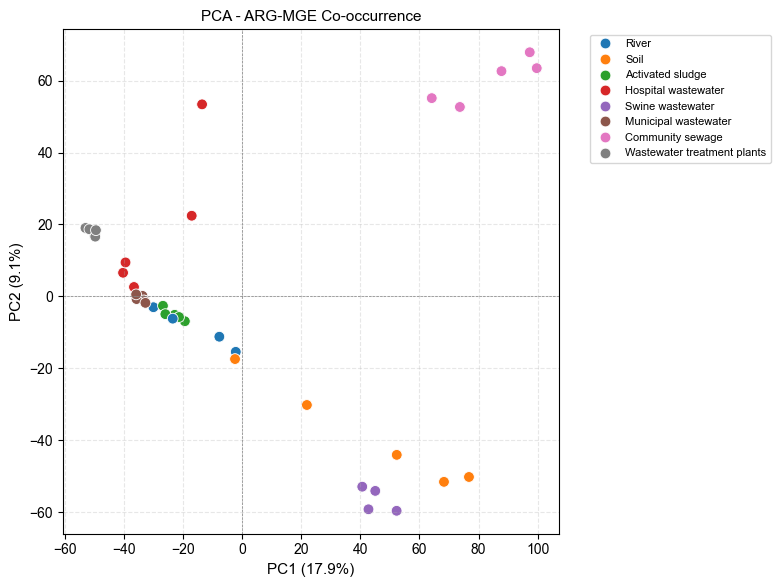

,PC1,PC2,magnitude,n_samples,label
"(tn3, tn3, msrE)",-0.021093,0.059381,0.063016,13,tn3|msrE
"(IS, IS3, msrE)",-0.012444,0.056888,0.058234,14,IS3|msrE
"(IS, IS110, tetA(58))",0.047107,-0.032768,0.057383,23,IS110|tetA(58)
"(tn3, tn3, mphE)",-0.022870,0.051455,0.056308,16,tn3|mphE
"(IS, IS110, bcrA)",0.050577,-0.022758,0.055461,21,IS110|bcrA
"(IS, IS256, tetA(58))",0.050781,-0.013515,0.052549,15,IS256|tetA(58)
"(IS, IS630, TxR)",0.038333,-0.034563,0.051614,22,IS630|TxR
"(IS, IS630, RanA)",0.046917,-0.019294,0.050729,19,IS630|RanA
"(integron, integron, tetA(58))",0.037996,-0.032735,0.050153,17,integron|tetA(58)
"(IS, IS5, vanS_in_vanM_cl)",0.035731,-0.034949,0.049981,14,IS5|vanS_in_vanM_cl


In [79]:
pca_df, pca_loadings, pca_model = plot_pca(
    rpm_df_arg_mge_comp, merged_metadata,
    color_by='Source', min_prevalence=0,
    zero_replacement='pseudocount', transform='clr', scale_features=None,
    file_name='./figures/pca_rpm_comp.png')
pca_loadings.head(15)[['PC1', 'PC2', 'magnitude', 'n_samples', 'label']]

### ARG-MGE Co-occurrence per Genus

In [80]:
# get_mge_labels tags each MGE with (mge_type, mge_specific). Composite transposons come through as ("composite_transposon", bounding IS family) and unit Tn / integrons as ("tn3", "tn3"), but a non-bounding IS comes through as (family, family) - ("IS3", "IS3").
KNOWN_MGE_TYPES = {"IS", "composite_transposon", "tn3", "tn7", "tn554", "integron"}
UNIT_TN_TYPES = {"tn3", "tn7", "tn554"}


def _is_standalone_is_type(mge_type):
    return str(mge_type).strip() not in KNOWN_MGE_TYPES and str(mge_type).strip() != ""


def get_mge_broad_category(mge_type):
    if mge_type in ("IS", "composite_transposon") or mge_type in UNIT_TN_TYPES:
        return "IS_Tn"
    if mge_type == "integron":
        return "Integron"
    if _is_standalone_is_type(mge_type):
        return "IS_Tn"
    return None


def get_mge_specific_category(mge_type, mge_specific):
    if mge_type == "composite_transposon":
        return f"CompTn({mge_specific})"
    if mge_type == "IS":
        return str(mge_specific)
    if mge_type in UNIT_TN_TYPES:
        return mge_type
    if mge_type == "integron":
        return "integron"
    if _is_standalone_is_type(mge_type):
        return str(mge_specific)
    return None


In [81]:
def build_genus_arg_mge_pairs(df, arg_level="Gene", mge_granularity="Broad",
                               genus_col="Genus", genes_col="arg_genes", class_col="arg_class"):
    temp_df = df.copy()
    if "mge_labels" not in temp_df.columns:
        temp_df["mge_labels"] = temp_df.apply(get_mge_labels, axis=1)
    temp_df = temp_df[temp_df["mge_labels"].map(len) > 0]
    temp_df = temp_df[temp_df[genus_col].notna()]

    # composite transposons are paired only with the ARGs they bound
    if arg_level == "Gene":
        exploded = explode_arg_mge_pairs(temp_df, genes_col, per_arg_genes, [genus_col])
    else:
        exploded = explode_arg_mge_pairs(temp_df, class_col, per_arg_classes, [genus_col])
    exploded = exploded[exploded["arg_values"].notna() & (exploded["arg_values"] != "")]
    exploded["arg_values"] = exploded["arg_values"].astype(str).str.strip()
    if arg_level == "Class":
        exploded["arg_values"] = normalize_drug_class_series(exploded["arg_values"])


    exploded["MGE"] = exploded["mge_labels"].apply(
        lambda t: get_mge_broad_category(t[0]) if mge_granularity == "Broad"
        else get_mge_specific_category(t[0], t[1])
    )
    exploded = exploded[exploded["MGE"].notna()]

    pair_df = exploded[[genus_col, "arg_values", "MGE"]].rename(columns={genus_col: "Genus", "arg_values": "ARG"})
    pair_df["Genus"] = pair_df["Genus"].astype(str)

    pair_df_dedup = pair_df.drop_duplicates(subset=["Genus", "ARG", "MGE"]).reset_index(drop=True)

    genus_counts = (
        pair_df_dedup.groupby(["ARG", "MGE"])["Genus"]
        .nunique()
        .reset_index(name="Genus_Count")
        .sort_values("Genus_Count", ascending=False)
        .reset_index(drop=True)
    )

    return pair_df_dedup, genus_counts


#### From Samples

In [82]:
samples_with_mge_labels = filtered_df_mge_eval_threshold_with_IS_position.copy()
samples_with_mge_labels["mge_labels"] = samples_with_mge_labels.apply(get_mge_labels, axis=1)

In [83]:
# Gene Level
gene_broad_genus_pairs, gene_broad_genus_counts = build_genus_arg_mge_pairs(
    samples_with_mge_labels, arg_level="Gene", mge_granularity="Broad"
)
gene_broad_genus_counts.to_csv("arg_mge_genus_counts_gene_broad.csv", index=False)
gene_broad_genus_counts


,ARG,MGE,Genus_Count
0,RanA,IS_Tn,594
1,bcrA,IS_Tn,581
2,tetA(58),IS_Tn,539
3,TxR,IS_Tn,429
4,arlR,IS_Tn,348
...,...,...,...
2122,AAC(6')-Ih,IS_Tn,1
2123,OXA-5,Integron,1
2124,AAC(6')-Iid,IS_Tn,1
2125,FosG,IS_Tn,1


In [84]:
gene_broad_binary_matrix = gene_broad_genus_pairs.copy()
gene_broad_binary_matrix["Present"] = 1
gene_broad_binary_matrix.to_csv("arg_mge_genus_binary_gene_broad.csv", index=False)
gene_broad_binary_matrix


,Genus,ARG,MGE,Present
0,Klebsiella,macA,IS_Tn,1
1,Klebsiella,macB,IS_Tn,1
2,Enterobacter,oleC,IS_Tn,1
3,Herbaspirillum,basS,IS_Tn,1
4,Herbaspirillum,vanR_in_vanB_cl,IS_Tn,1
...,...,...,...,...
30487,Microbacterium,otr(B),Integron,1
30488,Microtetraspora,Ctra_murA_FOF,IS_Tn,1
30489,Mesorhizobium,farA,Integron,1
30490,Mesorhizobium,farB,Integron,1


In [85]:
gene_specific_genus_pairs, gene_specific_genus_counts = build_genus_arg_mge_pairs(
    samples_with_mge_labels, arg_level="Gene", mge_granularity="Specific"
)
gene_specific_genus_counts.to_csv("arg_mge_genus_counts_gene_specific.csv", index=False)
gene_specific_genus_counts


,ARG,MGE,Genus_Count
0,bcrA,IS3,226
1,RanA,IS3,217
2,tetA(58),IS3,211
3,bcrA,IS110,167
4,RanA,IS5,160
...,...,...,...
14275,AAC(3)-IIIb,IS256,1
14276,AAC(3)-IIIb,IS30,1
14277,AAC(3)-IIIb,IS6,1
14278,AAC(3)-IIIb,IS630,1


In [86]:
gene_specific_binary_matrix = gene_specific_genus_pairs.copy()
gene_specific_binary_matrix["Present"] = 1
gene_specific_binary_matrix.to_csv("arg_mge_genus_binary_gene_specific.csv", index=False)
gene_specific_binary_matrix


,Genus,ARG,MGE,Present
0,Klebsiella,macA,IS1,1
1,Klebsiella,macB,IS1,1
2,Enterobacter,oleC,IS200/IS605,1
3,Herbaspirillum,basS,IS5,1
4,Herbaspirillum,vanR_in_vanB_cl,tn3,1
...,...,...,...,...
66005,Variovorax,RanA,ISL3,1
66006,Mesorhizobium,farA,integron,1
66007,Mesorhizobium,farB,integron,1
66008,Mesorhizobium,macB,integron,1


In [87]:
def build_sample_arg_mge_genus_counts(df, sample_col="Sample", genus_col="Genus",
                                      genes_col="arg_genes"):
   
    temp_df = df.copy()
    if "mge_labels" not in temp_df.columns:
        temp_df["mge_labels"] = temp_df.apply(get_mge_labels, axis=1)
    temp_df = temp_df[temp_df["mge_labels"].map(len) > 0]
    temp_df = temp_df[temp_df[genus_col].notna()]

    # composite transposons are paired only with the ARGs they bound
    exploded = explode_arg_mge_pairs(temp_df, genes_col, per_arg_genes, [sample_col, genus_col])
    exploded = exploded[exploded["arg_values"].notna() & (exploded["arg_values"] != "")]
    exploded["arg_values"] = exploded["arg_values"].astype(str).str.strip()

    exploded["MGE"] = exploded["mge_labels"].apply(
        lambda t: get_mge_specific_category(t[0], t[1])
    )
    exploded["MGE_Broad"] = exploded["mge_labels"].apply(
        lambda t: get_mge_broad_category(t[0])
    )
    exploded = exploded[exploded["MGE"].notna()]

    long_df = (
        exploded[[sample_col, genus_col, "arg_values", "MGE_Broad", "MGE"]]
        .rename(columns={sample_col: "sample_id", genus_col: "Genus",
                         "arg_values": "ARG"})
    )
    long_df["Genus"] = long_df["Genus"].astype(str)

    # one record per (sample, genus, ARG, MGE): many reads of the same genus carrying the same pair in the same sample collapse to one
    long_dedup = long_df.drop_duplicates(subset=["sample_id", "Genus", "ARG", "MGE"])

    counts = (
        long_dedup.groupby(["sample_id", "MGE_Broad", "MGE", "ARG"])["Genus"]
        .nunique()
        .reset_index(name="Genus_Count")
    )

    matrix = counts.pivot_table(
        index="sample_id", columns=["MGE_Broad", "MGE", "ARG"],
        values="Genus_Count", fill_value=0,
    ).astype(int)
    matrix.columns = [tuple(c) for c in matrix.columns]
    matrix.index.name = "sample_id"

    return matrix, counts, long_dedup

In [88]:
(sample_gene_specific_genus_matrix, sample_gene_specific_genus_counts, sample_gene_specific_genus_long) = build_sample_arg_mge_genus_counts(samples_with_mge_labels)

print(f"Samples          : {sample_gene_specific_genus_matrix.shape[0]}")
print(f"ARG-MGE features : {sample_gene_specific_genus_matrix.shape[1]}")
print(f"Genus records    : {len(sample_gene_specific_genus_long):,}  (sample x genus x ARG x MGE)")

sample_gene_specific_genus_counts.to_csv("arg_mge_genus_counts_gene_specific_by_sample.csv", index=False)
sample_gene_specific_genus_matrix.to_csv("arg_mge_genus_counts_gene_specific_matrix.csv")

Samples          : 40
ARG-MGE features : 14280
Genus records    : 90,826  (sample x genus x ARG x MGE)


#### From ProMGE

In [89]:
def build_genus_arg_mge_pairs_promge(df, genus_col="genus", class_col="Drug_Class", mge_col="mge_category"):
    work = df[[genus_col, class_col, mge_col]].copy()
    work = work[work[mge_col].isin(["IS_Tn", "Integron"])]
    work = work.dropna(subset=[genus_col, class_col])
    work = work[~work[class_col].apply(is_excluded_drug_class)]

    work["Genus"] = work[genus_col].astype(str)
    work["ARG"] = normalize_drug_class_series(work[class_col].astype(str))
    work["MGE"] = work[mge_col]

    pair_df_dedup = work[["Genus", "ARG", "MGE"]].drop_duplicates().reset_index(drop=True)

    genus_counts = (
        pair_df_dedup.groupby(["ARG", "MGE"])["Genus"]
        .nunique()
        .reset_index(name="Genus_Count")
        .sort_values("Genus_Count", ascending=False)
        .reset_index(drop=True)
    )

    return pair_df_dedup, genus_counts

In [90]:
promge_genus_pairs, promge_genus_counts = build_genus_arg_mge_pairs_promge(pro_mge_indiv)
promge_genus_counts.to_csv("arg_mge_genus_counts_promge.csv", index=False)
promge_genus_counts


,ARG,MGE,Genus_Count
0,peptide,IS_Tn,565
1,aminoglycoside,IS_Tn,548
2,glycopeptide,IS_Tn,117
3,diaminopyrimidine,IS_Tn,111
4,aminoglycoside,Integron,103
5,phenicol,IS_Tn,100
6,macrolide,IS_Tn,95
7,streptogramin,IS_Tn,94
8,lincosamide,IS_Tn,92
9,penicillin,IS_Tn,77


In [91]:
promge_binary_matrix = promge_genus_pairs.copy()
promge_binary_matrix["Present"] = 1
promge_binary_matrix.to_csv("arg_mge_genus_binary_promge.csv", index=False)
promge_binary_matrix


,Genus,ARG,MGE,Present
0,Salmonella,phosphonic acid,IS_Tn,1
1,Staphylococcus,lincosamide,IS_Tn,1
2,Staphylococcus,macrolide,IS_Tn,1
3,Staphylococcus,streptogramin,IS_Tn,1
4,Staphylococcus,aminoglycoside,IS_Tn,1
...,...,...,...,...
2674,NA Porphyromonadaceae gen. incertae sedis,aminoglycoside,Integron,1
2675,Parabacteroides,glycylcycline,Integron,1
2676,Parabacteroides,lincosamide,Integron,1
2677,Parabacteroides,macrolide,Integron,1


#### Gene Family Level (Samples vs ProMGE)

In [92]:
def build_genus_arg_mge_pairs_gene_family(df, gene_family_lookup,
                                          mge_granularity="Broad",
                                          genus_col="Genus", genes_col="arg_genes"):
    # Genus-deduplicated (Genus, AMR gene family, MGE) pairs for the samples.

    temp_df = df.copy()
    if "mge_labels" not in temp_df.columns:
        temp_df["mge_labels"] = temp_df.apply(get_mge_labels, axis=1)
    temp_df = temp_df[temp_df["mge_labels"].map(len) > 0]
    temp_df = temp_df[temp_df[genus_col].notna()]

    # composite transposons are paired only with the ARGs they bound
    exploded = explode_arg_mge_pairs(temp_df, genes_col, per_arg_genes, [genus_col])
    exploded = exploded[exploded["arg_values"].notna() & (exploded["arg_values"] != "")]

    # gene -> AMR gene family; a gene may map to several, and None means CARD has no row
    exploded["arg_values"] = exploded["arg_values"].astype(str).apply(
        lambda g: resolve_gene_families(g, gene_family_lookup)
    )
    exploded = exploded[exploded["arg_values"].notna()]
    exploded = exploded.explode("arg_values")
    exploded["arg_values"] = exploded["arg_values"].astype(str).str.strip().str.lower()
    exploded = exploded[exploded["arg_values"] != ""]

    exploded["MGE"] = exploded["mge_labels"].apply(
        lambda t: get_mge_broad_category(t[0]) if mge_granularity == "Broad"
        else get_mge_specific_category(t[0], t[1])
    )
    exploded = exploded[exploded["MGE"].notna()]

    pair_df = exploded[[genus_col, "arg_values", "MGE"]].rename(
        columns={genus_col: "Genus", "arg_values": "ARG"}
    )
    pair_df["Genus"] = pair_df["Genus"].astype(str)

    pair_df_dedup = (pair_df.drop_duplicates(subset=["Genus", "ARG", "MGE"])
                            .reset_index(drop=True))
    genus_counts = (
        pair_df_dedup.groupby(["ARG", "MGE"])["Genus"]
        .nunique()
        .reset_index(name="Genus_Count")
        .sort_values("Genus_Count", ascending=False)
        .reset_index(drop=True)
    )
    return pair_df_dedup, genus_counts


def build_genus_arg_mge_pairs_promge_gene_family(df, genus_col="genus",
                                                 family_col="Gene_Family",
                                                 mge_col="mge_category"):
    """ProMGE counterpart: (Genus, gene family, IS_Tn/Integron), lowercased.

    No drug-class exclusions apply here - these are gene families, not classes - and
    the CARD placeholder family was already dropped building pro_mge_indiv_gf_1to1.
    """
    work = df[[genus_col, family_col, mge_col]].copy()
    work = work[work[mge_col].isin(["IS_Tn", "Integron"])]
    work = work.dropna(subset=[genus_col, family_col])

    work["Genus"] = work[genus_col].astype(str)
    work["ARG"] = work[family_col].astype(str).str.strip().str.lower()
    work = work[work["ARG"] != ""]
    work["MGE"] = work[mge_col]

    pair_df_dedup = (work[["Genus", "ARG", "MGE"]]
                     .drop_duplicates()
                     .reset_index(drop=True))
    genus_counts = (
        pair_df_dedup.groupby(["ARG", "MGE"])["Genus"]
        .nunique()
        .reset_index(name="Genus_Count")
        .sort_values("Genus_Count", ascending=False)
        .reset_index(drop=True)
    )
    return pair_df_dedup, genus_counts

In [93]:
#  Samples: genus x AMR gene family x broad MGE 
gene_family_broad_genus_pairs, gene_family_broad_genus_counts = (
    build_genus_arg_mge_pairs_gene_family(
        samples_with_mge_labels, gene_family_lookup, mge_granularity="Broad"
    )
)
gene_family_broad_binary_matrix = gene_family_broad_genus_pairs.copy()
gene_family_broad_binary_matrix["Present"] = 1

#  ProMGE: genus x gene family x broad MGE 
promge_gene_family_genus_pairs, promge_gene_family_genus_counts = (
    build_genus_arg_mge_pairs_promge_gene_family(pro_mge_indiv_gf)
)
promge_gene_family_binary_matrix = promge_gene_family_genus_pairs.copy()
promge_gene_family_binary_matrix["Present"] = 1

print(f"samples pairs: {len(gene_family_broad_binary_matrix)}  "
      f"({gene_family_broad_binary_matrix['ARG'].nunique()} families, "
      f"{gene_family_broad_binary_matrix['Genus'].nunique()} genera)")
print(f"promge  pairs: {len(promge_gene_family_binary_matrix)}  "
      f"({promge_gene_family_binary_matrix['ARG'].nunique()} families, "
      f"{promge_gene_family_binary_matrix['Genus'].nunique()} genera)")

for _m, _name in [(gene_family_broad_binary_matrix, "samples"),
                  (promge_gene_family_binary_matrix, "promge")]:
    assert (_m["ARG"] == _m["ARG"].str.lower()).all(), f"{_name} ARG not lowercased"

gene_family_broad_binary_matrix.to_csv(
    "arg_mge_genus_binary_gene_family_broad.csv", index=False)
promge_gene_family_binary_matrix.to_csv(
    "arg_mge_genus_binary_promge_gene_family.csv", index=False)
gene_family_broad_genus_counts.head(15)

samples pairs: 16848  (276 families, 1837 genera)
promge  pairs: 2478  (143 families, 634 genera)


,ARG,MGE,Genus_Count
0,atp-binding cassette (abc) antibiotic efflux pump,IS_Tn,1087
1,major facilitator superfamily (mfs) antibiotic...,IS_Tn,956
2,resistance-nodulation-cell division (rnd) anti...,IS_Tn,867
3,glycopeptide resistance gene cluster,IS_Tn,828
4,vanr,IS_Tn,601
5,pmr phosphoethanolamine transferase,IS_Tn,431
6,vans,IS_Tn,362
7,sulfonamide resistant sul,IS_Tn,342
8,miscellaneous abc-f subfamily atp-binding cass...,IS_Tn,328
9,multidrug and toxic compound extrusion (mate) ...,IS_Tn,300


In [94]:
combined_gene_family_broad_promge_all = pd.merge(
    gene_family_broad_binary_matrix,
    promge_gene_family_binary_matrix,
    on=["Genus", "ARG", "MGE"],
    how="outer",
    suffixes=("_samples", "_promge"),
)
for _col in ["Present_samples", "Present_promge"]:
    if _col in combined_gene_family_broad_promge_all.columns:
        combined_gene_family_broad_promge_all[_col] = (combined_gene_family_broad_promge_all[_col].fillna(0).astype(int))

combined_gene_family_broad_promge_all.to_csv(
    "./pro_mge_vs_samples/arg_mge_genus_binary_combined_gene_family_broad_promge_all.csv",
    index=False,
)
combined_gene_family_broad_promge_all

,Genus,ARG,MGE,Present_samples,Present_promge
0,1109,atp-binding cassette (abc) antibiotic efflux pump,IS_Tn,1,0
1,2-02-FULL-63-19,outer membrane porin (opr),IS_Tn,1,0
2,2-02-FULL-63-19,resistance-nodulation-cell division (rnd) anti...,IS_Tn,1,0
3,28-YEA-48,rifampin monooxygenase,IS_Tn,1,0
4,39-52-133,resistance-nodulation-cell division (rnd) anti...,IS_Tn,1,0
...,...,...,...,...,...
18493,Zoogloea,sulfonamide resistant sul,IS_Tn,1,0
18494,Zoogloea,sulfonamide resistant sul,Integron,1,0
18495,Zoogloea,vanr,Integron,1,0
18496,Zymomonas,chloramphenicol acetyltransferase (cat),IS_Tn,0,1


In [95]:
associations_both_gf_all = combined_gene_family_broad_promge_all[
    (combined_gene_family_broad_promge_all["Present_samples"] == 1) &
    (combined_gene_family_broad_promge_all["Present_promge"] == 1)
]
associations_samples_only_gf_all = combined_gene_family_broad_promge_all[
    (combined_gene_family_broad_promge_all["Present_samples"] == 1) &
    (combined_gene_family_broad_promge_all["Present_promge"] == 0)
]
associations_promge_only_gf_all = combined_gene_family_broad_promge_all[
    (combined_gene_family_broad_promge_all["Present_samples"] == 0) &
    (combined_gene_family_broad_promge_all["Present_promge"] == 1)
]

print("Gene-family ARG-MGE-genus associations (in Samples and ProMGE):", len(associations_both_gf_all))
print("New gene-family ARG-MGE associations (in Samples, absent from ProMGE):", len(associations_samples_only_gf_all))
print("Gene-family ARG-MGE associations (in ProMGE, absent from Samples):", len(associations_promge_only_gf_all))

_shared = set(gene_family_broad_binary_matrix["ARG"]) & set(promge_gene_family_binary_matrix["ARG"])
print(f"\nShared gene families between the two sources: {len(_shared)}")
print(f"  samples only: {len(set(gene_family_broad_binary_matrix['ARG']) - _shared)}")
print(f"  promge only : {len(set(promge_gene_family_binary_matrix['ARG']) - _shared)}")

Gene-family ARG-MGE-genus associations (in Samples and ProMGE): 828
New gene-family ARG-MGE associations (in Samples, absent from ProMGE): 16020
Gene-family ARG-MGE associations (in ProMGE, absent from Samples): 1650

Shared gene families between the two sources: 105
  samples only: 171
  promge only : 38


In [96]:
# Same three counts split by MGE category (IS_Tn vs Integron).
overlap_by_mge_gf_all = (
    combined_gene_family_broad_promge_all
    .assign(
        In_Both=lambda d: ((d["Present_samples"] == 1) & (d["Present_promge"] == 1)).astype(int),
        Samples_Only=lambda d: ((d["Present_samples"] == 1) & (d["Present_promge"] == 0)).astype(int),
        ProMGE_Only=lambda d: ((d["Present_samples"] == 0) & (d["Present_promge"] == 1)).astype(int),
    )
    .groupby("MGE")[["In_Both", "Samples_Only", "ProMGE_Only"]]
    .sum()
    .sort_index()
)
overlap_by_mge_gf_all["Total"] = overlap_by_mge_gf_all.sum(axis=1)
overlap_by_mge_gf_all["In_Samples"] = (overlap_by_mge_gf_all["In_Both"] + overlap_by_mge_gf_all["Samples_Only"])
overlap_by_mge_gf_all["In_ProMGE"] = (overlap_by_mge_gf_all["In_Both"] + overlap_by_mge_gf_all["ProMGE_Only"])
overlap_by_mge_gf_all["Pct_Samples_In_ProMGE"] = (overlap_by_mge_gf_all["In_Both"] / overlap_by_mge_gf_all["In_Samples"] * 100)
overlap_by_mge_gf_all["Pct_ProMGE_In_Samples"] = (overlap_by_mge_gf_all["In_Both"] / overlap_by_mge_gf_all["In_ProMGE"] * 100)

overlap_by_mge_gf_all.to_csv(
    "./pro_mge_vs_samples/arg_mge_genus_overlap_by_mge_category_gene_family_all.csv"
)
overlap_by_mge_gf_all

,In_Both,Samples_Only,ProMGE_Only,Total,In_Samples,In_ProMGE,Pct_Samples_In_ProMGE,Pct_ProMGE_In_Samples
MGE,,,,,,,,
IS_Tn,678,13860,1394,15932,14538,2072,4.663640,32.722008
Integron,150,2160,256,2566,2310,406,6.493506,36.945813


#### Heatmap

$$P_{AB} = \frac{\text{distinct genera with ARG } A \text{ and MGE } B}{\text{distinct genera with ARG } A \text{ and at least one MGE}} \times 100$$
Both counts are genus-deduplicated, exactly as in the pair counts above: a genus contributes once no matter how many samples, reads or contigs of it carry the ARG. The denominator counts every genus carrying ARG $A$ together with at least one MGE, at the same granularity as the numerator, so genera where the ARG sits on no MGE are excluded from both sides.

In [97]:
def build_genus_arg_mge_percentages(df, arg_level="Gene", mge_granularity="Broad",
                                    genus_col="Genus", genes_col="arg_genes", class_col="arg_class",
                                    min_genera=1):
    # Genera carrying ARG A with MGE B, as a percentage of the genera carrying ARG A on any MGE.
    work = df.copy()
    work = work[work[genus_col].notna()].copy()
    work["Genus"] = work[genus_col].astype(str)

    if "mge_labels" not in work.columns:
        work["mge_labels"] = work.apply(get_mge_labels, axis=1)

    # composite transposons are paired only with the ARGs they bound
    if arg_level == "Gene":
        mge_exploded = explode_arg_mge_pairs(work, genes_col, per_arg_genes, ["Genus"])
    else:
        mge_exploded = explode_arg_mge_pairs(work, class_col, per_arg_classes, ["Genus"])
    mge_exploded = mge_exploded[mge_exploded["arg_values"].notna() & (mge_exploded["arg_values"] != "")]
    mge_exploded["arg_values"] = mge_exploded["arg_values"].astype(str).str.strip()
    if arg_level == "Class":
        mge_exploded["arg_values"] = normalize_drug_class_series(mge_exploded["arg_values"])

    mge_exploded["MGE"] = mge_exploded["mge_labels"].apply(
        lambda t: get_mge_broad_category(t[0]) if mge_granularity == "Broad"
        else get_mge_specific_category(t[0], t[1])
    )
    mge_exploded = mge_exploded[mge_exploded["MGE"].notna()]

    # denominator: distinct genera carrying the ARG together with at least one MGE
    genera_with_arg = mge_exploded.groupby("arg_values")["Genus"].nunique()

    # numerator: distinct genera carrying the ARG and the MGE together
    result = (
        mge_exploded.groupby(["arg_values", "MGE"])["Genus"]
        .nunique()
        .reset_index(name="Genera_With_ARG_MGE")
        .rename(columns={"arg_values": "ARG"})
    )
    result["Genera_With_ARG"] = result["ARG"].map(genera_with_arg)
    result["Pct_of_ARG_Genera"] = result["Genera_With_ARG_MGE"] / result["Genera_With_ARG"] * 100

    result = result[result["Genera_With_ARG"] >= min_genera]
    result = result.sort_values(["Genera_With_ARG", "ARG", "Pct_of_ARG_Genera"],
                                ascending=[False, True, False]).reset_index(drop=True)

    return result[["ARG", "MGE", "Genera_With_ARG_MGE", "Genera_With_ARG", "Pct_of_ARG_Genera"]]


def pivot_arg_mge_percentages(long_df, value_col="Pct_of_ARG_Genera"):
    # wide ARG x MGE matrix of the percentages, for heatmaps
    return long_df.pivot(index="ARG", columns="MGE", values=value_col).fillna(0.0)

In [98]:
gene_specific_genus_pct = build_genus_arg_mge_percentages(
    samples_with_mge_labels, arg_level="Gene", mge_granularity="Specific"
)
gene_specific_genus_pct.to_csv("arg_mge_genus_pct_gene_specific.csv", index=False)
gene_specific_genus_pct

,ARG,MGE,Genera_With_ARG_MGE,Genera_With_ARG,Pct_of_ARG_Genera
0,RanA,IS3,217,600,36.166667
1,RanA,IS5,160,600,26.666667
2,RanA,IS110,158,600,26.333333
3,RanA,IS256,129,600,21.500000
4,RanA,IS30,100,600,16.666667
...,...,...,...,...,...
14275,tet(E),IS66,1,1,100.000000
14276,tet(E),ISL3,1,1,100.000000
14277,tet(E),tn3,1,1,100.000000
14278,vanT_in_vanE_cl,IS4,1,1,100.000000


In [99]:
PCT_VALUE_COLS = ["Pct_of_ARG_Genera", "Pooled_Pct"]
PCT_SCALE = 0.01  

def resolve_value_col(df, value_col=None):
    if value_col is not None:
        return value_col
    for col in PCT_VALUE_COLS:
        if col in df.columns:
            return col
   
def format_mge_label(val):
    mapping = {
        "IS_Tn": "IS/Tn", "Integron": "Int", "integron": "Int",
        "tn3": "Tn3", "tn7": "Tn7", "tn554": "Tn554",
    }
    return mapping.get(val, val)

In [100]:
def classify_arg_mge_association(pct_df, predominant_pct=70.0, broad_min_mges=20,
                                  broad_max_pct=30.0, min_genera=1):
   
    #   predominant - one MGE carries >= predominant_pct of the gene's genera
    #   broad       - found with >= broad_min_mges MGEs, none above broad_max_pct
    # Both use every genus and every MGE the gene has, independent of the heatmap's row filter.
    # min_genera > 1 would leave genes seen in fewer genera unmarked (a single genus reads 100% on its MGE).
    per_gene = pct_df.groupby("ARG").agg(
        N_MGEs=("MGE", "nunique"),
        Max_Pct=("Pct_of_ARG_Genera", "max"),
        Genera_With_ARG=("Genera_With_ARG", "first"),
    )
    max_pct = per_gene["Max_Pct"].round(6)
    enough = per_gene["Genera_With_ARG"] >= min_genera
    per_gene["Association"] = np.select(
        [enough & (max_pct >= predominant_pct),
         enough & (per_gene["N_MGEs"] >= broad_min_mges) & (max_pct <= broad_max_pct)],
        ["predominant", "broad"],
        default="",
    )
    return per_gene


def plot_arg_mge_pct_matrix(pct_df, min_mge_pct=5.0, mge_min_genera_pct=0.0, pairs_df=None, gene_min_genera=1, markers=True, marker_min_genera=10):
    CMAP = "rocket_r"
    CELL_SIZE = 0.17        
    WIDTH = 15.0 
    LABEL_FONTSIZE = 10
    TEXT_COLOR = "#2C2C2A"
    MARKER_COLORS = {"predominant": "#2166AC", "broad": "#E6AB02"}

    pivot = pct_df.pivot_table(index="ARG", columns="MGE", values="Pct_of_ARG_Genera",
                               aggfunc="sum", fill_value=0.0) / 100.0

    # an MGE is kept if it passes two separate tests:
    #   - some gene (any gene) reaches min_mge_pct on it
    #   - it is carried by >= mge_min_genera_pct % of all genera carrying an ARG on an MGE, with any ARG;
    #     counted from pairs_df (Genus, ARG, MGE rows, e.g. gene_specific_genus_pairs), since pct_df has no
    #     per-MGE genus count. With 1,835 genera in total, 1% keeps an MGE found in >= 18.35, i.e. 19, genera.
    # All genes are still plotted. Then MGEs are ordered by prevalence.
    keep = [m for m in pivot.columns if pivot[m].max() >= min_mge_pct / 100.0]
    if mge_min_genera_pct > 0:
        if pairs_df is None:
            raise ValueError("mge_min_genera_pct > 0 needs pairs_df (Genus, ARG, MGE), e.g. gene_specific_genus_pairs")
        total_genera = pairs_df["Genus"].nunique()
        mge_genera_pct = pairs_df.groupby("MGE")["Genus"].nunique() / total_genera * 100
        keep = [m for m in keep if round(mge_genera_pct.get(m, 0.0), 6) >= mge_min_genera_pct]
    pivot = pivot[keep]
    pivot = pivot[pivot.sum(axis=0).sort_values(ascending=False).index]

    # then drop ARG genes found on an MGE in fewer than gene_min_genera genera: over 1-4 genera a percentage can
    # only be 0/25/33/50/67/75/100%. Applied after the MGE rows are chosen, so it does not change which rows stay.
    gene_genera = pct_df.groupby("ARG")["Genera_With_ARG"].first().reindex(pivot.index)
    pivot = pivot[gene_genera >= gene_min_genera]

    dominant = pivot.idxmax(axis=1)
    strength = pivot.max(axis=1)
    rank = {m: r for r, m in enumerate(pivot.columns)}
    pivot = pivot.loc[sorted(
        pivot.index,
        key=lambda a: (rank[dominant[a]], -float(strength[a]), str(a).casefold()))]

    matrix = pivot.T # MGEs x ARG genes
    n_mges = matrix.shape[0]
    fig, ax = plt.subplots(figsize=(WIDTH, max(n_mges * CELL_SIZE + 2.0, 5.0)), dpi=300)
    cmap = sns.color_palette(CMAP, as_cmap=True)

    mesh = ax.pcolormesh(matrix.values[::-1], cmap=cmap, vmin=0, vmax=1, rasterized=True)

    ax.set_yticks(np.arange(n_mges) + 0.5)
    ax.set_yticklabels([format_mge_label(m) for m in matrix.index][::-1],
                       fontsize=LABEL_FONTSIZE, color=TEXT_COLOR)
    ax.set_xticks([])
    ax.set_xlabel("ARGs", fontsize=LABEL_FONTSIZE + 2, color=TEXT_COLOR)

    if markers:
        assoc_kwargs = {} if marker_min_genera is None else {"min_genera": marker_min_genera}
        assoc = (classify_arg_mge_association(pct_df, **assoc_kwargs)["Association"]
                 .reindex(matrix.columns).fillna(""))
        x = np.arange(matrix.shape[1]) + 0.5
        handles = []
        for label, color, text in [
            ("predominant", MARKER_COLORS["predominant"], "Narrow MGE association"),
            ("broad", MARKER_COLORS["broad"], "Broad MGE association"),
        ]:
            hit = (assoc == label).to_numpy()
            ax.bar(x[hit], 0.8, bottom=n_mges + 0.4, width=1.0, color=color, linewidth=0)
            handles.append(Patch(facecolor=color, edgecolor="none", label=f"{text}"))
        ax.set_ylim(0, n_mges + 1.4)
        ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False,
                  fontsize=LABEL_FONTSIZE, handlelength=1.2, handletextpad=0.4, columnspacing=2.0)

    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False) 

    cbar = fig.colorbar(mesh, ax=ax, orientation="vertical", fraction=0.025, pad=0.02)
    cbar.set_label("Proportion of genera carrying the ARG-MGE pair", fontsize=LABEL_FONTSIZE,
                   color=TEXT_COLOR, fontweight="bold", labelpad=10)
    cbar.ax.tick_params(labelsize=LABEL_FONTSIZE - 1, color=TEXT_COLOR)
    cbar.outline.set_visible(False)
    ticks = [0.0, 0.25, 0.5, 0.75, 1.0]
    cbar.set_ticks(ticks)
    cbar.set_ticklabels([f"{t:.2f}" for t in ticks])

    fig.tight_layout()
    return fig, matrix

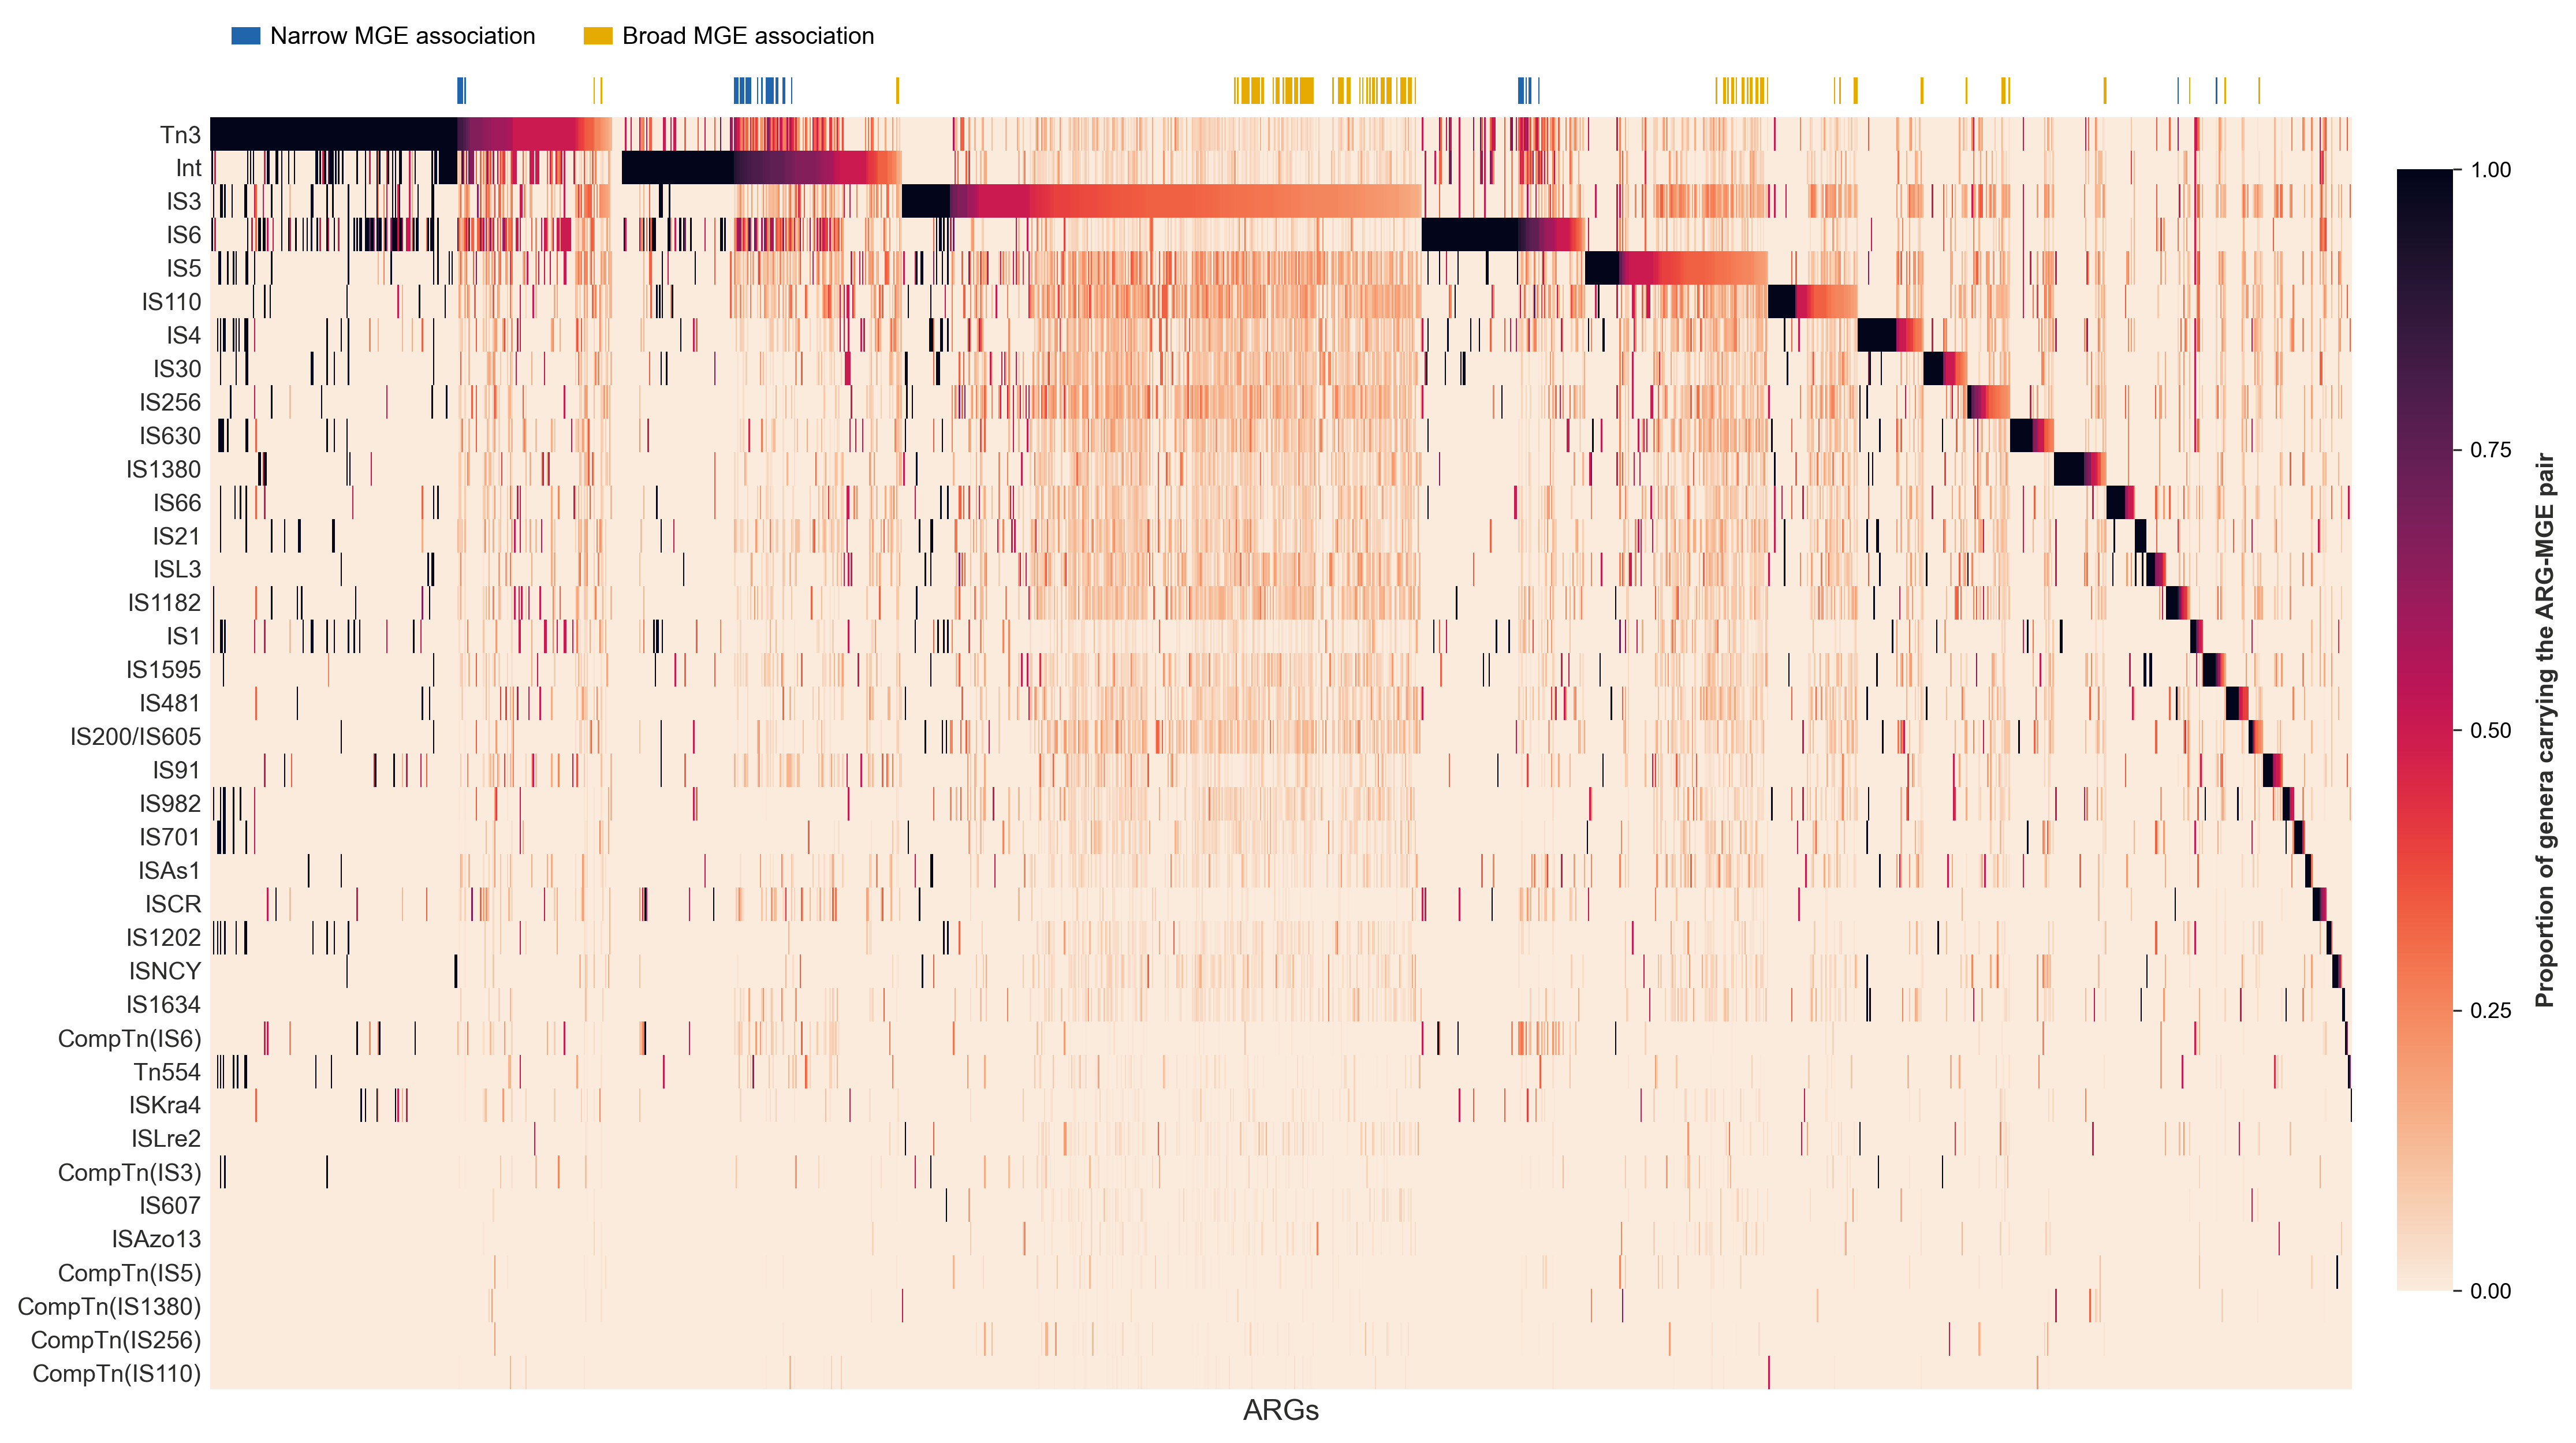

38 MGE rows x 1508 ARG columns


In [135]:
fig, all_genes_specific_matrix_dominant = plot_arg_mge_pct_matrix(
    gene_specific_genus_pct,
    min_mge_pct=10,
    mge_min_genera_pct=2,
    pairs_df=gene_specific_genus_pairs,
)
fig.savefig("heatmap_arg_mge_genus_pct_all_genes_specific_dominant.png",
            dpi=300, bbox_inches="tight")
plt.show()

n_mges, n_args = all_genes_specific_matrix_dominant.shape
print(f"{n_mges} MGE rows x {n_args} ARG columns")

### ITOL Phylogeny Tree

In [102]:
def parse_bracken(filepath):
    df = pd.read_csv(filepath, sep="\t")
    rank_map = {
    "D": "Domain", "P": "Phylum", "C": "Class",
    "O": "Order",  "F": "Family", "G": "Genus", "S": "Species"
    }
    
    sample_name = os.path.basename(filepath).split("_")[0]
    
    df = df[["name", "taxonomy_lvl", "fraction_total_reads"]].rename(columns={
        "taxonomy_lvl": "taxonomy_rank",
        "fraction_total_reads": "abundance"
    })
    df["taxonomy_rank"] = df["taxonomy_rank"].map(rank_map).fillna(df["taxonomy_rank"])
    df["sample"] = sample_name
    
    return df

filepaths = glob.glob("bracken/*genus.bracken")

combined = pd.concat([parse_bracken(fp) for fp in filepaths], ignore_index=True)

combined = combined[["sample", "name", "taxonomy_rank", "abundance"]]
combined = combined.sort_values(["sample", "abundance"], ascending=[True, False]).reset_index(drop=True)

print(combined.head(10))
print(f"\nSamples found: {combined['sample'].nunique()}")
print(combined["sample"].unique())

      sample                 name taxonomy_rank  abundance
0  DRR539880     Stenotrophomonas         Genus    0.56464
1  DRR539880       Herbaspirillum         Genus    0.15077
2  DRR539880           Klebsiella         Genus    0.09466
3  DRR539880        Achromobacter         Genus    0.06679
4  DRR539880            Aeromonas         Genus    0.02284
5  DRR539880     Chryseobacterium         Genus    0.02112
6  DRR539880        Acinetobacter         Genus    0.01301
7  DRR539880  Pseudoxanthomonas_A         Genus    0.01289
8  DRR539880        Pseudomonas_E         Genus    0.00786
9  DRR539880            Comamonas         Genus    0.00761

Samples found: 40
<StringArray>
[  'DRR539880',   'DRR539882', 'ERR11596058', 'ERR12037364', 'ERR12040028',
 'SRR12664558', 'SRR12664571', 'SRR12664584', 'SRR12664600', 'SRR12664615',
 'SRR12917036', 'SRR12917043', 'SRR15359754', 'SRR15359755', 'SRR15359756',
 'SRR25444967', 'SRR25444968', 'SRR25444969', 'SRR25528443', 'SRR25528444',
 'SRR25528445'

In [103]:

def compositional_mean_by_rank(df, rank="Genus"):
    filtered = df[df["taxonomy_rank"] == rank]

    pivot = (
        filtered
        .pivot_table(index="name", columns="sample", values="abundance", aggfunc="sum")
        .fillna(0)
    )

    # samples as rows, taxa as cols
    X = pivot.T.values.astype(float)

    X = multi_replace(X)
    clr_transformed = clr(X)

    comp_mean = clr_inv(clr_transformed.mean(axis=0))

    return pd.DataFrame(comp_mean, index=pivot.index, columns=["compositional_mean"]).sort_values(
        "compositional_mean", ascending=False
    )

In [104]:
genus_means = compositional_mean_by_rank(combined, rank="Genus")
print(genus_means.head(100))

                  compositional_mean
name                                
Pseudomonas_E               0.444385
Streptomyces                0.086973
Achromobacter               0.057125
Flavobacterium              0.056913
Mycobacterium               0.055861
...                              ...
Pigmentiphaga               0.000163
Neobacillus                 0.000162
Rhodococcus_F               0.000161
Methylibium                 0.000159
Phenylobacterium            0.000151

[100 rows x 1 columns]


In [105]:
# genus names are the index of genus_means; no reset_index, so this cell can be re-run
genus_means_top100 = genus_means.index[:100].tolist()
genus_means_top100

['Pseudomonas_E',
 'Streptomyces',
 'Achromobacter',
 'Flavobacterium',
 'Mycobacterium',
 'Acinetobacter',
 'Acidovorax',
 'Paraburkholderia',
 'Microbacterium',
 'Streptococcus',
 'Paracoccus',
 'Stenotrophomonas',
 'Bradyrhizobium',
 'Nocardia',
 'Cupriavidus',
 'Vibrio',
 'Mesorhizobium',
 'Prevotella',
 'Rhizobium',
 'Aeromonas',
 'Thauera',
 'Comamonas',
 'Burkholderia',
 'Variovorax',
 'Bacteroides',
 'Janthinobacterium',
 'Chryseobacterium',
 'Methylobacterium',
 'Enterobacter',
 'Caballeronia',
 'Sphingomonas',
 'Staphylococcus',
 'Sphingobium',
 'Sphingopyxis',
 'Micromonospora',
 'Amycolatopsis',
 'Klebsiella',
 'Bosea',
 'Hydrogenophaga',
 'Paenibacillus',
 'Azonexus',
 'Corynebacterium',
 'Limnohabitans_A',
 'Providencia',
 'Simplicispira',
 'Novosphingobium',
 'Brucella',
 'Bifidobacterium',
 'Roseovarius',
 'Escherichia',
 'Pseudoxanthomonas_A',
 'Brevundimonas',
 'Herbaspirillum',
 'Pseudoalteromonas',
 'Erythrobacter',
 'Bacillus_A',
 'Xanthomonas',
 'Clostridium',
 'P

In [106]:
filtered_top100_genera_df = filtered_df_mge_eval_threshold_with_IS_position[filtered_df_mge_eval_threshold_with_IS_position["Genus"].isin(genus_means_top100)]
print(filtered_top100_genera_df["Genus"].unique())

<StringArray>
[   'Stenotrophomonas',      'Herbaspirillum',    'Chryseobacterium',
          'Klebsiella', 'Pseudoxanthomonas_A',       'Achromobacter',
           'Aeromonas',       'Acinetobacter',      'Hydrogenophaga',
         'Providencia',        'Enterobacter',       'Pseudomonas_E',
           'Comamonas',         'Citrobacter',   'Janthinobacterium',
            'Kluyvera',         'Xanthomonas',         'Sphingobium',
          'Acidovorax',      'Microbacterium',         'Escherichia',
            'Telluria',        'Burkholderia',       'Simplicispira',
         'Cupriavidus',             'Pantoea',        'Caballeronia',
    'Paraburkholderia',              'Vibrio',        'Streptomyces',
      'Flavobacterium',           'Pandoraea',          'Shewanella',
        'Sphingomonas',          'Bacillus_A',       'Stutzerimonas',
            'Brucella',             'Ensifer',           'Rhizobium',
        'Neorhizobium',       'Agrobacterium',            'Yersinia',
      

In [107]:

tax_cols = ['Domain', 'Phylum', 'Class', 'Order', 'Family', 'Genus']

df_tax = filtered_top100_genera_df[tax_cols].dropna().drop_duplicates()

def build_newick(data, columns):
    if len(columns) == 1:
        leaves = data[columns[0]].unique()
        return ",".join([str(x).replace(" ", "_") for x in leaves])
    
    current_col = columns[0]
    next_cols = columns[1:]
    
    groups = []
    for name, group in data.groupby(current_col):
        subtree = build_newick(group, next_cols)
        clean_name = str(name).replace(" ", "_")
        
        if subtree:
            groups.append(f"({subtree}){clean_name}")
        else:
            groups.append(clean_name)
            
    return ",".join(groups)

newick_string = f"({build_newick(df_tax, tax_cols)})Root;"

with open("taxonomy_tree_filtered_100_genera.nwk", "w") as text_file:
    text_file.write(newick_string)

print("Tree saved!")

Tree saved!


In [108]:
def write_itol_template_with_colors(matrix_df, filename, dataset_label, custom_color_map, ring_margin=10):
    with open(filename, 'w') as f:
        f.write("DATASET_BINARY\n")
        f.write("SEPARATOR COMMA\n")
        f.write(f"DATASET_LABEL,{dataset_label}\n")
        f.write("COLOR,#000000\n")
        f.write(f"MARGIN,{ring_margin}\n") 
        
        columns = matrix_df.columns.tolist()
        f.write("FIELD_LABELS," + ",".join(columns) + "\n")
        
        colors = []
        for i, col in enumerate(columns):
            if col in custom_color_map:
                colors.append(custom_color_map[col])
            else:
                colors.append(mcolors.to_hex(cm.tab20(i % 20)))
                
        f.write("FIELD_COLORS," + ",".join(colors) + "\n")
        f.write("FIELD_SHAPES," + ",".join(["1"] * len(columns)) + "\n")
        f.write("SHOW_LABELS,1\n")
        f.write("DATA\n")
        
        for index, row in matrix_df.iterrows():
            values = [str(x) for x in row.values]
            f.write(f"{index}," + ",".join(values) + "\n")

In [109]:
GRAM_POSITIVE_PHYLA = {"actinomycetota", "actinobacteriota", "actinobacteria",
                       "bacillota", "firmicutes"}
GRAM_NEGATIVE_PHYLA = {"pseudomonadota", "proteobacteria",
                       "bacteroidota", "bacteroidetes"}

def gram_of(phylum):
    p = str(phylum).strip().lower()
    if p in GRAM_POSITIVE_PHYLA:
        return "Gram-positive"
    if p in GRAM_NEGATIVE_PHYLA:
        return "Gram-negative"
    return None

GRAM_COLORS = {          
    "Gram-positive": "#8856a7",
    "Gram-negative": "#e6550d",
}
GRAM_SHADE = {          
    "Gram-positive": "#e3bdfa7d",
    "Gram-negative": "#f4ae8b7d",
}
genus_to_phylum = (
    filtered_top100_genera_df[["Genus", "Phylum"]]
    .dropna().drop_duplicates("Genus").set_index("Genus")["Phylum"].to_dict()
)
def itol_id(g): return str(g).replace(" ", "_")
with open("taxonomy_tree_filtered_100_genera.nwk") as fh:
    nwk = fh.read()
leaf_order = re.findall(r'[(,]([A-Za-z0-9_.\-]+)(?=[,)])', nwk)
pos = {name: i for i, name in enumerate(leaf_order)}

by_phylum = defaultdict(list)
for g in genus_means_top100:
    by_phylum[genus_to_phylum.get(g)].append(itol_id(g))
with open("itol_gram_stain_range_phylum.txt", "w") as f:
    f.write("TREE_COLORS\nSEPARATOR COMMA\nDATA\n")
    for phylum, leaves in by_phylum.items():
        gram = gram_of(phylum)
        leaves_sorted = sorted((l for l in leaves if l in pos), key=lambda l: pos[l])
        node = leaves_sorted[0] if len(leaves_sorted) == 1 \
               else f"{leaves_sorted[0]}|{leaves_sorted[-1]}"
        f.write(f"{node},range,{GRAM_SHADE[gram]},{gram}\n")

print("Wrote itol_gram_stain_range_phylum.txt")

Wrote itol_gram_stain_range_phylum.txt


#### Top 2 ARG-MGE Pairs per Top-15 ARG Gene, Top 100 Genera by Bracken Abundance


In [110]:
gene_specific_genus_counts

,ARG,MGE,Genus_Count
0,bcrA,IS3,226
1,RanA,IS3,217
2,tetA(58),IS3,211
3,bcrA,IS110,167
4,RanA,IS5,160
...,...,...,...
14275,AAC(3)-IIIb,IS256,1
14276,AAC(3)-IIIb,IS30,1
14277,AAC(3)-IIIb,IS6,1
14278,AAC(3)-IIIb,IS630,1


In [111]:
top_15_gene_names = top_15_arg_genes.index.tolist()

genes_with_mge_data = [g for g in top_15_gene_names if g in gene_specific_genus_counts["ARG"].values]
genes_without_mge_data = [g for g in top_15_gene_names if g not in genes_with_mge_data]

if genes_without_mge_data:
    print(f"Top-15 ARG genes with no MGE partner in any sample ({len(genes_without_mge_data)}):")
    for g in genes_without_mge_data:
        print(f"  - {g}")
else:
    print("All top-15 ARG genes co-occur with at least one MGE.")

top_2_gene_mge_pairs = (
    gene_specific_genus_counts[gene_specific_genus_counts["ARG"].isin(genes_with_mge_data)]
    .sort_values(["Genus_Count", "MGE"], ascending=[False, True])
    .groupby("ARG", sort=False)
    .head(2)
)

top_15_gene_pairs = (
    top_2_gene_mge_pairs
    .set_index("ARG")
    .loc[genes_with_mge_data]
    .reset_index()
    .apply(lambda r: f"{r['ARG']} + {r['MGE']}", axis=1)
    .tolist()
)
top_15_gene_pairs

All top-15 ARG genes co-occur with at least one MGE.


['TxR + IS3',
 'TxR + IS5',
 'RanA + IS3',
 'RanA + IS5',
 'bcrA + IS3',
 'bcrA + IS110',
 'kdpE + IS3',
 'kdpE + IS5',
 'smeR + IS3',
 'smeR + IS5',
 'arlR + IS3',
 'arlR + IS5',
 'tetA(58) + IS3',
 'tetA(58) + IS110',
 'cprR + IS3',
 'cprR + IS5',
 'TaeA + IS3',
 'TaeA + IS5',
 'vanR_in_vanI_cl + IS3',
 'vanR_in_vanI_cl + IS110',
 'bacA + IS3',
 'bacA + IS110',
 'golS + tn3',
 'golS + IS3',
 'Paer_CpxR + IS3',
 'Paer_CpxR + IS5',
 'rsmA + IS3',
 'rsmA + ISL3',
 'PmrF + IS3',
 'PmrF + IS5']

In [112]:
gene_specific_binary_matrix["ARG_MGE_Pair"] = gene_specific_binary_matrix["ARG"] + " + " + gene_specific_binary_matrix["MGE"]
gene_specific_binary_matrix["Genus_iTOL"] = gene_specific_binary_matrix["Genus"].str.replace(" ", "_")

genus_means_top100_itol = [str(g).replace(" ", "_") for g in genus_means_top100]

top15_gene_pairs_df = gene_specific_binary_matrix[
    gene_specific_binary_matrix["Genus"].isin(genus_means_top100) &
    gene_specific_binary_matrix["ARG_MGE_Pair"].isin(top_15_gene_pairs)
]

# explicitly marked present (1) or absent (0)
matrix_top_gene_pairs = pd.crosstab(top15_gene_pairs_df["Genus_iTOL"], top15_gene_pairs_df["ARG_MGE_Pair"])
matrix_top_gene_pairs_binary = (
    matrix_top_gene_pairs
    .reindex(index=genus_means_top100_itol, columns=top_15_gene_pairs, fill_value=0)
    .map(lambda x: 1 if x > 0 else 0)
    .astype(int)
)
matrix_top_gene_pairs_binary

ARG_MGE_Pair,TxR + IS3,TxR + IS5,RanA + IS3,RanA + IS5,bcrA + IS3,bcrA + IS110,kdpE + IS3,kdpE + IS5,smeR + IS3,smeR + IS5,...,bacA + IS3,bacA + IS110,golS + tn3,golS + IS3,Paer_CpxR + IS3,Paer_CpxR + IS5,rsmA + IS3,rsmA + ISL3,PmrF + IS3,PmrF + IS5
Genus_iTOL,,,,,,,,,,,,,,,,,,,,,
Pseudomonas_E,1,1,1,1,1,1,1,0,1,1,...,1,0,1,1,1,1,1,1,1,1
Streptomyces,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
Achromobacter,0,0,0,0,1,0,0,1,0,0,...,0,0,1,0,1,0,0,0,0,0
Flavobacterium,1,1,1,1,1,1,1,1,0,0,...,1,0,0,0,0,0,0,0,1,0
Mycobacterium,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,0,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Pigmentiphaga,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
Neobacillus,0,0,1,0,1,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
Rhodococcus_F,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [113]:
arg_mge_colors_list = [
    '#1f77b4',
    '#6fa8dc',
    '#9fc5e8',
    '#55e239',
    '#a3ffa3',
    '#2ca02c',
    '#351c75',
    '#6a329f',
    '#9467bd',
    '#c5b0d5',
    '#8c564b',
    '#c49c94',
    '#fce5cd',
    '#741b47',
    '#a64d79',
    '#d5a6bd',
    '#ead1dc',
    '#274e13',
    '#38761d',
    '#6aa84f',
    '#b6d7a8',
    '#d9ead3',
    '#f67402',
    '#fda045',
    '#f4cccc',
    '#ffb8b6',
    '#ea9999',
    '#e06666',
    '#cc0000',
    '#990000',
    '#8c564b',
    '#ff245b',
    '#e377c2',
    '#ffcdf0',
    '#7f7f7f',
    '#c7c7c7'
]

In [114]:
top15_gene_pairs_color_map = {
    pair: arg_mge_colors_list[i % len(arg_mge_colors_list)]
    for i, pair in enumerate(top_15_gene_pairs)
}

write_itol_template_with_colors(
    matrix_top_gene_pairs_binary,
    "itol_ring1_arg_mge_top15_genes_top2_pairs_genus_top100.txt",
    "ARG_MGE_Top15Genes_Top2Pairs",
    top15_gene_pairs_color_map,
)

### Bubble Plot

In [115]:
CLASS_GROUPS = {
    "beta-lactam": {
        "carbapenem", "cephalosporin", "monobactam", "penicillin",
        "penicillin beta-lactam", "penam", "penem", "cephamycin", "cephem", "oxacephem",
    },
}


def group_drug_class(name, class_groups=CLASS_GROUPS):
    key = str(name).strip().lower()
    for group, members in (class_groups or {}).items():
        if key in members:
            return group
    return name


def build_arg_mge_bubble_table(
    pair_df,
    abundance,
    gene_class_df=None,
    multi_class_label="multi-drug",
    unclassified_label="unclassified",
    min_mges=1,
    min_genus_assoc=1,
    drop_missing_abundance=True,
    drop_unclassified=False,
    class_groups=CLASS_GROUPS,
):
    # One row per ARG gene for the bubble scatter.
    # pair_df: genus-deduplicated (Genus, ARG, MGE) pairs - the first output of build_genus_arg_mge_pairs(..., arg_level="Gene", mge_granularity="Specific").
    # abundance: Compositional mean of ARG gene
    # gene_class_df: (Gene, Class) pairs from build_gene_class_pairs; genes with several classes get multi_class_label
    # class_groups: subclasses collapsed to one label before that count is taken, so a gene annotated with several beta-lactam subclasses reads "beta-lactam", not multi-drug. 
    
    pairs = pair_df.drop_duplicates(subset=["Genus", "ARG", "MGE"]).copy()
    pairs["ARG"] = pairs["ARG"].astype(str).str.strip()

    table = (
        pairs.groupby("ARG")
        .agg(
            N_MGEs=("MGE", "nunique"),
            N_Genus_MGE_Assoc=("Genus", "size"),
            N_Genera=("Genus", "nunique"),
            MGE_List=("MGE", lambda s: "; ".join(sorted(set(s)))),
        )
        .reset_index()
    )

    abund_raw = pd.Series(abundance).dropna()
    abund_raw.index = abund_raw.index.astype(str).str.strip()
    abund = abund_raw.groupby(abund_raw.index.str.lower()).max()
    label_by_key = {}
    for raw in abund_raw.index:
        label_by_key.setdefault(raw.lower(), raw)

    key = table["ARG"].str.lower()
    table["Abundance"] = key.map(abund)
    table["Gene_Label"] = key.map(label_by_key).fillna(table["ARG"])

    if gene_class_df is not None and len(gene_class_df):
        gc = gene_class_df.copy()
        gc["key"] = gc["Gene"].astype(str).str.strip().str.lower()
        class_lists = gc.groupby("key")["Class"].agg(lambda s: sorted(set(str(v) for v in s)))
        listed = key.map(class_lists)
    else:
        listed = pd.Series([None] * len(table), index=table.index)
    listed = listed.apply(lambda v: v if isinstance(v, list) else [])
    # the colour label is decided on the grouped classes
    grouped = listed.apply(lambda v: sorted({group_drug_class(c, class_groups) for c in v}))
    table["N_Drug_Classes"] = listed.map(len)
    table["Drug_Class"] = [
        lst[0] if len(lst) == 1 else (multi_class_label if len(lst) > 1 else unclassified_label)
        for lst in grouped
    ]
    table["All_Drug_Classes"] = listed.apply(lambda v: "; ".join(v))
    table["Drug_Class_Groups"] = grouped.apply(lambda v: "; ".join(v))

    missing = int(table["Abundance"].isna().sum())
    if missing:
        print(f"ARG genes with MGE associations but no abundance value: {missing}"
              f"{' (dropped)' if drop_missing_abundance else ' (kept, Abundance = NaN)'}")
    if drop_missing_abundance:
        table = table[table["Abundance"].notna()]

    
    n_unclassified = int((table["Drug_Class"] == unclassified_label).sum())
    if n_unclassified:
        print(f"ARG genes with no usable drug class: {n_unclassified}"
              f"{' (dropped)' if drop_unclassified else f' (shown as {unclassified_label!r})'}"
              f" - excluded classes are {sorted(EXCLUDED_DRUG_CLASSES)}")
    if drop_unclassified:
        table = table[table["Drug_Class"] != unclassified_label]

    table = table[(table["N_MGEs"] >= min_mges) & (table["N_Genus_MGE_Assoc"] >= min_genus_assoc)]
    table = table.sort_values(["N_Genus_MGE_Assoc", "N_MGEs", "Abundance"],
                              ascending=False).reset_index(drop=True)

    return table[["ARG", "Gene_Label", "Abundance", "N_MGEs", "N_Genus_MGE_Assoc",
                  "N_Genera", "Drug_Class", "N_Drug_Classes", "Drug_Class_Groups",
                  "All_Drug_Classes", "MGE_List"]]

In [116]:
arg_bubble_table = build_arg_mge_bubble_table(
    gene_specific_genus_pairs,
    compositional_matrix_arg_gene["compositional_mean"],
    build_gene_class_pairs(samples_with_mge_labels),
    drop_unclassified=True,
)
arg_bubble_table.to_csv("arg_mge_bubble_gene_specific.csv", index=False)
arg_bubble_table

ARG genes with no usable drug class: 2 (dropped) - excluded classes are ['antibacterial free fatty acids', 'without defined classification']


,ARG,Gene_Label,Abundance,N_MGEs,N_Genus_MGE_Assoc,N_Genera,Drug_Class,N_Drug_Classes,Drug_Class_Groups,All_Drug_Classes,MGE_List
0,RanA,RanA,7.326984e-02,53,2114,600,aminoglycoside,1,aminoglycoside,aminoglycoside,CompTn(IS1); CompTn(IS110); CompTn(IS1182); Co...
1,bcrA,bcrA,4.815927e-02,52,1973,585,peptide,1,peptide,peptide,CompTn(IS1); CompTn(IS110); CompTn(IS1182); Co...
2,tetA(58),tetA(58),3.783100e-02,51,1832,548,tetracycline,1,tetracycline,tetracycline,CompTn(IS1); CompTn(IS110); CompTn(IS1182); Co...
3,TxR,TxR,1.344317e-01,48,1322,444,tetracycline,1,tetracycline,tetracycline,CompTn(IS1); CompTn(IS110); CompTn(IS1202); Co...
4,arlR,arlR,3.801599e-02,48,1051,358,multi-drug,2,disinfecting agents & antiseptics; fluoroquino...,disinfecting agents & antiseptics; fluoroquino...,CompTn(IS110); CompTn(IS1182); CompTn(IS1202);...
...,...,...,...,...,...,...,...,...,...,...,...
1501,OXA-379,OXA-379,6.902378e-07,1,1,1,beta-lactam,2,beta-lactam,carbapenem; penicillin,integron
1502,CKO-1,CKO-1,6.873304e-07,1,1,1,beta-lactam,1,beta-lactam,penicillin,IS6
1503,FONA-13,FONA-13,6.862754e-07,1,1,1,beta-lactam,1,beta-lactam,penicillin,tn3
1504,TEM-42,TEM-42,6.845334e-07,1,1,1,beta-lactam,3,beta-lactam,cephalosporin; monobactam; penicillin,IS6


In [117]:
from matplotlib.lines import Line2D

# one colour per drug class, in order of total genus-level associations
BUBBLE_PALETTE = [
    "#3B6EA8", "#D1495B", "#4C956C", "#8E5EA2", "#E09F3E", "#2A9D8F", "#E76F51", "#3949AB",
    "#C44536", "#577590", "#90BE6D", "#F28482", "#7B2CBF", "#43AA8B", "#F9C74F", "#B56576",
    "#277DA1", "#F3722C", "#6A994E", "#9B5DE5", "#BC6C25", "#00A6A6", "#D45087", "#588157",
    "#4361EE", "#E5989B", "#99582A", "#52B788", "#7209B7", "#F4A261",
]


def _nice_size_legend_values(values):
    vmax = int(np.nanmax(values))
    candidates = [1, 2, 5, 10, 15, 20, 25, 50, 75, 100, 150, 200, 250, 300, 400, 500,
                  750, 1000, 1500, 2000, 3000, 5000]
    picks = set()
    for frac in (1.0, 0.5, 0.2, 0.1):
        below = [c for c in candidates if c <= vmax * frac]
        picks.add(below[-1] if below else max(1, int(round(vmax * frac))))
    return sorted(picks)


def plot_arg_mge_bubble(bubble_df, label_top_n=0, label_genes=None):
    #One bubble per ARG gene: x abundance (log), y number of MGEs, area the number of genus-level ARG-MGE associations, colr the drug class.
    MIN_AREA, MAX_AREA = 25, 1400   
    LABEL_FONTSIZE, TICK_FONTSIZE = 15, 13
    LEGEND_FONTSIZE, LEGEND_TITLE_FONTSIZE = 11, 14
    ALPHA = 0.75
    LABEL_HEADROOM_PT = 10            
    LEGEND_GAP = 0.07               
    TRAILING = ("multi-drug", "unclassified") 

    df = bubble_df.dropna(subset=["Abundance", "N_MGEs", "N_Genus_MGE_Assoc"]).copy()
    df = df[df["Abundance"] > 0]      # log axis


    label_idx = []
    if label_genes:
        wanted = {str(g).strip().lower() for g in label_genes}
        keys = df["Gene_Label"].astype(str).str.strip().str.lower()
        alt = df["ARG"].astype(str).str.strip().str.lower()
        hit = keys.isin(wanted) | alt.isin(wanted)
        label_idx = df.index[hit].tolist()
        missing = sorted(wanted - (set(keys[hit]) | set(alt[hit])))
        if missing:
            print(f"label_genes not found in the bubble table: {missing}")

    area_scale = (MAX_AREA - MIN_AREA) / df["N_Genus_MGE_Assoc"].max()
    df["_area"] = MIN_AREA + df["N_Genus_MGE_Assoc"] * area_scale

    ranked = (df.groupby("Drug_Class")["N_Genus_MGE_Assoc"].sum()
                .sort_values(ascending=False).index.tolist())
    trailing = [c for c in TRAILING if c in ranked]
    class_order = [c for c in ranked if c not in trailing] + trailing
    color_map = {c: BUBBLE_PALETTE[i % len(BUBBLE_PALETTE)] for i, c in enumerate(class_order)}
    color_map.update(zip(trailing, ["#7f7f7f", "#c7c7c7"]))
    df["_color"] = df["Drug_Class"].map(color_map)

    fig, ax = plt.subplots(figsize=(12, 10))
    order = df["_area"].sort_values(ascending=False).index   # big bubbles behind small ones
    ax.scatter(df.loc[order, "Abundance"], df.loc[order, "N_MGEs"].astype(float),
               s=df.loc[order, "_area"], c=df.loc[order, "_color"], alpha=ALPHA,
               edgecolor="white", linewidth=0.6, zorder=3)

    ax.set_xscale("log")
    ax.set_xlabel("Compositional mean relative abundance of ARGs (log)", fontsize=LABEL_FONTSIZE)
    ax.set_ylabel("Number of associated MGEs", fontsize=LABEL_FONTSIZE)
    ax.tick_params(axis="both", which="both", labelsize=TICK_FONTSIZE)
    ax.grid(True, which="major", color="0.9", linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

    ymax = int(df["N_MGEs"].max())
    ax.set_yticks(range(1, ymax + 2, max(1, (ymax + 1) // 12)))
    ax.set_ylim(-0.5, ymax + 1)

    # labels: the N largest bubbles, plus the named genes in bold
    to_label = []
    if label_top_n:
        to_label.append(df.nlargest(label_top_n, "N_Genus_MGE_Assoc"))
    if label_idx:
        to_label.append(df.loc[label_idx])
    if to_label:
        labelled = pd.concat(to_label)
        labelled = labelled[~labelled.index.duplicated()]
        for i, row in labelled.iterrows():
            ax.annotate(str(row["Gene_Label"]), (row["Abundance"], row["N_MGEs"]),
                        textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8,
                        zorder=4, fontweight="bold" if i in label_idx else "normal")

    fig.tight_layout()

   
    fig.canvas.draw()
    bbox = ax.get_window_extent(fig.canvas.get_renderer())
    h_pt, w_pt = bbox.height * 72.0 / fig.dpi, bbox.width * 72.0 / fig.dpi
    r_pt = float(np.sqrt(df["_area"].max() / np.pi))
    y0, y1 = ax.get_ylim()
    y_per_pt = (y1 - y0) / h_pt
    ax.set_ylim(y0 - r_pt * y_per_pt, y1 + (r_pt + LABEL_HEADROOM_PT) * y_per_pt)
    x0, x1 = ax.get_xlim()
    dec_per_pt = (np.log10(x1) - np.log10(x0)) / w_pt
    ax.set_xlim(10 ** (np.log10(x0) - r_pt * dec_per_pt), 10 ** (np.log10(x1) + r_pt * dec_per_pt))

    # drug-class legend, top right outside the axes
    color_handles = [Line2D([], [], marker="o", linestyle="none", markersize=8,
                            markerfacecolor=color_map[c], markeredgecolor="white", label=c)
                     for c in class_order]
    legend_colors = ax.legend(handles=color_handles, title="ARG drug class",
                              loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False,
                              labelspacing=0.7, fontsize=LEGEND_FONTSIZE,
                              title_fontsize=LEGEND_TITLE_FONTSIZE)
    legend_colors._legend_box.align = "left"
    ax.add_artist(legend_colors)

    # size legend stacked under it, anchored where the class legend actually ends.
    size_handles = [Line2D([], [], marker="o", linestyle="none", color="0.45", alpha=ALPHA,
                           markersize=np.sqrt(MIN_AREA + v * area_scale),
                           markeredgecolor="white", label=f"{v:,}")
                    for v in sorted(_nice_size_legend_values(df["N_Genus_MGE_Assoc"]), reverse=True)]
    fig.canvas.draw()
    bb = legend_colors.get_window_extent(fig.canvas.get_renderer())
    size_anchor_y = bb.transformed(ax.transAxes.inverted()).y0 - LEGEND_GAP
    legend_sizes = ax.legend(handles=size_handles,
                             title="Genus-level ARG-MGE associations",
                             loc="upper left", bbox_to_anchor=(1.02, size_anchor_y),
                             frameon=False, labelspacing=1.7, borderpad=1.0,
                             handletextpad=1.4, fontsize=LEGEND_FONTSIZE,
                             title_fontsize=LEGEND_TITLE_FONTSIZE)
    legend_sizes._legend_box.align = "left"
    return fig, ax

def save_bubble(fig, ax, path, dpi=150):
    legends = [c for c in ax.get_children() if isinstance(c, mpl.legend.Legend)]
    fig.savefig(path, dpi=dpi, bbox_inches="tight", bbox_extra_artists=legends)
    return path

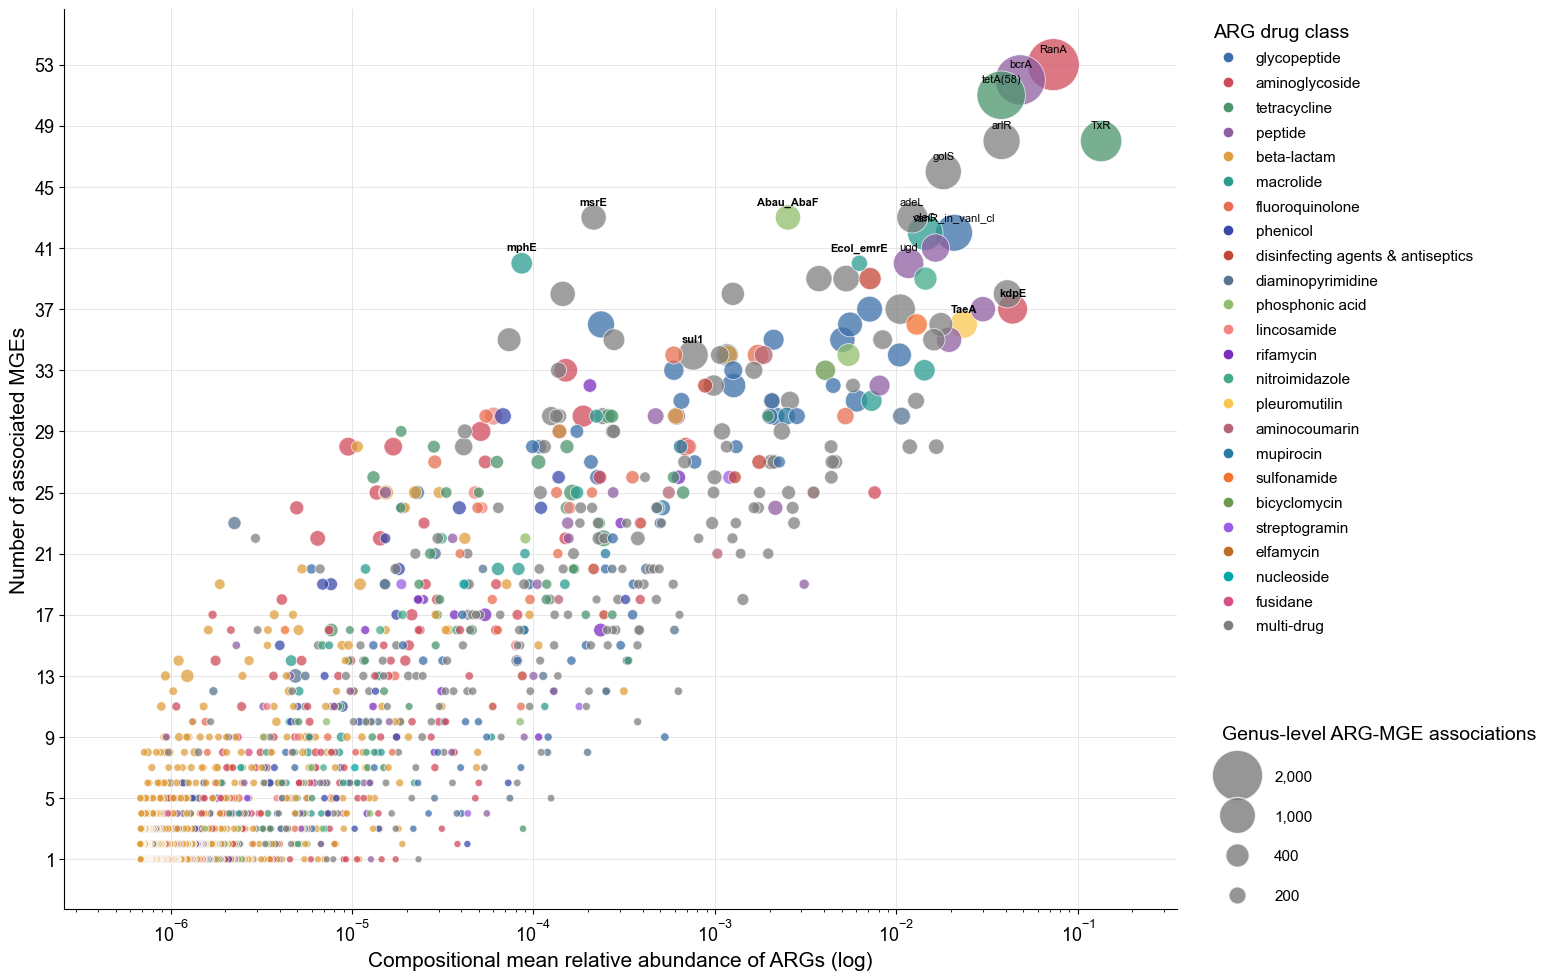

In [118]:
fig, ax = plot_arg_mge_bubble(arg_bubble_table, label_top_n=10, label_genes=["TaeA","kdpE", "sul1", "mphE", "msrE", "Ecol_emrE", "Abau_AbaF"])
save_bubble(fig, ax, "bubble_arg_abundance_vs_mge_count.png", dpi=150)
plt.show()

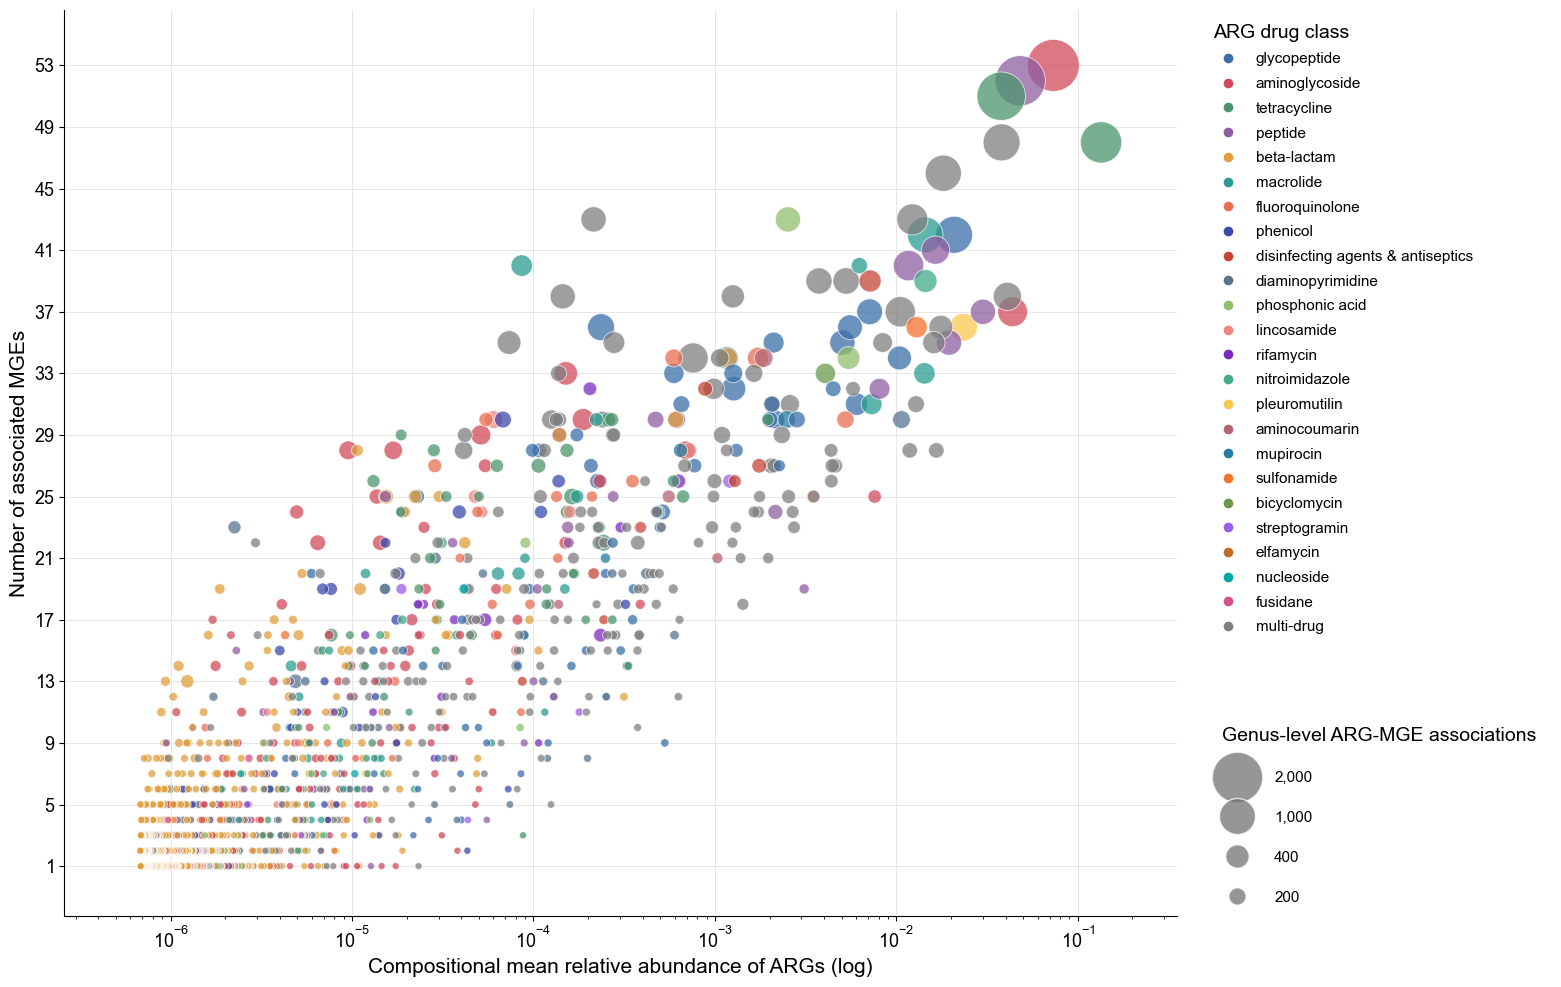

In [119]:
# all genes, no gene labels
fig, ax = plot_arg_mge_bubble(arg_bubble_table)
save_bubble(fig, ax, "bubble_arg_abundance_vs_mge_count_unlabeled.png", dpi=300)
plt.show()

In [120]:
# ARG distribution histograms
#   A  MGE breadth       - N_MGEs, distinct MGEs an ARG is ever found with; one bar per value
#   B  taxonomic breadth - N_Genera, distinct genera carrying the ARG on an MGE; bars of ten counts, with the long thin tail pooled into a final "100+" bar

HIST_COLOR = "#C19A6B" 
def _count_hist(ax, values, xlabel, width=1, clip_at=None):
   
    values = pd.Series(values).dropna().astype(float)
    if clip_at:
        values = values.clip(upper=clip_at)
    bins = np.arange(0.5, int(values.max()) + width + 0.5, width)
    counts, edges, _ = ax.hist(values, bins=bins, color=HIST_COLOR, edgecolor="white",
                               linewidth=0.8, zorder=3)

    if width > 1:
        every = max(1, int(np.ceil((len(edges) - 1) / 12)))
        ticks = list(edges[::every])
        if ticks[-1] != edges[-1]:
            ticks.append(edges[-1])
        labels = [f"{int(t - 0.5)}" for t in ticks]
        labels[0] = f"{int(ticks[0] + 0.5)}"    
        if clip_at:
            labels[-1] = f"{clip_at}+"
        ax.set_xticks(ticks)
        ax.set_xticklabels(labels)
    else:
        step = max(1, int(np.ceil(len(counts) / 20)))
        ax.set_xticks(np.arange(1, int(values.max()) + 1, step))

    ax.set_xlabel(xlabel, fontsize=13)
    ax.set_ylabel("Number of ARGs", fontsize=13)
    ax.tick_params(axis="both", which="both", labelsize=11)
    ax.grid(True, axis="y", color="0.9", linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

    
    hist_df = pd.DataFrame({"Bin_Start": edges[:-1], "Bin_End": edges[1:],
                            "N_ARGs": counts.astype(int)})
    hist_df["Count_Min"] = np.ceil(hist_df["Bin_Start"]).astype(int)
    hist_df["Count_Max"] = np.floor(hist_df["Bin_End"]).astype(float)
    if clip_at:
        hist_df.loc[hist_df.index[-1], ["Bin_End", "Count_Max"]] = np.inf
    hist_df["Range"] = [
        f"{lo}+" if np.isinf(hi) else (f"{lo}" if lo == hi else f"{lo}-{int(hi)}")
        for lo, hi in zip(hist_df["Count_Min"], hist_df["Count_Max"])
    ]
    hist_df["Pct_ARGs"] = 100 * hist_df["N_ARGs"] / len(values)
    return hist_df[["Range", "Count_Min", "Count_Max", "Bin_Start", "Bin_End",
                    "N_ARGs", "Pct_ARGs"]]


def plot_arg_mge_histograms(bubble_df):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    mge_hist = _count_hist(axes[0], bubble_df["N_MGEs"],
                           "Number of MGEs associated with the ARG")
    taxa_hist = _count_hist(axes[1], bubble_df["N_Genera"],
                            "Number of genera carrying the ARG and MGE", width=10, clip_at=100)
    for ax, letter in zip(axes, ("A", "B")):
        ax.annotate(letter, (-0.09, 1.06), xycoords="axes fraction",
                    fontsize=15, fontweight="bold", va="top")
    fig.tight_layout()
    return fig, axes, mge_hist, taxa_hist

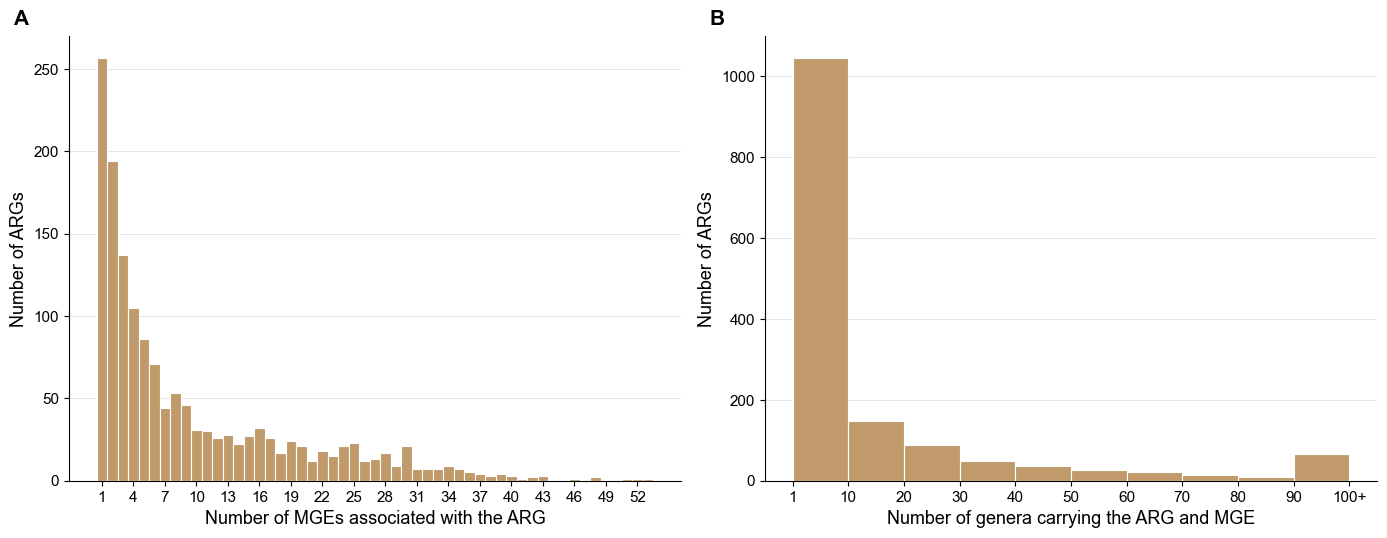

In [121]:
fig, axes, mge_breadth_hist, taxa_breadth_hist = plot_arg_mge_histograms(arg_bubble_table)
fig.savefig("hist_arg_mge_breadth.png", dpi=300, bbox_inches="tight")
plt.show()

mge_breadth_hist.to_csv("hist_arg_mge_breadth_n_mges.csv", index=False)
taxa_breadth_hist.to_csv("hist_arg_mge_breadth_n_genera.csv", index=False)

### Plasmid

In [122]:
def pick_best_plasmid_hit(row, max_evalue=1e-5, min_query_frac=0.5):
    # Among a read's plasmid hits, take the one with the lowest E-value, then require E <= max_evalue and an aligned region covering at least min_query_frac of the read.
    evalues = parse_list_column(row["plasmid_evalues"])
    coords = parse_list_column(row["plasmid_coords"])
    accessions = parse_list_column(row["plasmid_accessions"])
    query_length = row["query_length"]

    best = None
    for i, (ev, coord) in enumerate(zip(evalues, coords)):
        if pd.isna(ev) or not isinstance(coord, (list, tuple)) or len(coord) != 2:
            continue
        start, end = sorted(coord)
        aligned = end - start + 1
        if best is None or ev < best[0] or (ev == best[0] and aligned > best[1]):
            best = (ev, aligned, accessions[i] if i < len(accessions) else None)

    # reads with no plasmid hit at all (or no usable query_length) are not plasmid
    if best is None or pd.isna(query_length) or query_length <= 0:
        return (None, np.nan, np.nan, np.nan, False)

    ev, aligned, accession = best
    query_frac = aligned / query_length
    passes = bool(ev <= max_evalue and query_frac >= min_query_frac)
    return (accession, ev, aligned, query_frac, passes)


def label_putative_plasmids(df, max_evalue=1e-5, min_query_frac=0.5,
                            keep_cols=("query_name", "query_length", "Sample", "Genus", "arg_genes", "arg_class")):
    out = df[[c for c in keep_cols if c in df.columns]].copy()
    best = [
        pick_best_plasmid_hit(row, max_evalue=max_evalue, min_query_frac=min_query_frac)
        for row in df[["plasmid_evalues", "plasmid_coords", "plasmid_accessions", "query_length"]].to_dict("records")
    ]
    best_cols = ["best_plasmid_accession", "best_plasmid_evalue", "best_plasmid_aligned_len",
                 "best_plasmid_query_frac", "putative_plasmid"]
    out[best_cols] = pd.DataFrame(best, columns=best_cols, index=df.index)
    out["putative_plasmid"] = out["putative_plasmid"].astype(bool)
    return out

In [123]:
def explode_arg_hits(labelled_df, flag_col="putative_plasmid"):
    genes = labelled_df["arg_genes"].apply(parse_list_column)
    classes = labelled_df["arg_class"].apply(parse_list_column)
    pairs = [
        list(zip(g, list(c) + [None] * (len(g) - len(c))))
        for g, c in zip(genes, classes)
    ]
    hits = pd.DataFrame({
        "query_name": labelled_df["query_name"].values,
        flag_col: labelled_df[flag_col].values,
        "pairs": pairs,
    }).explode("pairs").dropna(subset=["pairs"])
    hits["ARG"] = hits["pairs"].str[0].astype(str).str.strip()
    hits["arg_class_raw"] = hits["pairs"].str[1]
    return hits.drop(columns="pairs").reset_index(drop=True)


def summarize_args_on_plasmids(labelled_df, hits, flag_col="putative_plasmid"):
    # One row per unit (reads, ARG hits, distinct ARG genes): total, how many are on
    # putative plasmid reads, and that as a percentage of the total.
    on = hits[flag_col]
    reads_on = labelled_df[flag_col]
    summary = pd.DataFrame(
        {
            "Total": [len(labelled_df), len(hits), hits["ARG"].nunique()],
            "Putative_Plasmid": [int(reads_on.sum()), int(on.sum()), hits.loc[on, "ARG"].nunique()],
        },
        index=pd.Index(["ARG reads", "ARG hits", "ARG genes"], name="Unit"),
    )
    summary["Pct_Putative_Plasmid"] = (100 * summary["Putative_Plasmid"] / summary["Total"]).round(2)
    return summary



def plasmid_arg_gene_table(hits, flag_col="putative_plasmid"):
    # Every ARG gene seen on at least one putative plasmid read, with how often it is plasmid-borne.
    table = hits.groupby("ARG").agg(
        Hits_Total=(flag_col, "size"),
        Hits_Putative_Plasmid=(flag_col, "sum"),
    )
    table["Reads_Putative_Plasmid"] = (
        hits[hits[flag_col]].groupby("ARG")["query_name"].nunique().reindex(table.index, fill_value=0)
    )
    table["Hits_Not_Plasmid"] = table["Hits_Total"] - table["Hits_Putative_Plasmid"]
    table["Pct_Hits_On_Plasmid"] = 100 * table["Hits_Putative_Plasmid"] / table["Hits_Total"]
    table = table[table["Hits_Putative_Plasmid"] > 0]
    cols = ["Hits_Putative_Plasmid", "Reads_Putative_Plasmid", "Hits_Not_Plasmid", "Hits_Total",
            "Pct_Hits_On_Plasmid"]
    return table[cols].sort_values(["Hits_Putative_Plasmid", "Pct_Hits_On_Plasmid"], ascending=False).reset_index()



In [124]:
PLASMID_MAX_EVALUE = 1e-5
PLASMID_MIN_QUERY_FRAC = 0.9

plasmid_labelled = label_putative_plasmids(
    filtered_df_mge_eval_threshold_with_IS_position,
    max_evalue=PLASMID_MAX_EVALUE,
    min_query_frac=PLASMID_MIN_QUERY_FRAC,
)
plasmid_arg_hits = explode_arg_hits(plasmid_labelled)

plasmid_arg_summary = summarize_args_on_plasmids(plasmid_labelled, plasmid_arg_hits)
plasmid_arg_summary.to_csv("putative_plasmid_arg_summary.csv")
plasmid_arg_summary

,Total,Putative_Plasmid,Pct_Putative_Plasmid
Unit,,,
ARG reads,3443876,315447,9.16
ARG hits,3938325,375431,9.53
ARG genes,2430,1222,50.29


In [125]:
plasmid_arg_genes = plasmid_arg_gene_table(plasmid_arg_hits)
plasmid_arg_genes.to_csv("putative_plasmid_arg_genes.csv", index=False)
print(f"{len(plasmid_arg_genes)} ARG genes on putative plasmid reads")
plasmid_arg_genes.head(30)

1222 ARG genes on putative plasmid reads


,ARG,Hits_Putative_Plasmid,Reads_Putative_Plasmid,Hits_Not_Plasmid,Hits_Total,Pct_Hits_On_Plasmid
0,RanA,30805,30270,244250,275055,11.199578
1,tetA(58),20853,20154,233592,254445,8.195484
2,TxR,19231,19181,225580,244811,7.855448
3,bcrA,12303,12216,203594,215897,5.698551
4,oleC,11100,10641,92882,103982,10.674925
5,adeL,8746,8640,32424,41170,21.243624
6,Abau_AbaF,5623,5621,25252,30875,18.212146
7,vanR_in_vanI_cl,4872,4872,104821,109693,4.441487
8,Kpne_OmpK37,4706,4706,2417,7123,66.067668
9,smeR,4614,4613,50950,55564,8.303938


In [126]:
# PLSDB (rgi/CARD) plasmid accession x ARG gene pairs
plsdb_arg_pairs_df = plsdb_arg_card.rename(columns={
    'NUCCORE_ACC': 'plasmid_accession',
    'gene_symbol': 'arg_gene',
})[[
    'plasmid_accession', 'arg_gene', 'gene_symbol2', 'gene_name',
    'drug_class', 'antimicrobial_agent',
    'input_gene_start', 'input_gene_stop', 'strand_orientation',
    'sequence_identity', 'coverage_percentage',
]].copy()
print(f"PLSDB ARG-on-plasmid records: {len(plsdb_arg_pairs_df)}")

# Deduplicated unique (plasmid accession, ARG gene) pairs -> reference set for comparison
plsdb_arg_unique_pairs = (
    plsdb_arg_pairs_df[['plasmid_accession', 'arg_gene']]
    .dropna(subset=['plasmid_accession', 'arg_gene'])
    .drop_duplicates()
    .sort_values(['plasmid_accession', 'arg_gene'])
    .reset_index(drop=True)
)
print(f"Unique PLSDB plasmid-accession x ARG pairs: {len(plsdb_arg_unique_pairs)}")

plsdb_arg_pairs_df.to_csv('./plsdb_arg_pairs.csv', index=False)
plsdb_arg_unique_pairs.to_csv('./plsdb_arg_unique_pairs.csv', index=False)

plsdb_arg_unique_pairs.head(15)

PLSDB ARG-on-plasmid records: 49218
Unique PLSDB plasmid-accession x ARG pairs: 46053


,plasmid_accession,arg_gene
0,AB576781.2,aadA
1,AB605179.1,aadA
2,AF128883.1,PC1 beta-lactamase (blaZ)
3,AJ297913.2,qacE
4,AJ639924.1,aadA3
5,AJ639924.1,cmlA5
6,AJ863570.1,qacG
7,AM261282.1,aadA8
8,AP011958.1,aadA2
9,AP011959.1,APH(3'')-Ib


#### Plasmid Accession and ARG Pairs (Gene Family)


In [127]:
def map_genes_to_families(genes, lookup):
    mapped, unmapped = {}, []
    for gene in genes:
        fams = resolve_gene_families(gene, lookup)
        if fams:
            mapped[gene] = fams
        else:
            unmapped.append(gene)
    return mapped, sorted(unmapped)


def genes_by_family(mapped):
    out = {}
    for gene, fams in mapped.items():
        for fam in fams:
            spelling, members = out.setdefault(fam.lower(), (fam, set()))
            members.add(gene)
    return {k: (spelling, sorted(members, key=str.lower)) for k, (spelling, members) in out.items()}


def family_vocabulary(card_df):
    return {
        f.strip().lower()
        for val in card_df['AMR Gene Family'].dropna()
        for f in str(val).split(';') if f.strip()
    }


# Samples are annotated against the current CARD (gene_family_lookup), PLSDB against
# CARD 3.2.9 (family_lookup_plsdb); both built in Drug Classes and CARD Metadata.
samples_genes = set(plasmid_arg_genes['ARG'].dropna().astype(str).str.strip())
plsdb_genes = set(plsdb_arg_unique_pairs['arg_gene'].dropna().astype(str).str.strip())

samples_gene_fams, unmapped_samples = map_genes_to_families(samples_genes, gene_family_lookup)
plsdb_gene_fams, unmapped_plsdb = map_genes_to_families(plsdb_genes, family_lookup_plsdb)
print(f"Genes without a CARD gene family (left out): "
      f"samples {len(unmapped_samples)} {unmapped_samples}, PLSDB {len(unmapped_plsdb)} {unmapped_plsdb}")

samples_families = genes_by_family(samples_gene_fams)
plsdb_families = genes_by_family(plsdb_gene_fams)

both_fams         = samples_families.keys() & plsdb_families.keys()
plsdb_only_fams   = plsdb_families.keys() - samples_families.keys()
samples_only_fams = samples_families.keys() - plsdb_families.keys()

print(f"Unique on-plasmid ARG genes in samples: {len(samples_genes)} -> {len(samples_families)} gene families")
print(f"Unique ARG genes in PLSDB:              {len(plsdb_genes)} -> {len(plsdb_families)} gene families")
print(f"In both:                                {len(both_fams)}")
print(f"PLSDB only:                             {len(plsdb_only_fams)}")
print(f"Samples only:                           {len(samples_only_fams)}")

vocab_current = family_vocabulary(df_card_merged)
vocab_plsdb = family_vocabulary(card_plsdb)

_no_family = (None, [])

family_overlap_df = pd.DataFrame(
    [
        {
            'amr_gene_family': (samples_families.get(key) or plsdb_families.get(key))[0],
            'category': category,
            'n_samples_genes': len(samples_families.get(key, _no_family)[1]),
            'n_plsdb_genes': len(plsdb_families.get(key, _no_family)[1]),
            'samples_genes': ";".join(samples_families.get(key, _no_family)[1]) or None,
            'plsdb_genes': ";".join(plsdb_families.get(key, _no_family)[1]) or None,
            'in_card_current': key in vocab_current,
            'in_card_3_2_9': key in vocab_plsdb,
        }
        for category, keys in [('Both', both_fams), ('PLSDB only', plsdb_only_fams),
                               ('Samples only', samples_only_fams)]
        for key in keys
    ]
).sort_values(['category', 'amr_gene_family'], key=lambda s: s.str.lower()).reset_index(drop=True)
family_overlap_df.to_csv('./plasmid_arg_family_overlap_samples_vs_plsdb.csv', index=False)

version_only = family_overlap_df[~(family_overlap_df['in_card_current'] & family_overlap_df['in_card_3_2_9'])]
print(f"\nOne-sided families absent from the other side's CARD version: {len(version_only)}")
print(version_only[['amr_gene_family', 'category', 'in_card_current', 'in_card_3_2_9']].to_string(index=False))

family_overlap_counts = (
    family_overlap_df['category'].value_counts()
    .reindex(['Both', 'PLSDB only', 'Samples only'])
    .rename_axis('category').reset_index(name='n_gene_families')
)
family_overlap_counts.to_csv('./plasmid_arg_family_overlap_counts.csv', index=False)
family_overlap_counts

Genes without a CARD gene family (left out): samples 0 [], PLSDB 0 []
Unique on-plasmid ARG genes in samples: 1222 -> 214 gene families
Unique ARG genes in PLSDB:              1078 -> 189 gene families
In both:                                137
PLSDB only:                             52
Samples only:                           77

One-sided families absent from the other side's CARD version: 25
                                                                      amr_gene_family     category  in_card_current  in_card_3_2_9
                23S rRNA with mutation conferring resistance to macrolide antibiotics   PLSDB only            False           True
                                                            antibiotic resistant fabI   PLSDB only            False           True
                                           antibiotic-resistant cya adenylate cyclase   PLSDB only            False           True
                                                            antibiotic-resista

,category,n_gene_families
0,Both,137
1,PLSDB only,52
2,Samples only,77
